In [1]:
#importar librerias

import pandas as pd
import numpy as np
import zipfile
import os


In [2]:
from google.colab import files

archivo_subido_2024 = files.upload()

Saving 2024.zip to 2024.zip


In [3]:
from google.colab import files

archivo_subido_2025 = files.upload()

Saving 2025.zip to 2025.zip


In [4]:
from google.colab import files

archivo_subido_2026 = files.upload()

Saving 2026.zip to 2026.zip


Consolidacion y depuracion de la base de datos

In [5]:
# CONSOLIDACIÓN DE LA BASE HISTÓRICA
# Enero 2024 - mayo 2026


datos_historicos = []

columnas_necesarias = [
    "CODIGO_PROPIO",
    "DES_MEDICAMENTO",
    "CANTIDAD",
    "BODEGA",
    "DES_UF",
    "MES",
    "AÑO"
]

def cargar_zip(ruta_zip):

    datos = []

    with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:

        archivos_excel = [
            archivo
            for archivo in archivo_zip.namelist()
            if archivo.lower().endswith(".xlsx")
        ]

        for archivo in archivos_excel:

            with archivo_zip.open(archivo) as archivo_excel:

                # Primero se lee el archivo completo
                df = pd.read_excel(archivo_excel)

                # Normalizar nombres de columnas
                df.columns = (
                    df.columns
                    .astype(str)
                    .str.strip()
                    .str.upper()
                )

                # Conservar únicamente las variables necesarias
                df = df[columnas_necesarias].copy()

                datos.append(df)

    return datos


# ============================================
# 2024
# ============================================

datos_2024 = cargar_zip("2024.zip")

print("Archivos 2024 cargados:", len(datos_2024))


# ============================================
# 2025
# ============================================

datos_2025 = cargar_zip("2025.zip")

print("Archivos 2025 cargados:", len(datos_2025))


# ============================================
# 2026
# ============================================

datos_2026 = cargar_zip("2026.zip")

print("Archivos 2026 cargados:", len(datos_2026))


# ============================================
# UNIFICACIÓN
# ============================================

datos_historicos = datos_2024 + datos_2025 + datos_2026

base_historica = pd.concat(
    datos_historicos,
    ignore_index=True
)

print(
    "Total de registros de la base histórica:",
    len(base_historica)
)

Archivos 2024 cargados: 12
Archivos 2025 cargados: 12
Archivos 2026 cargados: 5
Total de registros de la base histórica: 11625461


In [6]:
# Liberar memoria de las bases mensuales
del datos_2024
del datos_2025
del datos_2026
del datos_historicos

import gc
gc.collect()

print("Memoria temporal liberada.")
print("Registros en base_historica:", len(base_historica))

Memoria temporal liberada.
Registros en base_historica: 11625461


In [7]:
from google.colab import files

archivo_bodegas = files.upload()

Saving bodegas.xlsx to bodegas.xlsx


In [8]:
bodegas = pd.read_excel("bodegas.xlsx")

bodegas.columns = (
    bodegas.columns
    .astype(str)
    .str.strip()
)

print("Registros de la base de Bodegas:", len(bodegas))
print("Columnas:")
print(bodegas.columns.tolist())

bodegas.head()

Registros de la base de Bodegas: 37
Columnas:
['Bodega', 'Servicio', 'Servicio Farmaceutico', 'Sede', 'Se utiliza']


,Bodega,Servicio,Servicio Farmaceutico,Sede,Se utiliza
0,130,Priopios Prado,Cirugia Ambulatoria,Ambulatoria,Si
1,155,Regulados Prado,Cirugia Ambulatoria,Ambulatoria,Si
2,820,Hospitalizacion,Hospitalizacion,Principal,Si
3,821,Urgencias,Urgencias,Principal,Si
4,823,Prodiagnostico - Radiologia,Hospitalizacion,Principal,Si


In [9]:
# RELACIÓN BASE HISTÓRICA - BODEGAS


# Estandarizar el código de bodega en la base maestra
bodegas["BODEGA_KEY"] = (
    pd.to_numeric(bodegas["Bodega"], errors="coerce")
)

# Crear un mapa de código de bodega → condición de utilización
mapa_uso_bodega = (
    bodegas
    .drop_duplicates("BODEGA_KEY")
    .set_index("BODEGA_KEY")["Se utiliza"]
)

# Relacionar cada registro histórico con la condición
# de utilización de su bodega
bodega_key_historica = pd.to_numeric(
    base_historica["BODEGA"],
    errors="coerce"
)

uso_bodega = bodega_key_historica.map(mapa_uso_bodega)

# Verificar correspondencia
sin_clasificacion = uso_bodega.isna().sum()

print("Registros históricos sin clasificación de bodega:", sin_clasificacion)

# Contar registros según condición institucional
print("\nRegistros por condición de utilización:")
print(uso_bodega.value_counts(dropna=False))

Registros históricos sin clasificación de bodega: 0

Registros por condición de utilización:
BODEGA
Si                                                                                                                                                       11391780
Solo en esta bodega dejar la BOLSA EVA NUTRICION PARENTERAL 1000 ML - BOLSA EVA NUTRICION PARENTERAL 3000 ML - BOLSA EVA NUTRICION PARENTERAL 2000 ML      219897
No                                                                                                                                                          13784
Name: count, dtype: int64


In [10]:
# Productos registrados en la bodega 829
productos_829 = (
    base_historica[
        pd.to_numeric(base_historica["BODEGA"], errors="coerce") == 829
    ][
        ["CODIGO_PROPIO", "DES_MEDICAMENTO"]
    ]
    .drop_duplicates()
    .sort_values("DES_MEDICAMENTO")
)

print("Número de productos diferentes en bodega 829:", len(productos_829))

productos_829

Número de productos diferentes en bodega 829: 61


,CODIGO_PROPIO,DES_MEDICAMENTO
5794967,11483,BOLSA EVA NUTRICION PARENTERAL 1000 ML
6240,11483,BOLSA EVA NUTRICION PARENTERAL 1000 ML
6357,11515,BOLSA EVA NUTRICION PARENTERAL 3000 ML
786401,11482,BOLSA EVA NUTRICION PARENTERAL 500 ML.
5786841,11474,NPT ACIDO ASCORBICO ML (VITAMINA C)
...,...,...
493246,100006537,PREPARACION MEDICAMENTOS ESTERILES PEDIATRIA (...
493945,36689073,PREPARACION QUIMIOTERAPIA BOLSA X 1000 ML
492600,100017480,PREPARACION QUIMIOTERAPIA JERINGA
492603,100017479,PREPARACION QUIMIOTERAPIA MINIBOLSA


In [11]:
# Identificar las bolsas EVA de nutrición parenteral permitidas
# en la bodega 829

productos_permitidos_829 = productos_829[
    productos_829["DES_MEDICAMENTO"]
    .astype(str)
    .str.upper()
    .str.contains(
        "BOLSA EVA NUTRICION PARENTERAL",
        na=False
    )
]

productos_permitidos_829

,CODIGO_PROPIO,DES_MEDICAMENTO
5794967,11483,BOLSA EVA NUTRICION PARENTERAL 1000 ML
6240,11483,BOLSA EVA NUTRICION PARENTERAL 1000 ML
6357,11515,BOLSA EVA NUTRICION PARENTERAL 3000 ML
786401,11482,BOLSA EVA NUTRICION PARENTERAL 500 ML.
5960376,100017917,NPT BOLSA EVA NUTRICION PARENTERAL 2000 ML
5786852,11515,NPT BOLSA EVA NUTRICION PARENTERAL 3000 ML
5937679,11515,NPT BOLSA EVA NUTRICION PARENTERAL 3000 ML


In [13]:

# CRITERIOS DE DEPURACIÓN

# Normalizar descripción de los productos
descripcion = (
    base_historica["DES_MEDICAMENTO"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# 1. Productos precedidos por NPT
es_npt = descripcion.str.startswith("NPT")

# 2. Bodegas clasificadas institucionalmente como "No"
es_bodega_no = (
    uso_bodega
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("NO")
)

# 3. Identificar bodega 829
es_bodega_829 = (
    pd.to_numeric(
        base_historica["BODEGA"],
        errors="coerce"
    ) == 829
)

# 4. Productos permitidos en bodega 829
productos_permitidos_829 = [
    "BOLSA EVA NUTRICION PARENTERAL 500 ML",
    "BOLSA EVA NUTRICION PARENTERAL 1000 ML",
    "BOLSA EVA NUTRICION PARENTERAL 3000 ML"
]

es_producto_permitido_829 = descripcion.isin(
    productos_permitidos_829
)

# 5. En bodega 829 se excluyen los productos
# que no estén dentro de los permitidos
excluir_829 = (
    es_bodega_829 &
    ~es_producto_permitido_829
)

# 6. Criterio final de exclusión
# Un registro se elimina si:
# - pertenece a una bodega "No", O
# - es un producto NPT, O
# - pertenece a la bodega 829 pero no es un producto permitido.

excluir = (
    es_bodega_no |
    es_npt |
    excluir_829
)

# RESUMEN


print("Registros iniciales:", len(base_historica))
print("Bodegas clasificadas como No:", es_bodega_no.sum())
print("Productos NPT:", es_npt.sum())
print("Registros excluidos por regla de bodega 829:", excluir_829.sum())
print("Registros que cumplen algún criterio de exclusión:", excluir.sum())
print("Registros que permanecerían:", (~excluir).sum())

Registros iniciales: 11625461
Bodegas clasificadas como No: 13784
Productos NPT: 214144
Registros excluidos por regla de bodega 829: 208597
Registros que cumplen algún criterio de exclusión: 240553
Registros que permanecerían: 11384908


In [14]:
# COMPROBACIÓN DEL SOLAPAMIENTO DE CRITERIOS


print(
    "Bodega 829 - registros totales:",
    es_bodega_829.sum()
)

print(
    "Bodega 829 - registros permitidos:",
    (es_bodega_829 & es_producto_permitido_829).sum()
)

print(
    "Bodega 829 - registros excluidos:",
    excluir_829.sum()
)

print(
    "\nSolapamiento entre Bodega No y NPT:",
    (es_bodega_no & es_npt).sum()
)

print(
    "Solapamiento entre Bodega 829 y NPT:",
    (es_bodega_829 & es_npt).sum()
)

print(
    "Solapamiento entre Bodega 829 y Bodega No:",
    (es_bodega_829 & es_bodega_no).sum()
)

print(
    "\nRegistros que cumplen los 3 criterios:",
    (es_bodega_no & es_npt & es_bodega_829).sum()
)

Bodega 829 - registros totales: 219897
Bodega 829 - registros permitidos: 11300
Bodega 829 - registros excluidos: 208597

Solapamiento entre Bodega No y NPT: 0
Solapamiento entre Bodega 829 y NPT: 195972
Solapamiento entre Bodega 829 y Bodega No: 0

Registros que cumplen los 3 criterios: 0


In [15]:
# DEPURACIÓN DEFINITIVA DE LA BASE HISTÓRICA

registros_iniciales = len(base_historica)

# Aplicar los criterios de exclusión
base_historica = base_historica[
    ~excluir
].reset_index(drop=True)

registros_finales = len(base_historica)

print("Registros iniciales:", registros_iniciales)
print("Registros excluidos:", registros_iniciales - registros_finales)
print("Registros finales:", registros_finales)

Registros iniciales: 11625461
Registros excluidos: 240553
Registros finales: 11384908


In [16]:
# Liberar variables auxiliares utilizadas en la depuración

del uso_bodega
del bodega_key_historica
del mapa_uso_bodega
del descripcion
del es_npt
del es_bodega_no
del es_bodega_829
del es_producto_permitido_829
del excluir_829
del excluir

import gc
gc.collect()

print("Variables auxiliares liberadas.")
print("Base analítica final:", len(base_historica))

Variables auxiliares liberadas.
Base analítica final: 11384908


In [17]:
# CREACIÓN DE LA VARIABLE TEMPORAL PERIODO


orden_meses = {
    "ENERO": 1,
    "FEBRERO": 2,
    "MARZO": 3,
    "ABRIL": 4,
    "MAYO": 5,
    "JUNIO": 6,
    "JULIO": 7,
    "AGOSTO": 8,
    "SEPTIEMBRE": 9,
    "OCTUBRE": 10,
    "NOVIEMBRE": 11,
    "DICIEMBRE": 12
}

# Convertir el nombre del mes a número
base_historica["MES_NUMERO"] = (
    base_historica["MES"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map(orden_meses)
)

# Crear una fecha representativa del primer día de cada mes
base_historica["PERIODO"] = pd.to_datetime(
    base_historica["AÑO"].astype(int).astype(str)
    + "-"
    + base_historica["MES_NUMERO"].astype(int).astype(str)
    + "-01"
)

print("Variable PERIODO creada correctamente.")
print("Período inicial:", base_historica["PERIODO"].min())
print("Período final:", base_historica["PERIODO"].max())
print("Períodos únicos:", base_historica["PERIODO"].nunique())

Variable PERIODO creada correctamente.
Período inicial: 2024-01-01 00:00:00
Período final: 2026-05-01 00:00:00
Períodos únicos: 29


In [18]:
# CONSUMO TOTAL POR PERIODO


consumo_mensual = (
    base_historica
    .groupby("PERIODO")["CANTIDAD"]
    .sum()
    .reset_index()
    .sort_values("PERIODO")
)

print("Número de períodos analizados:", len(consumo_mensual))

consumo_mensual

Número de períodos analizados: 29


,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [19]:
# RESUMEN DEL COMPORTAMIENTO TEMPORAL


# Estadísticos generales del consumo mensual
resumen_temporal = pd.DataFrame({
    "Indicador": [
        "Consumo mensual mínimo",
        "Consumo mensual máximo",
        "Promedio mensual"
    ],
    "Valor": [
        consumo_mensual["CANTIDAD"].min(),
        consumo_mensual["CANTIDAD"].max(),
        consumo_mensual["CANTIDAD"].mean()
    ]
})

print("RESUMEN GENERAL")
resumen_temporal

RESUMEN GENERAL


,Indicador,Valor
0,Consumo mensual mínimo,1.153981e+06
1,Consumo mensual máximo,3.426907e+07
2,Promedio mensual,9.429090e+06


In [20]:
# CONSUMO TOTAL Y PROMEDIO POR AÑO


consumo_anual = (
    consumo_mensual
    .assign(AÑO=consumo_mensual["PERIODO"].dt.year)
    .groupby("AÑO")["CANTIDAD"]
    .agg(
        Consumo_total="sum",
        Promedio_mensual="mean"
    )
    .reset_index()
)

consumo_anual

,AÑO,Consumo_total,Promedio_mensual
0,2024,24330665.0,2.027555e+06
1,2025,105435473.0,8.786289e+06
2,2026,143677479.0,2.873550e+07


In [21]:
# VARIACIÓN DEL CONSUMO ANUAL


consumo_anual["Variacion_%"] = (
    consumo_anual["Consumo_total"]
    .pct_change()
    .mul(100)
)

consumo_anual

,AÑO,Consumo_total,Promedio_mensual,Variacion_%
0,2024,24330665.0,2.027555e+06,NaN
1,2025,105435473.0,8.786289e+06,333.343984
2,2026,143677479.0,2.873550e+07,36.270531


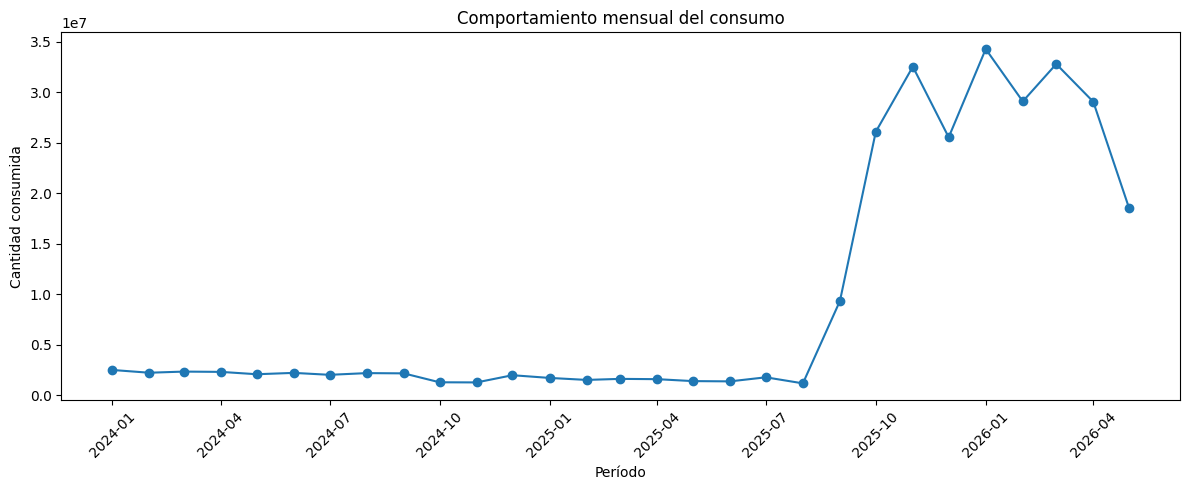

In [22]:
import matplotlib.pyplot as plt


# GRÁFICA DEL COMPORTAMIENTO TEMPORAL


plt.figure(figsize=(12, 5))

plt.plot(
    consumo_mensual["PERIODO"],
    consumo_mensual["CANTIDAD"],
    marker="o"
)

plt.title("Comportamiento mensual del consumo")
plt.xlabel("Período")
plt.ylabel("Cantidad consumida")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [23]:
# IDENTIFICACIÓN DEL CAMBIO MÁS MARCADO

consumo_mensual["Variacion_mensual_%"] = (
    consumo_mensual["CANTIDAD"]
    .pct_change()
    .mul(100)
)

# Mostrar los meses con mayores aumentos y disminuciones
cambios_mensuales = (
    consumo_mensual[
        ["PERIODO", "CANTIDAD", "Variacion_mensual_%"]
    ]
    .sort_values("Variacion_mensual_%", ascending=False)
)

cambios_mensuales.head(5)

,PERIODO,CANTIDAD,Variacion_mensual_%
20,2025-09-01,9314067.0,707.124814
21,2025-10-01,26075524.0,179.958519
11,2024-12-01,1960629.0,57.175107
24,2026-01-01,34269070.0,34.229729
18,2025-07-01,1753741.0,29.833265


In [24]:
print("Meses con mayores disminuciones:")

cambios_mensuales.tail(5)

Meses con mayores disminuciones:


,PERIODO,CANTIDAD,Variacion_mensual_%
23,2025-12-01,25530164.0,-21.505016
19,2025-08-01,1153981.0,-34.198893
28,2026-05-01,18494797.0,-36.322083
9,2024-10-01,1260366.0,-41.230034
0,2024-01-01,2482230.0,NaN


In [25]:
# VALIDACIÓN DE CANTIDADES NULAS O NEGATIVAS


registros_no_positivos = base_historica[
    base_historica["CANTIDAD"] <= 0
]

print(
    "Registros con cantidad cero o negativa:",
    len(registros_no_positivos)
)

print(
    "Registros con cantidad negativa:",
    (base_historica["CANTIDAD"] < 0).sum()
)

print(
    "Registros con cantidad igual a cero:",
    (base_historica["CANTIDAD"] == 0).sum()
)

Registros con cantidad cero o negativa: 68
Registros con cantidad negativa: 68
Registros con cantidad igual a cero: 0


In [26]:
registros_no_positivos[
    [
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        "CANTIDAD",
        "BODEGA",
        "DES_UF",
        "MES",
        "AÑO"
    ]
].sort_values(
    ["AÑO", "MES", "CANTIDAD"]
)

,CODIGO_PROPIO,DES_MEDICAMENTO,CANTIDAD,BODEGA,DES_UF,MES,AÑO
6364380,36768,BAJALENGUAS NO ESTERIL CAJA X 100 UNIDADES,-100.0,885,Consulta Externa Otorrino - Bloque 1 - Piso 2,Agosto,2025
6364381,3466,MASCARILLA FACIAL DESECHABLE RESORTADA,-50.0,885,Consulta Externa Otorrino - Bloque 1 - Piso 2,Agosto,2025
6364425,225448,CUCHILLA QUIRURGICA PARA MAQUINA CLIPPER INALA...,-10.0,885,Cirugia - Bloque 3 - Piso 5,Agosto,2025
6369256,6086,VENDA ALGODON LAMINADO 3 X 5 YARDAS,-4.0,885,Servicio Transfusional - Bloque 1 - Piso 1,Agosto,2025
7800171,100004768,PAPEL DESFIBRILADOR MINDRAY BENEHEART D3 ROLLO...,-1.0,885,UCI Cardiovascular - Bloque 3 - Piso 7,Julio,2025
...,...,...,...,...,...,...,...
11378627,212,AGUA ESTERIL SOLUCION INYECTABLE 500 ML,-15.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11372019,9403,JERINGA DESECHABLE 10 ML 21G X 1 1/2,-10.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11372020,10332,DEXTROSA EN AGUA DESTILADA 50% SOLUCION INYECT...,-10.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11383014,36768,BAJALENGUAS NO ESTERIL CAJA X 100 UNIDADES,-6.0,885,Camillas SAI Adultos - Bloque 3 - Urgencias,Mayo,2026


In [27]:
# REVISIÓN DE LOS REGISTROS CON CANTIDAD NEGATIVA


registros_negativos = base_historica[
    base_historica["CANTIDAD"] < 0
][
    [
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        "CANTIDAD",
        "BODEGA",
        "DES_UF",
        "MES",
        "AÑO"
    ]
].sort_values(
    ["AÑO", "MES", "CANTIDAD"]
)

print("Número de registros negativos:", len(registros_negativos))

registros_negativos

Número de registros negativos: 68


,CODIGO_PROPIO,DES_MEDICAMENTO,CANTIDAD,BODEGA,DES_UF,MES,AÑO
6364380,36768,BAJALENGUAS NO ESTERIL CAJA X 100 UNIDADES,-100.0,885,Consulta Externa Otorrino - Bloque 1 - Piso 2,Agosto,2025
6364381,3466,MASCARILLA FACIAL DESECHABLE RESORTADA,-50.0,885,Consulta Externa Otorrino - Bloque 1 - Piso 2,Agosto,2025
6364425,225448,CUCHILLA QUIRURGICA PARA MAQUINA CLIPPER INALA...,-10.0,885,Cirugia - Bloque 3 - Piso 5,Agosto,2025
6369256,6086,VENDA ALGODON LAMINADO 3 X 5 YARDAS,-4.0,885,Servicio Transfusional - Bloque 1 - Piso 1,Agosto,2025
7800171,100004768,PAPEL DESFIBRILADOR MINDRAY BENEHEART D3 ROLLO...,-1.0,885,UCI Cardiovascular - Bloque 3 - Piso 7,Julio,2025
...,...,...,...,...,...,...,...
11378627,212,AGUA ESTERIL SOLUCION INYECTABLE 500 ML,-15.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11372019,9403,JERINGA DESECHABLE 10 ML 21G X 1 1/2,-10.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11372020,10332,DEXTROSA EN AGUA DESTILADA 50% SOLUCION INYECT...,-10.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11383014,36768,BAJALENGUAS NO ESTERIL CAJA X 100 UNIDADES,-6.0,885,Camillas SAI Adultos - Bloque 3 - Urgencias,Mayo,2026


In [28]:
# IMPACTO DE LOS REGISTROS NEGATIVOS


cantidad_negativa = (
    registros_negativos["CANTIDAD"].sum()
)

cantidad_abs_negativa = (
    registros_negativos["CANTIDAD"].abs().sum()
)

print("Registros negativos:", len(registros_negativos))
print("Cantidad neta de movimientos negativos:", cantidad_negativa)
print("Cantidad absoluta asociada a negativos:", cantidad_abs_negativa)

Registros negativos: 68
Cantidad neta de movimientos negativos: -2545.0
Cantidad absoluta asociada a negativos: 2545.0


In [29]:
# REGISTROS NEGATIVOS POR AÑO


negativos_por_año = (
    registros_negativos
    .groupby("AÑO")["CANTIDAD"]
    .agg(
        Registros="count",
        Cantidad_neta="sum"
    )
    .reset_index()
)

negativos_por_año

,AÑO,Registros,Cantidad_neta
0,2025,37,-1346.0
1,2026,31,-1199.0


In [30]:
# DEPURACIÓN DE ERRORES DE CANTIDAD NEGATIVA


registros_antes_negativos = len(base_historica)

# Eliminar registros con cantidades negativas
base_historica = base_historica[
    base_historica["CANTIDAD"] > 0
].reset_index(drop=True)

registros_despues_negativos = len(base_historica)

print("Registros antes de eliminar negativos:",
      registros_antes_negativos)

print("Registros negativos eliminados:",
      registros_antes_negativos - registros_despues_negativos)

print("Registros finales de la base analítica:",
      registros_despues_negativos)

Registros antes de eliminar negativos: 11384908
Registros negativos eliminados: 69
Registros finales de la base analítica: 11384839


In [31]:
# ELIMINAR LOS 68 REGISTROS CON ERROR


registros_antes = len(base_historica)

base_historica = base_historica[
    base_historica["CANTIDAD"] > 0
].reset_index(drop=True)

registros_despues = len(base_historica)

print("Registros antes:", registros_antes)
print("Registros eliminados:", registros_antes - registros_despues)
print("Registros finales:", registros_despues)

Registros antes: 11384839
Registros eliminados: 0
Registros finales: 11384839


In [32]:
# VERIFICACIÓN FINAL DE CANTIDADES


print("Registros actuales:", len(base_historica))

print(
    "Registros con cantidad negativa:",
    (base_historica["CANTIDAD"] < 0).sum()
)

print(
    "Registros con cantidad igual a cero:",
    (base_historica["CANTIDAD"] == 0).sum()
)

print(
    "Registros con cantidad positiva:",
    (base_historica["CANTIDAD"] > 0).sum()
)

Registros actuales: 11384839
Registros con cantidad negativa: 0
Registros con cantidad igual a cero: 0
Registros con cantidad positiva: 11384839


In [33]:
# CONSUMO MENSUAL SOBRE LA BASE DEFINITIVA


consumo_mensual = (
    base_historica
    .groupby("PERIODO")["CANTIDAD"]
    .sum()
    .reset_index()
    .sort_values("PERIODO")
)

print("Registros de la base analítica:", len(base_historica))
print("Períodos analizados:", len(consumo_mensual))

consumo_mensual

Registros de la base analítica: 11384839
Períodos analizados: 29


,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [34]:
# RESUMEN TEMPORAL DEFINITIVO


resumen_temporal = pd.DataFrame({
    "Indicador": [
        "Consumo mensual mínimo",
        "Consumo mensual máximo",
        "Promedio mensual"
    ],
    "Valor": [
        consumo_mensual["CANTIDAD"].min(),
        consumo_mensual["CANTIDAD"].max(),
        consumo_mensual["CANTIDAD"].mean()
    ]
})

resumen_temporal

,Indicador,Valor
0,Consumo mensual mínimo,1154145.0
1,Consumo mensual máximo,34269070.0
2,Promedio mensual,9429178.0


In [35]:
# CONSUMO TOTAL Y PROMEDIO POR AÑO
# BASE ANALÍTICA DEFINITIVA


consumo_anual = (
    consumo_mensual
    .assign(AÑO=consumo_mensual["PERIODO"].dt.year)
    .groupby("AÑO")["CANTIDAD"]
    .agg(
        Consumo_total="sum",
        Promedio_mensual="mean"
    )
    .reset_index()
)

consumo_anual

,AÑO,Consumo_total,Promedio_mensual
0,2024,24330665.0,2.027555e+06
1,2025,105436819.0,8.786402e+06
2,2026,143678678.0,2.873574e+07


In [36]:
# VALIDACIÓN DE LA CANTIDAD POR AÑO

validacion_cantidad = (
    base_historica
    .assign(AÑO_REAL=base_historica["PERIODO"].dt.year)
    .groupby("AÑO_REAL")["CANTIDAD"]
    .agg(
        Registros="count",
        Cantidad_total="sum",
        Cantidad_minima="min",
        Cantidad_maxima="max",
        Cantidad_promedio="mean"
    )
    .reset_index()
)

validacion_cantidad

,AÑO_REAL,Registros,Cantidad_total,Cantidad_minima,Cantidad_maxima,Cantidad_promedio
0,2024,5670011,24330665.0,1.0,19150.0,4.291114
1,2025,4293140,105436819.0,1.0,72900.0,24.559371
2,2026,1421688,143678678.0,1.0,72000.0,101.062032


In [37]:
# DISTRIBUCIÓN DE CANTIDAD - 2024


base_2024 = base_historica[
    base_historica["PERIODO"].dt.year == 2024
]

print("Registros 2024:", len(base_2024))
print("Cantidad total 2024:", base_2024["CANTIDAD"].sum())
print("Cantidad promedio por registro:", base_2024["CANTIDAD"].mean())
print("Cantidad máxima:", base_2024["CANTIDAD"].max())

base_2024["CANTIDAD"].describe()

Registros 2024: 5670011
Cantidad total 2024: 24330665.0
Cantidad promedio por registro: 4.291114250042901
Cantidad máxima: 19150.0


,CANTIDAD
count,5.670011e+06
mean,4.291114e+00
std,4.572760e+01
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,2.000000e+00
max,1.915000e+04


In [38]:
# COMPARACIÓN DE LA DISTRIBUCIÓN DE CANTIDAD
# POR AÑO

distribucion_cantidad = (
    base_historica
    .assign(AÑO_REAL=base_historica["PERIODO"].dt.year)
    .groupby("AÑO_REAL")["CANTIDAD"]
    .agg(
        Registros="count",
        Cantidad_1="sum",
        Promedio="mean",
        Mediana="median",
        P75=lambda x: x.quantile(0.75),
        P90=lambda x: x.quantile(0.90),
        P95=lambda x: x.quantile(0.95),
        Máximo="max"
    )
    .reset_index()
)

distribucion_cantidad

,AÑO_REAL,Registros,Cantidad_1,Promedio,Mediana,P75,P90,P95,Máximo
0,2024,5670011,24330665.0,4.291114,1.0,2.0,3.0,4.0,19150.0
1,2025,4293140,105436819.0,24.559371,1.0,2.0,3.0,5.0,72900.0
2,2026,1421688,143678678.0,101.062032,1.0,2.0,3.0,5.0,72000.0


In [39]:
# DISTRIBUCIÓN DE CANTIDAD POR AÑO


distribucion_cantidad = (
    base_historica
    .assign(AÑO_REAL=base_historica["PERIODO"].dt.year)
    .groupby("AÑO_REAL")["CANTIDAD"]
    .agg(
        Registros="count",
        Promedio="mean",
        Mediana="median",
        P75=lambda x: x.quantile(0.75),
        P90=lambda x: x.quantile(0.90),
        P95=lambda x: x.quantile(0.95),
        Máximo="max"
    )
    .reset_index()
)

distribucion_cantidad

,AÑO_REAL,Registros,Promedio,Mediana,P75,P90,P95,Máximo
0,2024,5670011,4.291114,1.0,2.0,3.0,4.0,19150.0
1,2025,4293140,24.559371,1.0,2.0,3.0,5.0,72900.0
2,2026,1421688,101.062032,1.0,2.0,3.0,5.0,72000.0


In [40]:
# PROPORCIÓN DE REGISTROS CON CANTIDAD = 1


cantidad_uno = (
    base_historica
    .assign(
        AÑO_REAL=base_historica["PERIODO"].dt.year,
        ES_UNO=base_historica["CANTIDAD"] == 1
    )
    .groupby("AÑO_REAL")["ES_UNO"]
    .agg(
        Registros="count",
        Registros_cantidad_1="sum"
    )
    .reset_index()
)

cantidad_uno["Porcentaje_cantidad_1"] = (
    cantidad_uno["Registros_cantidad_1"]
    / cantidad_uno["Registros"]
    * 100
)

cantidad_uno

,AÑO_REAL,Registros,Registros_cantidad_1,Porcentaje_cantidad_1
0,2024,5670011,4121376,72.687266
1,2025,4293140,3035769,70.712090
2,2026,1421688,994201,69.931026


In [41]:
# IDENTIFICACIÓN DE VALORES EXTREMOS


valores_extremos = (
    base_historica[
        base_historica["CANTIDAD"] >= 1000
    ][
        [
            "CODIGO_PROPIO",
            "DES_MEDICAMENTO",
            "CANTIDAD",
            "BODEGA",
            "DES_UF",
            "MES",
            "AÑO"
        ]
    ]
    .sort_values("CANTIDAD", ascending=False)
)

print("Registros con cantidad >= 1000:", len(valores_extremos))

valores_extremos.head(30)

Registros con cantidad >= 1000: 46119


,CODIGO_PROPIO,DES_MEDICAMENTO,CANTIDAD,BODEGA,DES_UF,MES,AÑO
9863432,100020287,OXIGENO MEDICINAL,72900.0,820,Piso 4 Medicina Interna Sur - Bloque 1 - Piso 4,Septiembre,2025
11219497,100020287,OXIGENO MEDICINAL,72000.0,820,UCI Cardiovascular - Bloque 3 - Piso 7,Mayo,2026
8851432,100020287,OXIGENO MEDICINAL,72000.0,820,Piso 5 UCI - Bloque 3 - Piso 5,Noviembre,2025
10444006,100020287,OXIGENO MEDICINAL,72000.0,820,Piso 5 UCI - Bloque 3 - Piso 5,Enero,2026
11179040,100020287,OXIGENO MEDICINAL,72000.0,820,UCI Cardiovascular - Bloque 3 - Piso 7,Mayo,2026
10059035,100020287,OXIGENO MEDICINAL,72000.0,820,Piso 3 Pediatría - Bloque 3 - Piso 3,ABRIL,2026
10591817,100020287,OXIGENO MEDICINAL,72000.0,820,Piso 5 UCI - Bloque 3 - Piso 5,Febrero,2026
11181904,100020287,OXIGENO MEDICINAL,72000.0,820,UCI Cardiovascular - Bloque 3 - Piso 7,Mayo,2026
11109463,100020287,OXIGENO MEDICINAL,72000.0,820,Camillas SAI Pediatria - Bloque 3 - Piso 1,MARZO,2026
10006962,100020287,OXIGENO MEDICINAL,72000.0,820,Piso 3 Pediatría - Bloque 3 - Piso 3,ABRIL,2026


In [42]:
# IDENTIFICACIÓN DEL OXÍGENO MEDICINAL


codigo_oxigeno = "100020287"

registros_oxigeno = base_historica[
    base_historica["CODIGO_PROPIO"].astype(str).str.strip()
    == codigo_oxigeno
]

print("Registros de oxígeno medicinal:", len(registros_oxigeno))
print("Cantidad total de oxígeno:", registros_oxigeno["CANTIDAD"].sum())

oxigeno_por_año = (
    registros_oxigeno
    .assign(AÑO_REAL=registros_oxigeno["PERIODO"].dt.year)
    .groupby("AÑO_REAL")["CANTIDAD"]
    .agg(
        Registros="count",
        Cantidad_total="sum"
    )
    .reset_index()
)

oxigeno_por_año

Registros de oxígeno medicinal: 43153
Cantidad total de oxígeno: 225454468.0


,AÑO_REAL,Registros,Cantidad_total
0,2025,16382,87734382.0
1,2026,26771,137720086.0


In [43]:
# EXCLUSIÓN DEL OXÍGENO MEDICINAL
# GESTIONADO POR BIOMÉDICA


registros_antes_oxigeno = len(base_historica)

base_historica = base_historica[
    base_historica["CODIGO_PROPIO"].astype(str).str.strip()
    != codigo_oxigeno
].reset_index(drop=True)

registros_despues_oxigeno = len(base_historica)

print("Registros antes:", registros_antes_oxigeno)
print(
    "Registros de oxígeno excluidos:",
    registros_antes_oxigeno - registros_despues_oxigeno
)
print("Registros finales:", registros_despues_oxigeno)

Registros antes: 11384839
Registros de oxígeno excluidos: 43153
Registros finales: 11341686


In [44]:
# VERIFICACIÓN DE LA EXCLUSIÓN DEL OXÍGENO


oxigeno_restante = base_historica[
    base_historica["CODIGO_PROPIO"].astype(str).str.strip()
    == codigo_oxigeno
]

print("Registros de oxígeno restantes:", len(oxigeno_restante))
print("Registros finales de la base:", len(base_historica))

Registros de oxígeno restantes: 0
Registros finales de la base: 11341686


In [45]:
# CONSUMO MENSUAL DE LA BASE DEPURADA
# SIN OXÍGENO MEDICINAL


consumo_mensual = (
    base_historica
    .groupby("PERIODO")["CANTIDAD"]
    .sum()
    .reset_index()
    .sort_values("PERIODO")
)

print("Registros de la base analítica:", len(base_historica))
print("Períodos analizados:", len(consumo_mensual))

consumo_mensual

Registros de la base analítica: 11341686
Períodos analizados: 29


,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [46]:
# 8.1.6 COMPORTAMIENTO TEMPORAL DEL CONSUMO
# CONSUMO MENSUAL DE LA BASE ANALÍTICA FINAL


consumo_mensual = (
    base_historica
    .groupby("PERIODO")["CANTIDAD"]
    .sum()
    .reset_index()
    .sort_values("PERIODO")
)

print("Registros de la base analítica:", len(base_historica))
print("Períodos analizados:", len(consumo_mensual))

consumo_mensual

Registros de la base analítica: 11341686
Períodos analizados: 29


,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [47]:
# RESUMEN DEL COMPORTAMIENTO MENSUAL
# BASE ANALÍTICA FINAL

resumen_temporal = pd.DataFrame({
    "Indicador": [
        "Consumo mensual mínimo",
        "Consumo mensual máximo",
        "Promedio mensual"
    ],
    "Valor": [
        consumo_mensual["CANTIDAD"].min(),
        consumo_mensual["CANTIDAD"].max(),
        consumo_mensual["CANTIDAD"].mean()
    ]
})

resumen_temporal

,Indicador,Valor
0,Consumo mensual mínimo,584406.0
1,Consumo mensual máximo,2482230.0
2,Promedio mensual,1654886.0


In [48]:
# CONSUMO TOTAL Y PROMEDIO MENSUAL POR AÑO
# BASE ANALÍTICA FINAL

consumo_anual = (
    consumo_mensual
    .assign(AÑO=consumo_mensual["PERIODO"].dt.year)
    .groupby("AÑO")["CANTIDAD"]
    .agg(
        Consumo_total="sum",
        Promedio_mensual="mean"
    )
    .reset_index()
)

consumo_anual

,AÑO,Consumo_total,Promedio_mensual
0,2024,24330665.0,2.027555e+06
1,2025,17702437.0,1.475203e+06
2,2026,5958592.0,1.191718e+06


In [49]:
# COMPARACIÓN DE PERÍODOS EQUIVALENTES
# ENERO - MAYO

consumo_ene_may = (
    consumo_mensual[
        consumo_mensual["PERIODO"].dt.month <= 5
    ]
    .assign(AÑO=consumo_mensual["PERIODO"].dt.year)
    .groupby("AÑO")["CANTIDAD"]
    .agg(
        Consumo_total="sum",
        Promedio_mensual="mean"
    )
    .reset_index()
)

consumo_ene_may

,AÑO,Consumo_total,Promedio_mensual
0,2024,11357126.0,2271425.2
1,2025,7732652.0,1546530.4
2,2026,5958592.0,1191718.4


In [50]:
# VARIACIÓN DEL CONSUMO EN PERÍODOS EQUIVALENTES

comparacion_ene_may = consumo_ene_may.copy()

comparacion_ene_may["Variacion_%"] = (
    comparacion_ene_may["Consumo_total"]
    .pct_change()
    .mul(100)
)

comparacion_ene_may

,AÑO,Consumo_total,Promedio_mensual,Variacion_%
0,2024,11357126.0,2271425.2,NaN
1,2025,7732652.0,1546530.4,-31.913655
2,2026,5958592.0,1191718.4,-22.942452


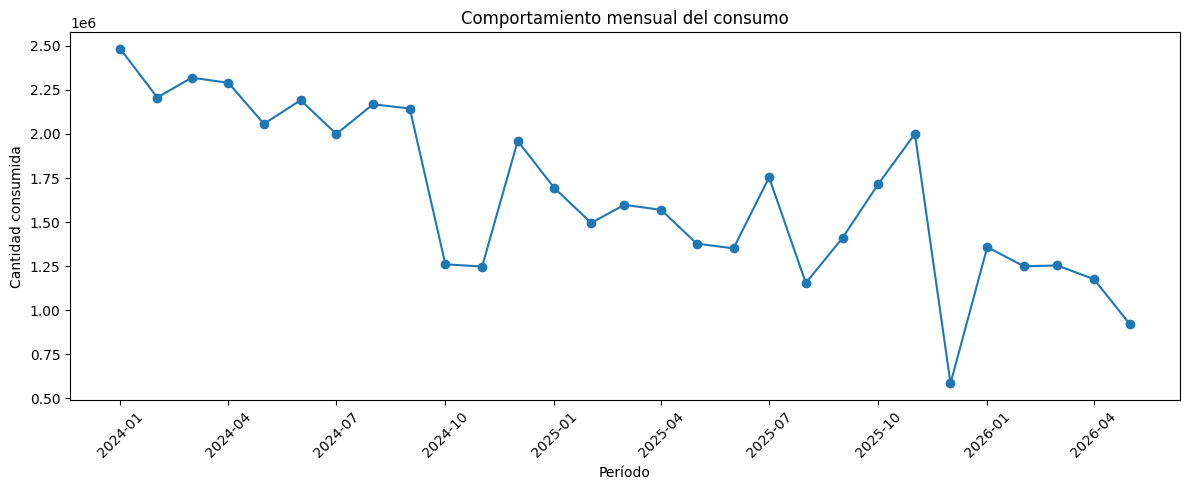

In [51]:
# GRÁFICA DEL COMPORTAMIENTO TEMPORAL


import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    consumo_mensual["PERIODO"],
    consumo_mensual["CANTIDAD"],
    marker="o"
)

plt.title("Comportamiento mensual del consumo")
plt.xlabel("Período")
plt.ylabel("Cantidad consumida")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [52]:
# IDENTIFICACIÓN DE CAMBIOS MENSUALES


cambios_mensuales = consumo_mensual.copy()

cambios_mensuales["Variacion_%"] = (
    cambios_mensuales["CANTIDAD"]
    .pct_change()
    .mul(100)
)

cambios_mensuales

,PERIODO,CANTIDAD,Variacion_%
0,2024-01-01,2482230.0,NaN
1,2024-02-01,2207099.0,-11.084025
2,2024-03-01,2319645.0,5.099273
3,2024-04-01,2290629.0,-1.250881
4,2024-05-01,2057523.0,-10.176506
5,2024-06-01,2192225.0,6.546804
6,2024-07-01,1999628.0,-8.785458
7,2024-08-01,2168699.0,8.455123
8,2024-09-01,2144575.0,-1.112372
9,2024-10-01,1260366.0,-41.230034


In [53]:
# CAMBIOS MENSUALES MÁS MARCADOS

# Mayores incrementos
mayores_aumentos = (
    cambios_mensuales[
        cambios_mensuales["Variacion_%"].notna()
    ]
    .sort_values("Variacion_%", ascending=False)
    .head(5)
)

# Mayores disminuciones
mayores_disminuciones = (
    cambios_mensuales[
        cambios_mensuales["Variacion_%"].notna()
    ]
    .sort_values("Variacion_%", ascending=True)
    .head(5)
)

print("MAYORES AUMENTOS MENSUALES")
print(mayores_aumentos)

print("\nMAYORES DISMINUCIONES MENSUALES")
print(mayores_disminuciones)

MAYORES AUMENTOS MENSUALES
      PERIODO   CANTIDAD  Variacion_%
24 2026-01-01  1358026.0   132.377149
11 2024-12-01  1960629.0    57.175107
18 2025-07-01  1753752.0    29.834079
20 2025-09-01  1410743.0    22.232735
21 2025-10-01  1714964.0    21.564594

MAYORES DISMINUCIONES MENSUALES
      PERIODO   CANTIDAD  Variacion_%
23 2025-12-01   584406.0   -70.794463
9  2024-10-01  1260366.0   -41.230034
19 2025-08-01  1154145.0   -34.189954
28 2026-05-01   922393.0   -21.543539
12 2025-01-01  1692443.0   -13.678569


In [54]:
# COMPORTAMIENTO DEL CONSUMO
# POR SERVICIO FARMACÉUTICO


# Validar la relación Bodega - Servicio Farmacéutico

bodegas_validacion = (
    bodegas[
        ["Bodega", "Servicio Farmaceutico"]
    ]
    .drop_duplicates()
    .sort_values("Bodega")
)

# Identificar bodegas con más de un Servicio Farmacéutico
bodegas_multiples = (
    bodegas_validacion
    .groupby("Bodega")["Servicio Farmaceutico"]
    .nunique()
)

bodegas_multiples = bodegas_multiples[
    bodegas_multiples > 1
]

print(
    "Número de bodegas con más de un Servicio Farmacéutico:",
    len(bodegas_multiples)
)

bodegas_multiples

Número de bodegas con más de un Servicio Farmacéutico: 0


,Servicio Farmaceutico
Bodega,


In [55]:
# CREAR CORRESPONDENCIA BODEGA - SERVICIO FARMACÉUTICO


mapa_servicio_farmaceutico = (
    bodegas[
        ["Bodega", "Servicio Farmaceutico"]
    ]
    .drop_duplicates(subset=["Bodega"])
    .set_index("Bodega")["Servicio Farmaceutico"]
)

print(
    "Bodegas incluidas en el mapa:",
    len(mapa_servicio_farmaceutico)
)

mapa_servicio_farmaceutico.head(10)

Bodegas incluidas en el mapa: 37


,Servicio Farmaceutico
Bodega,
130,Cirugia Ambulatoria
155,Cirugia Ambulatoria
820,Hospitalizacion
821,Urgencias
823,Hospitalizacion
824,NaN
825,Hospitalizacion
826,UCI-UCE
827,Hospitalizacion


In [56]:
# ASIGNAR SERVICIO FARMACÉUTICO A CADA REGISTRO


base_historica["BODEGA_KEY"] = pd.to_numeric(
    base_historica["BODEGA"],
    errors="coerce"
)

base_historica["SERVICIO_FARMACEUTICO"] = (
    base_historica["BODEGA_KEY"]
    .map(mapa_servicio_farmaceutico)
)

print(
    "Registros totales:",
    len(base_historica)
)

print(
    "Registros con Servicio Farmacéutico asignado:",
    base_historica["SERVICIO_FARMACEUTICO"].notna().sum()
)

print(
    "Registros sin Servicio Farmacéutico:",
    base_historica["SERVICIO_FARMACEUTICO"].isna().sum()
)

Registros totales: 11341686
Registros con Servicio Farmacéutico asignado: 11341686
Registros sin Servicio Farmacéutico: 0


In [57]:
# CONSUMO TOTAL POR SERVICIO FARMACÉUTICO


consumo_por_sf = (
    base_historica
    .groupby("SERVICIO_FARMACEUTICO")
    .agg(
        Registros=("CANTIDAD", "count"),
        Consumo_total=("CANTIDAD", "sum")
    )
    .reset_index()
    .sort_values("Consumo_total", ascending=False)
)

# Participación porcentual del consumo
consumo_por_sf["Participacion_%"] = (
    consumo_por_sf["Consumo_total"]
    / consumo_por_sf["Consumo_total"].sum()
    * 100
)

print(
    "Número de Servicios Farmacéuticos:",
    len(consumo_por_sf)
)

consumo_por_sf

Número de Servicios Farmacéuticos: 8


,SERVICIO_FARMACEUTICO,Registros,Consumo_total,Participacion_%
3,Hospitalizacion,6415564,20621808.0,42.969536
0,Almacen,50684,15270443.0,31.818929
6,UCI-UCE,2192881,5638164.0,11.748208
1,Cirugia,1481916,3912064.0,8.151544
7,Urgencias,1164861,2468920.0,5.144474
4,Nopbs,33901,62801.0,0.130858
2,Cirugia Ambulatoria,1799,17385.0,0.036225
5,Todas,80,109.0,0.000227


In [58]:
# VALIDACIÓN DE LOS SERVICIOS FARMACÉUTICOS


validacion_sf = (
    base_historica[
        ["BODEGA", "SERVICIO_FARMACEUTICO"]
    ]
    .drop_duplicates()
    .sort_values(
        ["SERVICIO_FARMACEUTICO", "BODEGA"]
    )
)

validacion_sf

,BODEGA,SERVICIO_FARMACEUTICO
1401125,885,Almacen
141,830,Cirugia
0,853,Cirugia
199031,866,Cirugia
1046433,845,Cirugia Ambulatoria
5674180,852,Cirugia Ambulatoria
11322069,857,Cirugia Ambulatoria
10939800,858,Cirugia Ambulatoria
6388057,875,Cirugia Ambulatoria
20,820,Hospitalizacion


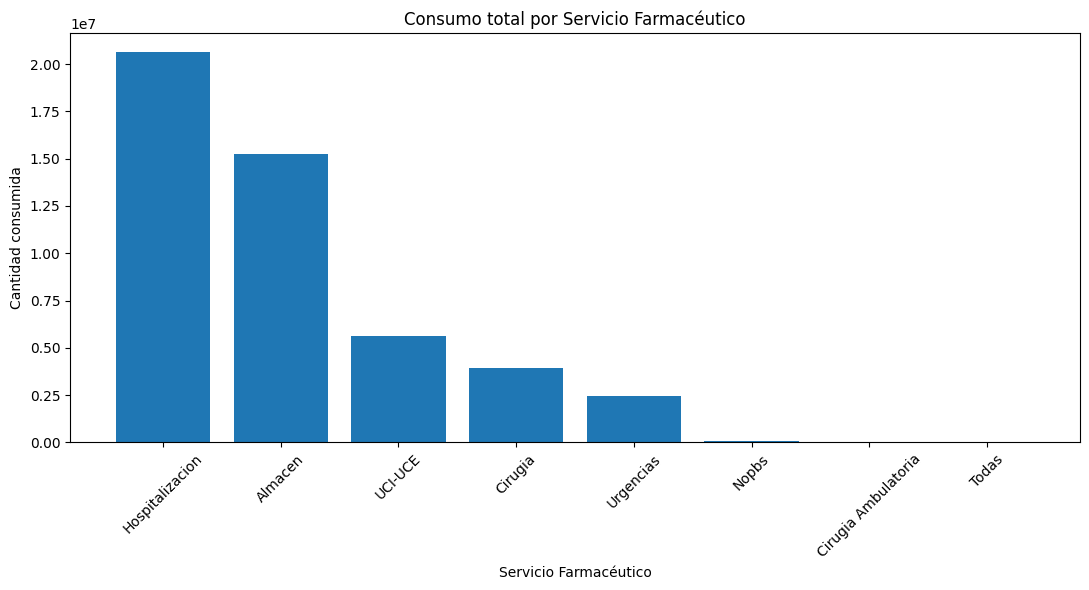

In [59]:
# GRÁFICA DEL CONSUMO POR SERVICIO FARMACÉUTICO


import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.bar(
    consumo_por_sf["SERVICIO_FARMACEUTICO"],
    consumo_por_sf["Consumo_total"]
)

plt.title("Consumo total por Servicio Farmacéutico")
plt.xlabel("Servicio Farmacéutico")
plt.ylabel("Cantidad consumida")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [60]:
print(consumo_por_sf.to_string(index=False))

SERVICIO_FARMACEUTICO  Registros  Consumo_total  Participacion_%
      Hospitalizacion    6415564     20621808.0        42.969536
              Almacen      50684     15270443.0        31.818929
              UCI-UCE    2192881      5638164.0        11.748208
              Cirugia    1481916      3912064.0         8.151544
            Urgencias    1164861      2468920.0         5.144474
                Nopbs      33901        62801.0         0.130858
  Cirugia Ambulatoria       1799        17385.0         0.036225
                Todas         80          109.0         0.000227


In [61]:
# VALIDACIÓN DE LA DISTRIBUCIÓN POR SERVICIO


print("Registros de la base analítica:", len(base_historica))

print(
    "Suma de registros agrupados por Servicio Farmacéutico:",
    consumo_por_sf["Registros"].sum()
)

print(
    "Diferencia de registros:",
    len(base_historica) - consumo_por_sf["Registros"].sum()
)

print(
    "\nConsumo total de la base:",
    base_historica["CANTIDAD"].sum()
)

print(
    "Suma del consumo agrupado por Servicio Farmacéutico:",
    consumo_por_sf["Consumo_total"].sum()
)

print(
    "Diferencia de consumo:",
    base_historica["CANTIDAD"].sum()
    - consumo_por_sf["Consumo_total"].sum()
)

Registros de la base analítica: 11341686
Suma de registros agrupados por Servicio Farmacéutico: 11341686
Diferencia de registros: 0

Consumo total de la base: 47991694.0
Suma del consumo agrupado por Servicio Farmacéutico: 47991694.0
Diferencia de consumo: 0.0


In [62]:
productos_rotacion = (
    base_historica
    .groupby(["CODIGO_PROPIO", "DES_MEDICAMENTO"])
    .agg(
        Registros=("CANTIDAD", "count"),
        Consumo_total=("CANTIDAD", "sum")
    )
    .reset_index()
    .sort_values("Consumo_total", ascending=False)
)

print("Número de productos analizados:", len(productos_rotacion))

productos_rotacion.head(20)

Número de productos analizados: 11887


,CODIGO_PROPIO,DES_MEDICAMENTO,Registros,Consumo_total
3055,99944,GUANTE VINILO TALLA M,10898,6626700.0
3363,110314,GUANTE VINILO TALLA L,9096,5412995.0
1328,30483,ESPARADRAPO ELASTICO ADHES 15 CM X 1000 CM,3238,3911035.0
4484,41191082,TOALLITA ANTISEPTICA ESTERIL REF 101.06,6836,2681300.0
3362,110280,GUANTE VINILO TALLA S,5716,2635500.0
657,6003,ESPARADRAPO ELASTICO ADHES 10 CM X 1000 CM,1712,1905505.0
1473,32568,IOPRAMIDA SOLUCION INYECTABLE 300MG/50 ML X ML,16795,1874796.0
1334,30513,GASA ESTERIL 10CMX10CM 16 PLY QUALIMED,102212,1328763.0
812,9848,GASA PRECORTADA 10 X 10 UNIDAD,5420,1304863.0
505,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,550992,1077704.0


In [63]:
# FRECUENCIA MENSUAL DE CONSUMO POR PRODUCTO


frecuencia_productos = (
    base_historica
    .groupby(["CODIGO_PROPIO", "DES_MEDICAMENTO"])["PERIODO"]
    .nunique()
    .reset_index(name="Meses_con_consumo")
)

# Incorporar el consumo total
productos_rotacion = productos_rotacion.merge(
    frecuencia_productos,
    on=["CODIGO_PROPIO", "DES_MEDICAMENTO"],
    how="left"
)

# Ordenar por frecuencia de consumo
productos_rotacion = productos_rotacion.sort_values(
    ["Meses_con_consumo", "Consumo_total"],
    ascending=[False, False]
)

print("Productos analizados:", len(productos_rotacion))
print("Meses del período de análisis:", base_historica["PERIODO"].nunique())

productos_rotacion.head(20)

Productos analizados: 11887
Meses del período de análisis: 29


,CODIGO_PROPIO,DES_MEDICAMENTO,Registros,Consumo_total,Meses_con_consumo
9,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,550992,1077704.0,29
10,9105,JERINGA DESECHABLE 5 ML CON AGUJA 21G X 1.,439809,917586.0,29
11,9403,JERINGA DESECHABLE 10 ML 21G X 1 1/2,405876,886023.0,29
12,10140,ACETAMINOFEN 500MG TABLETA,434213,831598.0,29
13,35046,LANCETA DESECHABLE,301935,666960.0,29
16,3026,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,189907,337590.0,29
18,2089,ELECTRODO MONITOREO ADULTO,55605,314800.0,29
19,19004,JERINGA DESECHABLE 20 ML PUNTA ROSCA CON AGUJA...,163746,302201.0,29
21,100015271,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,178668,275606.0,29
25,2638,GUANTE CIRUJANO N. 7,86403,182432.0,29


In [64]:
# DISTRIBUCIÓN DE LA FRECUENCIA DE CONSUMO

distribucion_frecuencia = (
    productos_rotacion
    .groupby("Meses_con_consumo")
    .size()
    .reset_index(name="Numero_productos")
    .sort_values("Meses_con_consumo", ascending=False)
)

# Calcular porcentaje de productos
distribucion_frecuencia["Porcentaje_%"] = (
    distribucion_frecuencia["Numero_productos"]
    / distribucion_frecuencia["Numero_productos"].sum()
    * 100
)

print(
    "Total de productos:",
    distribucion_frecuencia["Numero_productos"].sum()
)

distribucion_frecuencia

Total de productos: 11887


,Meses_con_consumo,Numero_productos,Porcentaje_%
28,29,404,3.398671
27,28,133,1.118869
26,27,107,0.900143
25,26,84,0.706654
24,25,88,0.740305
23,24,77,0.647766
22,23,112,0.942206
21,22,95,0.799192
20,21,64,0.538403
19,20,66,0.555228


In [65]:
# INTENSIDAD DEL CONSUMO EN LOS MESES ACTIVOS


productos_rotacion["Consumo_promedio_mes_activo"] = (
    productos_rotacion["Consumo_total"]
    / productos_rotacion["Meses_con_consumo"]
)

print("Productos analizados:", len(productos_rotacion))

productos_rotacion[
    [
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        "Consumo_total",
        "Meses_con_consumo",
        "Consumo_promedio_mes_activo"
    ]
].head(20)

Productos analizados: 11887


,CODIGO_PROPIO,DES_MEDICAMENTO,Consumo_total,Meses_con_consumo,Consumo_promedio_mes_activo
9,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,1077704.0,29,37162.206897
10,9105,JERINGA DESECHABLE 5 ML CON AGUJA 21G X 1.,917586.0,29,31640.896552
11,9403,JERINGA DESECHABLE 10 ML 21G X 1 1/2,886023.0,29,30552.517241
12,10140,ACETAMINOFEN 500MG TABLETA,831598.0,29,28675.793103
13,35046,LANCETA DESECHABLE,666960.0,29,22998.620690
16,3026,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,337590.0,29,11641.034483
18,2089,ELECTRODO MONITOREO ADULTO,314800.0,29,10855.172414
19,19004,JERINGA DESECHABLE 20 ML PUNTA ROSCA CON AGUJA...,302201.0,29,10420.724138
21,100015271,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,275606.0,29,9503.655172
25,2638,GUANTE CIRUJANO N. 7,182432.0,29,6290.758621


In [66]:
# CLASIFICACIÓN DESCRIPTIVA DE LOS PATRONES DE FRECUENCIA DE CONSUMO

def clasificar_frecuencia(meses):
    if meses >= 24:
        return "Consumo sostenido"
    elif meses >= 12:
        return "Consumo frecuente"
    elif meses >= 4:
        return "Consumo intermitente"
    else:
        return "Consumo esporádico"


productos_rotacion["Patron_frecuencia"] = (
    productos_rotacion["Meses_con_consumo"]
    .apply(clasificar_frecuencia)
)

distribucion_patrones = (
    productos_rotacion
    .groupby("Patron_frecuencia")
    .size()
    .reset_index(name="Numero_productos")
)

distribucion_patrones["Porcentaje_%"] = (
    distribucion_patrones["Numero_productos"]
    / distribucion_patrones["Numero_productos"].sum()
    * 100
)

orden_patrones = [
    "Consumo sostenido",
    "Consumo frecuente",
    "Consumo intermitente",
    "Consumo esporádico"
]

distribucion_patrones["Orden"] = (
    distribucion_patrones["Patron_frecuencia"]
    .map({x: i for i, x in enumerate(orden_patrones)})
)

distribucion_patrones = (
    distribucion_patrones
    .sort_values("Orden")
    .drop(columns="Orden")
)

distribucion_patrones

,Patron_frecuencia,Numero_productos,Porcentaje_%
3,Consumo sostenido,893,7.512409
1,Consumo frecuente,1024,8.614453
2,Consumo intermitente,2482,20.879953
0,Consumo esporádico,7488,62.993186


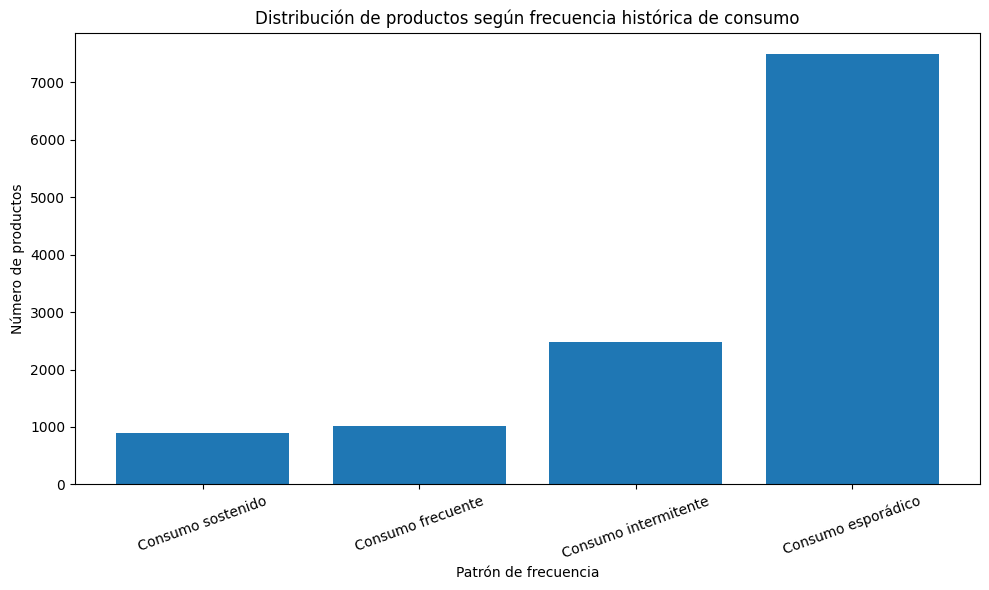

In [67]:
# GRÁFICA DE LOS PATRONES DE FRECUENCIA


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    distribucion_patrones["Patron_frecuencia"],
    distribucion_patrones["Numero_productos"]
)

plt.title("Distribución de productos según frecuencia histórica de consumo")
plt.xlabel("Patrón de frecuencia")
plt.ylabel("Número de productos")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [68]:
# CONSUMO TOTAL SEGÚN PATRÓN DE FRECUENCIA


consumo_por_patron = (
    productos_rotacion
    .groupby("Patron_frecuencia")
    .agg(
        Numero_productos=("CODIGO_PROPIO", "count"),
        Consumo_total=("Consumo_total", "sum")
    )
    .reset_index()
)

consumo_por_patron["Participacion_consumo_%"] = (
    consumo_por_patron["Consumo_total"]
    / consumo_por_patron["Consumo_total"].sum()
    * 100
)

orden_patrones = [
    "Consumo sostenido",
    "Consumo frecuente",
    "Consumo intermitente",
    "Consumo esporádico"
]

consumo_por_patron["Orden"] = (
    consumo_por_patron["Patron_frecuencia"]
    .map({x: i for i, x in enumerate(orden_patrones)})
)

consumo_por_patron = (
    consumo_por_patron
    .sort_values("Orden")
    .drop(columns="Orden")
)

consumo_por_patron

,Patron_frecuencia,Numero_productos,Consumo_total,Participacion_consumo_%
3,Consumo sostenido,893,41836454.0,87.174364
1,Consumo frecuente,1024,3813593.0,7.946360
2,Consumo intermitente,2482,1940659.0,4.043739
0,Consumo esporádico,7488,400988.0,0.835536


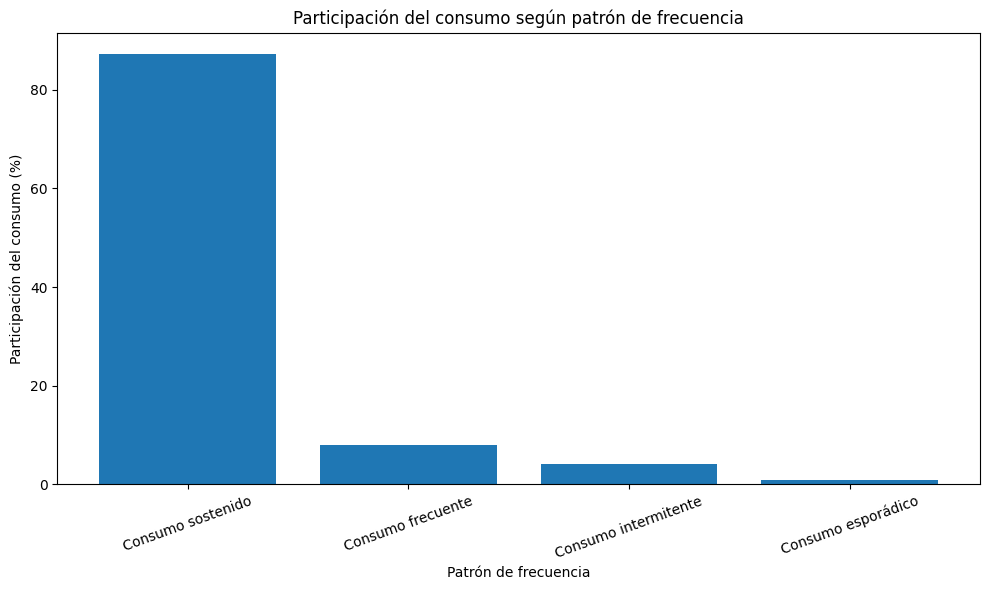

In [69]:
# PARTICIPACIÓN DEL CONSUMO SEGÚN PATRÓN


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    consumo_por_patron["Patron_frecuencia"],
    consumo_por_patron["Participacion_consumo_%"]
)

plt.title("Participación del consumo según patrón de frecuencia")
plt.xlabel("Patrón de frecuencia")
plt.ylabel("Participación del consumo (%)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [70]:
# RECONSTRUCCIÓN COMPLETA DEL ANÁLISIS
# DE ROTACIÓN


# 1. Universo de productos y consumo acumulado
productos_rotacion = (
    base_historica
    .groupby(["CODIGO_PROPIO", "DES_MEDICAMENTO"])
    .agg(
        Registros=("CANTIDAD", "count"),
        Consumo_total=("CANTIDAD", "sum")
    )
    .reset_index()
)

# 2. Número de meses con consumo
frecuencia_productos = (
    base_historica
    .groupby(["CODIGO_PROPIO", "DES_MEDICAMENTO"])["PERIODO"]
    .nunique()
    .reset_index(name="Meses_con_consumo")
)

# 3. Incorporar frecuencia a la tabla de productos
productos_rotacion = productos_rotacion.merge(
    frecuencia_productos,
    on=["CODIGO_PROPIO", "DES_MEDICAMENTO"],
    how="left"
)

# 4. Consumo promedio durante los meses activos
productos_rotacion["Consumo_promedio_mes_activo"] = (
    productos_rotacion["Consumo_total"]
    / productos_rotacion["Meses_con_consumo"]
)

# 5. Clasificación descriptiva de frecuencia
def clasificar_frecuencia(meses):
    if meses >= 24:
        return "Consumo sostenido"
    elif meses >= 12:
        return "Consumo frecuente"
    elif meses >= 4:
        return "Consumo intermitente"
    else:
        return "Consumo esporádico"

productos_rotacion["Patron_frecuencia"] = (
    productos_rotacion["Meses_con_consumo"]
    .apply(clasificar_frecuencia)
)

# 6. Ordenar por consumo total
productos_rotacion = productos_rotacion.sort_values(
    "Consumo_total",
    ascending=False
).reset_index(drop=True)

# 7. Verificación
print("Productos analizados:", len(productos_rotacion))
print("\nDistribución de patrones:")
print(productos_rotacion["Patron_frecuencia"].value_counts())

print("\nColumnas disponibles:")
print(productos_rotacion.columns.tolist())

Productos analizados: 11887

Distribución de patrones:
Patron_frecuencia
Consumo esporádico      7488
Consumo intermitente    2482
Consumo frecuente       1024
Consumo sostenido        893
Name: count, dtype: int64

Columnas disponibles:
['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'Registros', 'Consumo_total', 'Meses_con_consumo', 'Consumo_promedio_mes_activo', 'Patron_frecuencia']


In [71]:
# PRODUCTOS DE CONSUMO SOSTENIDO
# CON MAYOR CONSUMO ACUMULADO


top_sostenidos = (
    productos_rotacion[
        productos_rotacion["Patron_frecuencia"] == "Consumo sostenido"
    ]
    .sort_values("Consumo_total", ascending=False)
    .head(20)
    [
        [
            "CODIGO_PROPIO",
            "DES_MEDICAMENTO",
            "Meses_con_consumo",
            "Consumo_total",
            "Consumo_promedio_mes_activo"
        ]
    ]
)

top_sostenidos

,CODIGO_PROPIO,DES_MEDICAMENTO,Meses_con_consumo,Consumo_total,Consumo_promedio_mes_activo
0,99944,GUANTE VINILO TALLA M,28,6626700.0,236667.857143
1,110314,GUANTE VINILO TALLA L,28,5412995.0,193321.250000
2,30483,ESPARADRAPO ELASTICO ADHES 15 CM X 1000 CM,28,3911035.0,139679.821429
3,41191082,TOALLITA ANTISEPTICA ESTERIL REF 101.06,28,2681300.0,95760.714286
4,110280,GUANTE VINILO TALLA S,28,2635500.0,94125.000000
5,6003,ESPARADRAPO ELASTICO ADHES 10 CM X 1000 CM,28,1905505.0,68053.750000
6,32568,IOPRAMIDA SOLUCION INYECTABLE 300MG/50 ML X ML,26,1874796.0,72107.538462
7,30513,GASA ESTERIL 10CMX10CM 16 PLY QUALIMED,24,1328763.0,55365.125000
8,9848,GASA PRECORTADA 10 X 10 UNIDAD,25,1304863.0,52194.520000
9,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,29,1077704.0,37162.206897


In [72]:
# TABLA PARA EXPORTAR A EXCEL


tabla_excel = top_sostenidos.copy()

# Redondear el promedio a 2 decimales
tabla_excel["Consumo_promedio_mes_activo"] = (
    tabla_excel["Consumo_promedio_mes_activo"]
    .round(2)
)

# Eliminar el índice de pandas
tabla_excel = tabla_excel.reset_index(drop=True)

tabla_excel

,CODIGO_PROPIO,DES_MEDICAMENTO,Meses_con_consumo,Consumo_total,Consumo_promedio_mes_activo
0,99944,GUANTE VINILO TALLA M,28,6626700.0,236667.86
1,110314,GUANTE VINILO TALLA L,28,5412995.0,193321.25
2,30483,ESPARADRAPO ELASTICO ADHES 15 CM X 1000 CM,28,3911035.0,139679.82
3,41191082,TOALLITA ANTISEPTICA ESTERIL REF 101.06,28,2681300.0,95760.71
4,110280,GUANTE VINILO TALLA S,28,2635500.0,94125.00
5,6003,ESPARADRAPO ELASTICO ADHES 10 CM X 1000 CM,28,1905505.0,68053.75
6,32568,IOPRAMIDA SOLUCION INYECTABLE 300MG/50 ML X ML,26,1874796.0,72107.54
7,30513,GASA ESTERIL 10CMX10CM 16 PLY QUALIMED,24,1328763.0,55365.12
8,9848,GASA PRECORTADA 10 X 10 UNIDAD,25,1304863.0,52194.52
9,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,29,1077704.0,37162.21


In [73]:
# ANÁLISIS DE VARIABILIDAD
# CONSUMO MENSUAL POR PRODUCTO


consumo_mensual_producto = (
    base_historica
    .groupby(["CODIGO_PROPIO", "DES_MEDICAMENTO", "PERIODO"])["CANTIDAD"]
    .sum()
    .reset_index()
)

print("Registros de consumo mensual por producto:", len(consumo_mensual_producto))

consumo_mensual_producto.head(20)

Registros de consumo mensual por producto: 68888


,CODIGO_PROPIO,DES_MEDICAMENTO,PERIODO,CANTIDAD
0,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2025-12-01,34.0
1,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-01-01,3.0
2,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-02-01,17.0
3,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-03-01,5.0
4,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-04-01,6.0
5,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-05-01,2.0
6,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),2024-01-01,8.0
7,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),2024-02-01,35.0
8,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),2024-03-01,43.0
9,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),2024-04-01,34.0


In [74]:
# MATRIZ DE CONSUMO MENSUAL
# PRODUCTO × PERÍODO


matriz_consumo = (
    consumo_mensual_producto
    .pivot_table(
        index=["CODIGO_PROPIO", "DES_MEDICAMENTO"],
        columns="PERIODO",
        values="CANTIDAD",
        aggfunc="sum",
        fill_value=0
    )
)

print("Productos:", matriz_consumo.shape[0])
print("Períodos:", matriz_consumo.shape[1])

matriz_consumo.head()

Productos: 11887
Períodos: 29


PERIODO                                                           2024-01-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                  8.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       107.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 3827.0   

PERIODO                                                           2024-02-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 35.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       140.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 3028.0   

PERIODO                                                           2024-03-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 43.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       143.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 3499.0   

PERIODO                                                           2024-04-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 34.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       135.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 3944.0   

PERIODO                                                           2024-05-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 29.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       139.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 2855.0   

PERIODO                                                           2024-06-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 48.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       150.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 4077.0   

PERIODO                                                           2024-07-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 32.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       143.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 4278.0   

PERIODO                                                           2024-08

In [75]:
# CÁLCULO DE LA VARIABILIDAD DEL CONSUMO

# Seleccionar únicamente las columnas correspondientes
# a los 29 períodos mensuales
columnas_periodos = matriz_consumo.columns

# Promedio mensual del consumo
variabilidad_productos = matriz_consumo.copy()

variabilidad_productos["Promedio_mensual"] = (
    matriz_consumo[columnas_periodos].mean(axis=1)
)

# Desviación estándar mensual
variabilidad_productos["Desviacion_estandar"] = (
    matriz_consumo[columnas_periodos].std(axis=1)
)

# Coeficiente de variación
variabilidad_productos["CV_%"] = (
    variabilidad_productos["Desviacion_estandar"]
    / variabilidad_productos["Promedio_mensual"]
    * 100
)

variabilidad_productos = (
    variabilidad_productos
    .reset_index()
)

print("Productos analizados:", len(variabilidad_productos))

variabilidad_productos[
    [
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        "Promedio_mensual",
        "Desviacion_estandar",
        "CV_%"
    ]
].head(20)

Productos analizados: 11887


PERIODO,CODIGO_PROPIO,DES_MEDICAMENTO,Promedio_mensual,Desviacion_estandar,CV_%
0,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2.310345,6.980091,302.123356
1,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),27.034483,18.399307,68.058660
2,55,ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 6...,62.344828,60.326064,96.761939
3,55,ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML,21.620690,33.744220,156.073747
4,64,ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA,2169.827586,1423.493792,65.604005
5,87,ACETIL SALICILICO ACIDO 100 MG TABLETA,1833.827586,407.047739,22.196620
6,101,ACETILCISTEINA 300 MG/3 ML SOLUCION INYECTABLE,181.413793,158.498201,87.368330
7,178,ADRENALINA 1MG/ML 1ML SOLUCION INYECTABLE,182.137931,128.801543,70.716485
8,178,ADRENALINA 1MG/ML 1ML SOLUCION INYECTABLE AMPOLLA,93.068966,156.564211,168.223865
9,212,AGUA ESTERIL SOLUCION INYECTABLE 500 ML,1075.137931,312.165218,29.034899


In [76]:
# DISTRIBUCIÓN DEL COEFICIENTE DE VARIACIÓN


resumen_cv = pd.DataFrame({
    "Indicador": [
        "CV mínimo",
        "CV P25",
        "CV mediana",
        "CV P75",
        "CV P90",
        "CV P95",
        "CV máximo"
    ],
    "Valor": [
        variabilidad_productos["CV_%"].min(),
        variabilidad_productos["CV_%"].quantile(0.25),
        variabilidad_productos["CV_%"].median(),
        variabilidad_productos["CV_%"].quantile(0.75),
        variabilidad_productos["CV_%"].quantile(0.90),
        variabilidad_productos["CV_%"].quantile(0.95),
        variabilidad_productos["CV_%"].max()
    ]
})

resumen_cv

,Indicador,Valor
0,CV mínimo,17.653286
1,CV P25,222.967006
2,CV mediana,373.927036
3,CV P75,538.516481
4,CV P90,538.516481
5,CV P95,538.516481
6,CV máximo,538.516481


In [77]:
# DISTRIBUCIÓN DEL COEFICIENTE DE VARIACIÓN


intervalos_cv = [0, 25, 50, 100, 200, 300, 400, 500, 600]

etiquetas_cv = [
    "0-25%",
    "25-50%",
    "50-100%",
    "100-200%",
    "200-300%",
    "300-400%",
    "400-500%",
    "500-600%"
]

variabilidad_productos["Rango_CV"] = pd.cut(
    variabilidad_productos["CV_%"],
    bins=intervalos_cv,
    labels=etiquetas_cv,
    include_lowest=True
)

distribucion_cv = (
    variabilidad_productos
    .groupby("Rango_CV", observed=False)
    .agg(
        Numero_productos=("CODIGO_PROPIO", "count")
    )
    .reset_index()
)

distribucion_cv["Porcentaje_%"] = (
    distribucion_cv["Numero_productos"]
    / len(variabilidad_productos)
    * 100
)

distribucion_cv

,Rango_CV,Numero_productos,Porcentaje_%
0,0-25%,20,0.168251
1,25-50%,236,1.985362
2,50-100%,763,6.418777
3,100-200%,1585,13.333894
4,200-300%,1965,16.530664
5,300-400%,1993,16.766215
6,400-500%,195,1.640448
7,500-600%,5130,43.156389


In [80]:
# INCORPORAR PATRÓN DE FRECUENCIA
# A LA BASE DE VARIABILIDAD


patrones_producto = productos_rotacion[
    [
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        "Patron_frecuencia"
    ]
].drop_duplicates(
    subset=["CODIGO_PROPIO", "DES_MEDICAMENTO"]
)

variabilidad_productos = variabilidad_productos.merge(
    patrones_producto,
    on=["CODIGO_PROPIO", "DES_MEDICAMENTO"],
    how="left"
)

print("Productos analizados:", len(variabilidad_productos))
print(
    "Productos con patrón asignado:",
    variabilidad_productos["Patron_frecuencia"].notna().sum()
)
print(
    "Productos sin patrón:",
    variabilidad_productos["Patron_frecuencia"].isna().sum()
)

Productos analizados: 11887
Productos con patrón asignado: 11887
Productos sin patrón: 0


In [81]:
# RELACIÓN ENTRE FRECUENCIA Y VARIABILIDAD


relacion_frecuencia_variabilidad = pd.crosstab(
    variabilidad_productos["Rango_CV"],
    variabilidad_productos["Patron_frecuencia"]
)

relacion_frecuencia_variabilidad

Patron_frecuencia,Consumo esporádico,Consumo frecuente,Consumo intermitente,Consumo sostenido
Rango_CV,,,,
0-25%,0,0,0,20
25-50%,0,0,0,236
50-100%,0,213,0,550
100-200%,0,769,735,81
200-300%,350,37,1573,5
300-400%,1827,4,161,1
400-500%,181,1,13,0
500-600%,5130,0,0,0


In [82]:
# PORCENTAJE DE CADA PATRÓN
# DENTRO DE CADA RANGO DE CV


relacion_frecuencia_variabilidad_pct = (
    pd.crosstab(
        variabilidad_productos["Rango_CV"],
        variabilidad_productos["Patron_frecuencia"],
        normalize="index"
    ) * 100
)

relacion_frecuencia_variabilidad_pct = (
    relacion_frecuencia_variabilidad_pct.round(2)
)

relacion_frecuencia_variabilidad_pct

Patron_frecuencia,Consumo esporádico,Consumo frecuente,Consumo intermitente,Consumo sostenido
Rango_CV,,,,
0-25%,0.00,0.00,0.00,100.00
25-50%,0.00,0.00,0.00,100.00
50-100%,0.00,27.92,0.00,72.08
100-200%,0.00,48.52,46.37,5.11
200-300%,17.81,1.88,80.05,0.25
300-400%,91.67,0.20,8.08,0.05
400-500%,92.82,0.51,6.67,0.00
500-600%,100.00,0.00,0.00,0.00


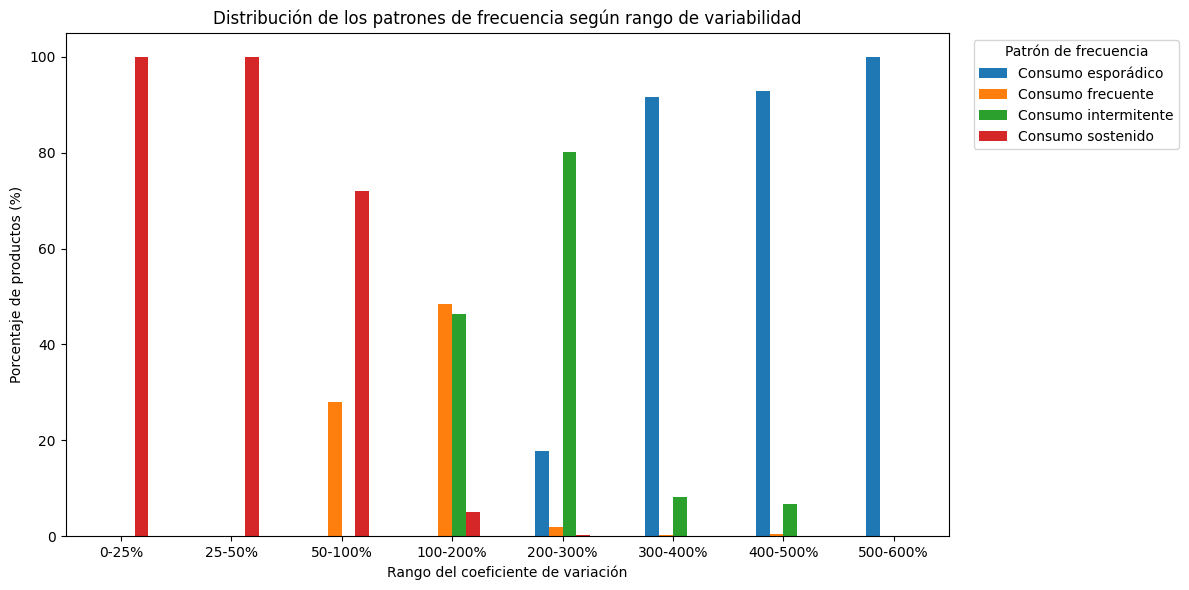

In [83]:
# RELACIÓN ENTRE FRECUENCIA Y VARIABILIDAD


relacion_frecuencia_variabilidad_pct.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Distribución de los patrones de frecuencia según rango de variabilidad"
)

plt.xlabel("Rango del coeficiente de variación")
plt.ylabel("Porcentaje de productos (%)")
plt.xticks(rotation=0)

plt.legend(
    title="Patrón de frecuencia",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [84]:
# PRODUCTOS CON MAYOR VARIABILIDAD


# Ordenar los productos por coeficiente de variación
# de mayor a menor
mayor_variabilidad = (
    variabilidad_productos[
        [
            "CODIGO_PROPIO",
            "DES_MEDICAMENTO",
            "Promedio_mensual",
            "Desviacion_estandar",
            "CV_%",
            "Patron_frecuencia"
        ]
    ]
    .sort_values("CV_%", ascending=False)
    .head(20)
)

mayor_variabilidad

,CODIGO_PROPIO,DES_MEDICAMENTO,Promedio_mensual,Desviacion_estandar,CV_%,Patron_frecuencia
707,8240,AMOXICILINA-AC CLAVULANICO 500/125 MG TAB,1.310345,7.056423,538.516481,Consumo esporádico
721,8678,AGUJA DESECHABLE HIPODERMICA N 27 G X 1,13.655172,73.535354,538.516481,Consumo esporádico
6027,100015289,TORNILLO BLOQUEO 4.0 X 42MM REF 661042,0.034483,0.185695,538.516481,Consumo esporádico
3751,250079,TORN. CORTICAL 4.5MM X 24MM REF TC4524,0.068966,0.371391,538.516481,Consumo esporádico
7708,100018504,TORNILLO CANULADO 3.5 RC L 48 REF 11103SC3500-...,0.034483,0.185695,538.516481,Consumo esporádico
1798,40102,CATETER DIAGNOSTICO AR2-AL2,0.034483,0.185695,538.516481,Consumo esporádico
7130,100017670,SISTEMA DE CIERRE DE OREJUELA AURICULAR IZQUIE...,0.034483,0.185695,538.516481,Consumo esporádico
7137,100017682,BALON CORONARIO CORTANTE WOLVERINE 2.50 X 10 M...,0.034483,0.185695,538.516481,Consumo esporádico
7139,100017685,"BALON CORONARIO CORTANTE WOLVERINE 2,0 X 15 MM...",0.034483,0.185695,538.516481,Consumo esporádico
7935,100018773,CLAVO INTRAMEDULAR DE HUMERO DE 9X160 MM MAGIC...,0.034483,0.185695,538.516481,Consumo esporádico


In [85]:
# VARIABILIDAD EN PRODUCTOS DE CONSUMO
# FRECUENTE Y SOSTENIDO


variabilidad_recurrente = (
    variabilidad_productos[
        variabilidad_productos["Patron_frecuencia"].isin(
            ["Consumo frecuente", "Consumo sostenido"]
        )
    ][
        [
            "CODIGO_PROPIO",
            "DES_MEDICAMENTO",
            "Promedio_mensual",
            "Desviacion_estandar",
            "CV_%",
            "Patron_frecuencia"
        ]
    ]
    .sort_values("CV_%", ascending=False)
    .head(20)
)

print(
    "Productos frecuentes y sostenidos analizados:",
    len(
        variabilidad_productos[
            variabilidad_productos["Patron_frecuencia"].isin(
                ["Consumo frecuente", "Consumo sostenido"]
            )
        ]
    )
)

variabilidad_recurrente

Productos frecuentes y sostenidos analizados: 1917


,CODIGO_PROPIO,DES_MEDICAMENTO,Promedio_mensual,Desviacion_estandar,CV_%,Patron_frecuencia
156,1653,CLOZAPINA 25 MG TABLETA,11.758621,48.767418,414.737575,Consumo frecuente
46,652,ARIPIPRAZOL 15 MG TABLETA,5.344828,18.287927,342.161216,Consumo frecuente
847,10314,GUANTE LATEX TALLA L,2044.827586,6972.629459,340.988624,Consumo frecuente
3118,102199,LINER SEMIRRIGIDO CON VALVULA 1500 CC,12.482759,42.364592,339.384850,Consumo frecuente
826,10088,APLICADORES CON ALGODON,139.758621,446.444658,319.439800,Consumo sostenido
4227,1591345,EMULSION LIPIDICA 20 % MCT/LCT (LIPOFUNDIN) X ...,3.034483,9.279327,305.796007,Consumo frecuente
500,4926,SEDA NEGRA TRENZADA 4-0 CON AGUJA DE 3/8 CIRC...,4.896552,14.148056,288.939171,Consumo frecuente
947,11402,APOSITO DE CARBON ACTIVADO CON PLATA 10.5X19CM...,7.379310,20.492880,277.707251,Consumo frecuente
665,6062,GENTAMICINA SULFATO 40 MG/ML SOLUCION INYECTABLE,5.034483,13.607988,270.295654,Consumo frecuente
1372,30888,SONDA NELATON N 4,2.413793,6.455990,267.462430,Consumo frecuente


In [87]:
# Ver las variables que actualmente existen en memoria
%whos DataFrame

Variable                               Type         Data/Info
-------------------------------------------------------------
base_2024                              DataFrame            CODIGO_PROPIO    <...>5670011 rows x 9 columns]
base_historica                         DataFrame             CODIGO_PROPIO   <...>341686 rows x 11 columns]
bodegas                                DataFrame        Bodega               <...>         No        8585  
bodegas_validacion                     DataFrame        Bodega Servicio Farma<...>585                   NaN
cambios_mensuales                      DataFrame          PERIODO   CANTIDAD <...>1   922393.0   -21.543539
cantidad_uno                           DataFrame       AÑO_REAL  Registros  R<...>01              69.931026
comparacion_ene_may                    DataFrame        AÑO  Consumo_total  P<...>   1191718.4   -22.942452
consumo_anual                          DataFrame        AÑO  Consumo_total  P<...>58592.0      1.191718e+06
consumo_ene_

In [88]:
# Mostrar la base consolidada de consumo mensual
consumo_mensual

,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [89]:
print("Número de períodos:", len(consumo_mensual))
display(consumo_mensual)

Número de períodos: 29


,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [94]:
consumo_mensual = (
    base_historica
    .groupby("PERIODO", as_index=False)["CANTIDAD"]
    .sum()
    .sort_values("PERIODO")
)

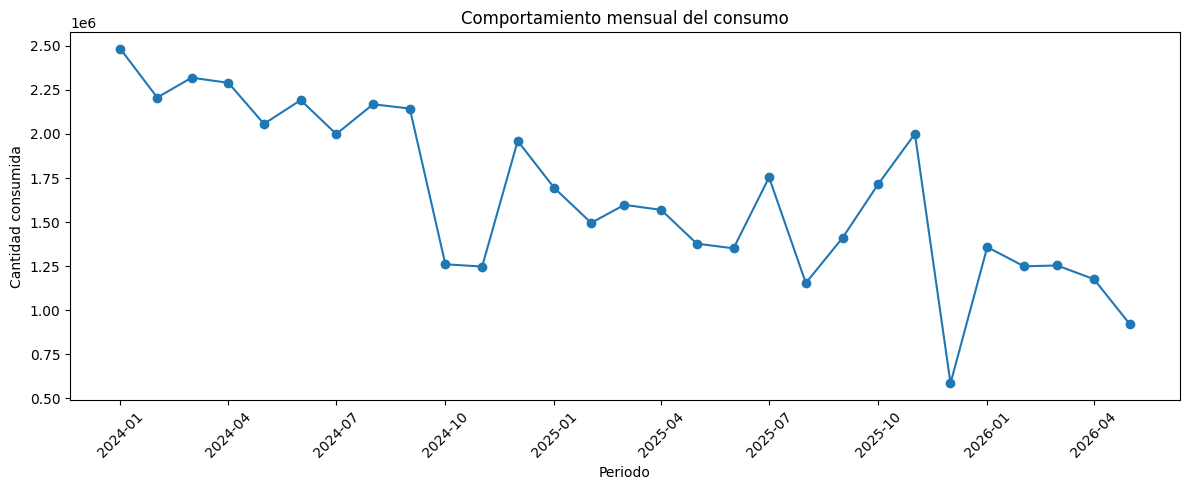

In [95]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    consumo_mensual["PERIODO"],
    consumo_mensual["CANTIDAD"],
    marker="o"
)

plt.xlabel("Periodo")
plt.ylabel("Cantidad consumida")
plt.title("Comportamiento mensual del consumo")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [96]:
base_historica.columns.tolist()

['CODIGO_PROPIO',
 'DES_MEDICAMENTO',
 'CANTIDAD',
 'BODEGA',
 'DES_UF',
 'MES',
 'AÑO',
 'MES_NUMERO',
 'PERIODO',
 'BODEGA_KEY',
 'SERVICIO_FARMACEUTICO']

In [97]:
comparacion_ene_may.columns.tolist()

['AÑO', 'Consumo_total', 'Promedio_mensual', 'Variacion_%']

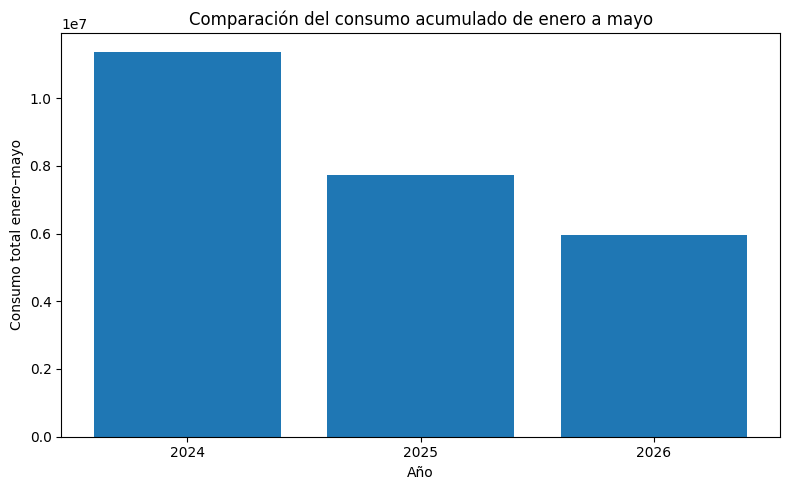

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparacion_ene_may["AÑO"].astype(str),
    comparacion_ene_may["Consumo_total"]
)

plt.xlabel("Año")
plt.ylabel("Consumo total enero–mayo")
plt.title("Comparación del consumo acumulado de enero a mayo")

plt.tight_layout()
plt.show()

In [101]:
consumo_servicio = (
    base_historica
    .groupby("SERVICIO_FARMACEUTICO", as_index=False)["CANTIDAD"]
    .sum()
    .sort_values("CANTIDAD", ascending=False)
)

consumo_servicio

,SERVICIO_FARMACEUTICO,CANTIDAD
3,Hospitalizacion,20621808.0
0,Almacen,15270443.0
6,UCI-UCE,5638164.0
1,Cirugia,3912064.0
7,Urgencias,2468920.0
4,Nopbs,62801.0
2,Cirugia Ambulatoria,17385.0
5,Todas,109.0


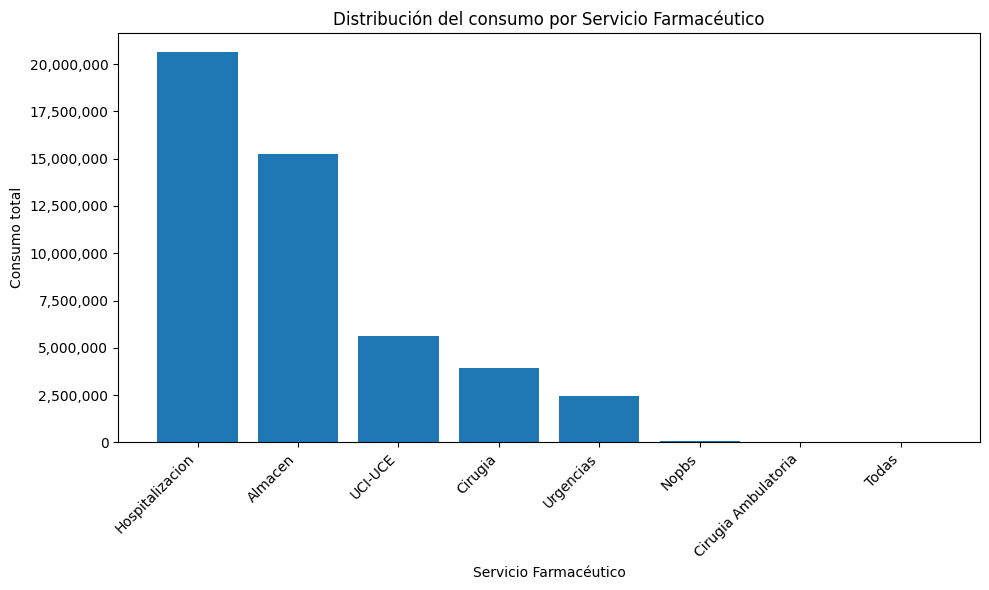

In [102]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.figure(figsize=(10, 6))

plt.bar(
    consumo_servicio["SERVICIO_FARMACEUTICO"],
    consumo_servicio["CANTIDAD"]
)

plt.xlabel("Servicio Farmacéutico")
plt.ylabel("Consumo total")
plt.title("Distribución del consumo por Servicio Farmacéutico")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter('{x:,.0f}')
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [104]:
# Validación de la distribución por Servicio Farmacéutico

registros_base = len(base_historica)

registros_agrupados = (
    base_historica
    .groupby("SERVICIO_FARMACEUTICO")
    .size()
    .sum()
)

consumo_base = base_historica["CANTIDAD"].sum()

consumo_agrupado = consumo_servicio["CANTIDAD"].sum()

print("Registros de la base:", registros_base)
print("Registros agrupados:", registros_agrupados)
print("Diferencia de registros:", registros_base - registros_agrupados)

print()

print("Consumo total de la base:", consumo_base)
print("Consumo total agrupado:", consumo_agrupado)
print("Diferencia de consumo:", consumo_base - consumo_agrupado)

Registros de la base: 11341686
Registros agrupados: 11341686
Diferencia de registros: 0

Consumo total de la base: 47991694.0
Consumo total agrupado: 47991694.0
Diferencia de consumo: 0.0


In [108]:
print(base_historica[["MES", "AÑO", "CANTIDAD"]].dtypes)

print(base_historica["MES"].unique()[:15])

MES          object
AÑO           int64
CANTIDAD    float64
dtype: object
['Abril' 'Agosto' 'Diciembre' 'Enero' 'febrero' 'Julio' 'Junio' 'Marzo'
 'Mayo' 'Noviembre' 'Octubre' 'Septiembre' 'Febrero' 'ABRIL' 'MARZO']


In [109]:
# Seleccionar únicamente las columnas necesarias
columnas = [
    "CODIGO_PROPIO",
    "MES",
    "AÑO",
    "CANTIDAD"
]

# Filtrar y crear una base reducida
base_temporal = base_historica.loc[
    base_historica["MES"].astype(str).str.strip().isin(
        ["1", "2", "3", "4", "5", "01", "02", "03", "04", "05"]
    ) &
    base_historica["AÑO"].astype(str).str.strip().isin(
        ["2024", "2025", "2026"]
    ),
    columnas
].copy()

print("Registros seleccionados:", len(base_temporal))
print("Memoria utilizada (MB):",
      round(base_temporal.memory_usage(deep=True).sum() / 1024**2, 2))

Registros seleccionados: 0
Memoria utilizada (MB): 0.0


In [110]:
print("Valores de MES:")
print(base_historica["MES"].value_counts(dropna=False).head(35))

print("\nValores de AÑO:")
print(base_historica["AÑO"].value_counts(dropna=False))

print("\nTipos de datos:")
print(base_historica[["MES", "AÑO", "CANTIDAD"]].dtypes)

Valores de MES:
MES
Enero         1267101
Mayo          1007143
Abril          938305
Julio          928078
Junio          888204
Marzo          877758
Septiembre     866326
Agosto         825996
Diciembre      698225
Octubre        677291
Noviembre      653459
Febrero        611111
febrero        525594
MARZO          308209
ABRIL          268886
Name: count, dtype: int64

Valores de AÑO:
AÑO
2024    5670011
2025    4276758
2026    1394917
Name: count, dtype: int64

Tipos de datos:
MES          object
AÑO           int64
CANTIDAD    float64
dtype: object


In [111]:
# Diccionario para convertir los nombres de los meses en números
meses = {
    "enero": 1,
    "febrero": 2,
    "marzo": 3,
    "abril": 4,
    "mayo": 5,
    "junio": 6,
    "julio": 7,
    "agosto": 8,
    "septiembre": 9,
    "octubre": 10,
    "noviembre": 11,
    "diciembre": 12
}

# Normalizar nombres de meses
mes_numero = (
    base_historica["MES"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(meses)
)

# Filtrar enero a mayo de 2024, 2025 y 2026
mascara = (
    mes_numero.between(1, 5) &
    base_historica["AÑO"].isin([2024, 2025, 2026])
)

# Crear base reducida
columnas = ["CODIGO_PROPIO", "MES", "AÑO", "CANTIDAD"]

base_temporal = base_historica.loc[mascara, columnas].copy()

# Validar
print("Registros seleccionados:", len(base_temporal))
print("\nDistribución por año:")
print(base_temporal["AÑO"].value_counts().sort_index())

print("\nDistribución por mes:")
print(base_temporal["MES"].value_counts())

Registros seleccionados: 5804107

Distribución por año:
AÑO
2024    2562963
2025    1846227
2026    1394917
Name: count, dtype: int64

Distribución por mes:
MES
Enero      1267101
Mayo       1007143
Abril       938305
Marzo       877758
Febrero     611111
febrero     525594
MARZO       308209
ABRIL       268886
Name: count, dtype: int64


In [112]:
# Consolidar cantidades por producto y año
consumo_producto = (
    base_temporal
    .groupby(["CODIGO_PROPIO", "AÑO"], observed=True)["CANTIDAD"]
    .sum()
    .unstack(fill_value=0)
)

# Asegurar las tres columnas
consumo_producto = consumo_producto.reindex(
    columns=[2024, 2025, 2026],
    fill_value=0
)

# Calcular consumo total por año
resumen_consumo = consumo_producto.sum()

# Tabla de resultados
comparacion_consumo = pd.DataFrame({
    "Año": [2024, 2025, 2026],
    "Unidades consumidas": [
        resumen_consumo[2024],
        resumen_consumo[2025],
        resumen_consumo[2026]
    ]
})

comparacion_consumo["Variación porcentual"] = [
    np.nan,
    (resumen_consumo[2025] / resumen_consumo[2024] - 1) * 100,
    (resumen_consumo[2026] / resumen_consumo[2025] - 1) * 100
]

display(comparacion_consumo.round(2))

print("Productos identificados:", consumo_producto.shape[0])

,Año,Unidades consumidas,Variación porcentual
0,2024,11357126.0,NaN
1,2025,7732652.0,-31.91
2,2026,5958592.0,-22.94


Productos identificados: 9016


In [113]:
# Comparar comportamiento de los productos

def clasificar_variacion(anterior, actual):
    if anterior == 0 and actual > 0:
        return "Nuevo registro de consumo"
    elif anterior > 0 and actual == 0:
        return "Sin consumo registrado"
    elif actual > anterior:
        return "Aumentó"
    elif actual < anterior:
        return "Disminuyó"
    else:
        return "Sin variación"

# Comparación 2024-2025
consumo_producto["Comportamiento_24_25"] = [
    clasificar_variacion(a, b)
    for a, b in zip(consumo_producto[2024], consumo_producto[2025])
]

# Comparación 2025-2026
consumo_producto["Comportamiento_25_26"] = [
    clasificar_variacion(a, b)
    for a, b in zip(consumo_producto[2025], consumo_producto[2026])
]

# Resumen de resultados
print("COMPORTAMIENTO 2024-2025")
display(
    consumo_producto["Comportamiento_24_25"]
    .value_counts()
    .to_frame("Número de productos")
)

print("COMPORTAMIENTO 2025-2026")
display(
    consumo_producto["Comportamiento_25_26"]
    .value_counts()
    .to_frame("Número de productos")
)

COMPORTAMIENTO 2024-2025


,Número de productos
Comportamiento_24_25,
Nuevo registro de consumo,3085
Sin consumo registrado,1960
Disminuyó,1716
Sin variación,1518
Aumentó,737


COMPORTAMIENTO 2025-2026


,Número de productos
Comportamiento_25_26,
Sin consumo registrado,3532
Sin variación,1881
Nuevo registro de consumo,1551
Disminuyó,1413
Aumentó,639


In [114]:
# Crear tabla de variaciones por producto
variacion_productos = consumo_producto[
    [2024, 2025, 2026]
].copy()

# Diferencias absolutas
variacion_productos["Cambio_24_25"] = (
    variacion_productos[2025] - variacion_productos[2024]
)

variacion_productos["Cambio_25_26"] = (
    variacion_productos[2026] - variacion_productos[2025]
)

# 20 productos con mayores disminuciones entre 2024 y 2025
mayores_caidas_24_25 = (
    variacion_productos
    .sort_values("Cambio_24_25")
    .head(20)
)

# 20 productos con mayores disminuciones entre 2025 y 2026
mayores_caidas_25_26 = (
    variacion_productos
    .sort_values("Cambio_25_26")
    .head(20)
)

print("MAYORES DISMINUCIONES 2024-2025")
display(mayores_caidas_24_25)

print("MAYORES DISMINUCIONES 2025-2026")
display(mayores_caidas_25_26)

MAYORES DISMINUCIONES 2024-2025


AÑO,2024,2025,2026,Cambio_24_25,Cambio_25_26
CODIGO_PROPIO,,,,,
99944,1476900.0,1010200.0,991700.0,-466700.0,-18500.0
9848,529345.0,65200.0,159900.0,-464145.0,94700.0
30483,1054007.0,700003.0,542000.0,-354004.0,-158003.0
41191082,682362.0,407055.0,282883.0,-275307.0,-124172.0
110314,1235700.0,981300.0,734700.0,-254400.0,-246600.0
6003,478004.0,265000.0,186500.0,-213004.0,-78500.0
110280,569000.0,401700.0,404700.0,-167300.0,3000.0
10586,90465.0,13336.0,7750.0,-77129.0,-5586.0
32568,411251.0,335870.0,76390.0,-75381.0,-259480.0


MAYORES DISMINUCIONES 2025-2026


AÑO,2024,2025,2026,Cambio_24_25,Cambio_25_26
CODIGO_PROPIO,,,,,
32568,411251.0,335870.0,76390.0,-75381.0,-259480.0
110314,1235700.0,981300.0,734700.0,-254400.0,-246600.0
30513,340137.0,295154.0,81452.0,-44983.0,-213702.0
30483,1054007.0,700003.0,542000.0,-354004.0,-158003.0
41191082,682362.0,407055.0,282883.0,-275307.0,-124172.0
6003,478004.0,265000.0,186500.0,-213004.0,-78500.0
9105,183910.0,149201.0,106147.0,-34709.0,-43054.0
5059,231633.0,184379.0,143248.0,-47254.0,-41131.0
19004,64075.0,65296.0,32757.0,1221.0,-32539.0


In [115]:
# Revisar duplicados en los códigos de producto
print("Tipo de índice:", consumo_producto.index.dtype)

print("Códigos duplicados:",
      consumo_producto.index.duplicated().sum())

# Revisar los códigos que aparecen repetidos
codigos_repetidos = (
    consumo_producto.index[
        consumo_producto.index.duplicated(keep=False)
    ].unique()
)

print("Códigos repetidos:")
print(codigos_repetidos[:20])

Tipo de índice: object
Códigos duplicados: 0
Códigos repetidos:
Index([], dtype='object', name='CODIGO_PROPIO')


In [116]:
# Identificar los DataFrames que contienen información de productos

for nombre, objeto in globals().copy().items():
    if isinstance(objeto, pd.DataFrame):
        if any("CODIGO" in str(col).upper() for col in objeto.columns):
            print("\nTabla:", nombre)
            print("Columnas:", objeto.columns.tolist())
            print("Registros:", len(objeto))


Tabla: base_historica
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CANTIDAD', 'BODEGA', 'DES_UF', 'MES', 'AÑO', 'MES_NUMERO', 'PERIODO', 'BODEGA_KEY', 'SERVICIO_FARMACEUTICO']
Registros: 11341686

Tabla: productos_829
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO']
Registros: 61

Tabla: _10
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO']
Registros: 61

Tabla: _11
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO']
Registros: 7

Tabla: registros_no_positivos
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CANTIDAD', 'BODEGA', 'DES_UF', 'MES', 'AÑO', 'MES_NUMERO', 'PERIODO']
Registros: 68

Tabla: _26
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CANTIDAD', 'BODEGA', 'DES_UF', 'MES', 'AÑO']
Registros: 68

Tabla: registros_negativos
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CANTIDAD', 'BODEGA', 'DES_UF', 'MES', 'AÑO']
Registros: 68

Tabla: _27
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CANTIDAD', 'BODEGA', 'DES_UF', 'MES', 'AÑO']
Registros: 68

Tabla: base_2024
Columnas: ['CODIGO

In [117]:
# Crear catálogo reducido de productos
catalogo_productos = (
    productos_rotacion[
        ["CODIGO_PROPIO", "DES_MEDICAMENTO"]
    ]
    .drop_duplicates(subset="CODIGO_PROPIO")
)

# Recuperar nombres de los productos con mayores disminuciones
disminuciones_identificadas = (
    variacion_productos
    .reset_index()
    .merge(
        catalogo_productos,
        on="CODIGO_PROPIO",
        how="left",
        validate="one_to_one"
    )
)

# Ordenar por disminución 2024-2025
disminuciones_24_25 = (
    disminuciones_identificadas
    .sort_values("Cambio_24_25")
    [[
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        2024,
        2025,
        2026,
        "Cambio_24_25",
        "Cambio_25_26"
    ]]
    .head(20)
)

display(disminuciones_24_25)

,CODIGO_PROPIO,DES_MEDICAMENTO,2024,2025,2026,Cambio_24_25,Cambio_25_26
2266,99944,GUANTE VINILO TALLA M,1476900.0,1010200.0,991700.0,-466700.0,-18500.0
652,9848,GASA PRECORTADA 10 X 10 UNIDAD,529345.0,65200.0,159900.0,-464145.0,94700.0
1068,30483,ESPARADRAPO ELASTICO ADHES 15 CM X 1000 CM,1054007.0,700003.0,542000.0,-354004.0,-158003.0
3311,41191082,TOALLITA ANTISEPTICA ESTERIL REF 101.06,682362.0,407055.0,282883.0,-275307.0,-124172.0
2510,110314,GUANTE VINILO TALLA L,1235700.0,981300.0,734700.0,-254400.0,-246600.0
524,6003,ESPARADRAPO ELASTICO ADHES 10 CM X 1000 CM,478004.0,265000.0,186500.0,-213004.0,-78500.0
2509,110280,GUANTE VINILO TALLA S,569000.0,401700.0,404700.0,-167300.0,3000.0
703,10586,INSULINA CRISTALINA (HUMANA) 100 UI/ML 10 ML S...,90465.0,13336.0,7750.0,-77129.0,-5586.0
1182,32568,IOPRAMIDA SOLUCION INYECTABLE 300MG/50 ML X ML,411251.0,335870.0,76390.0,-75381.0,-259480.0
1353,37252,GASA ESTERIL 10X10 CM 32PLY (PAQ 5 UND) X UNI...,105556.0,33198.0,22825.0,-72358.0,-10373.0


In [118]:
# Identificar productos con disminución en ambos periodos
caida_persistente = variacion_productos[
    (variacion_productos["Cambio_24_25"] < 0) &
    (variacion_productos["Cambio_25_26"] < 0)
].copy()

# Calcular disminución acumulada por producto
caida_persistente["Disminucion_acumulada"] = (
    -caida_persistente["Cambio_24_25"]
    -caida_persistente["Cambio_25_26"]
)

# Ordenar de mayor a menor
caida_persistente = caida_persistente.sort_values(
    "Disminucion_acumulada",
    ascending=False
)

# Incorporar descripción
caida_persistente = (
    caida_persistente.reset_index()
    .merge(
        catalogo_productos,
        on="CODIGO_PROPIO",
        how="left",
        validate="one_to_one"
    )
)

# Mostrar los 20 productos con disminución persistente
display(
    caida_persistente[
        [
            "CODIGO_PROPIO",
            "DES_MEDICAMENTO",
            2024,
            2025,
            2026,
            "Cambio_24_25",
            "Cambio_25_26",
            "Disminucion_acumulada"
        ]
    ].head(20)
)

print("Productos con disminución en ambos periodos:",
      len(caida_persistente))

,CODIGO_PROPIO,DES_MEDICAMENTO,2024,2025,2026,Cambio_24_25,Cambio_25_26,Disminucion_acumulada
0,30483,ESPARADRAPO ELASTICO ADHES 15 CM X 1000 CM,1054007.0,700003.0,542000.0,-354004.0,-158003.0,512007.0
1,110314,GUANTE VINILO TALLA L,1235700.0,981300.0,734700.0,-254400.0,-246600.0,501000.0
2,99944,GUANTE VINILO TALLA M,1476900.0,1010200.0,991700.0,-466700.0,-18500.0,485200.0
3,41191082,TOALLITA ANTISEPTICA ESTERIL REF 101.06,682362.0,407055.0,282883.0,-275307.0,-124172.0,399479.0
4,32568,IOPRAMIDA SOLUCION INYECTABLE 300MG/50 ML X ML,411251.0,335870.0,76390.0,-75381.0,-259480.0,334861.0
5,6003,ESPARADRAPO ELASTICO ADHES 10 CM X 1000 CM,478004.0,265000.0,186500.0,-213004.0,-78500.0,291504.0
6,30513,GASA ESTERIL 10CMX10CM 16 PLY QUALIMED,340137.0,295154.0,81452.0,-44983.0,-213702.0,258685.0
7,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,231633.0,184379.0,143248.0,-47254.0,-41131.0,88385.0
8,37252,GASA ESTERIL 10X10 CM 32PLY (PAQ 5 UND) X UNI...,105556.0,33198.0,22825.0,-72358.0,-10373.0,82731.0
9,10586,INSULINA CRISTALINA (HUMANA) 100 UI/ML 10 ML S...,90465.0,13336.0,7750.0,-77129.0,-5586.0,82715.0


Productos con disminución en ambos periodos: 1315


In [119]:
# Calcular reducción total de los productos con disminución persistente

caida_persistente["Reduccion_2024_2026"] = (
    caida_persistente[2024] - caida_persistente[2026]
)

total_reduccion_persistente = (
    caida_persistente["Reduccion_2024_2026"].sum()
)

total_reduccion_general = (
    resumen_consumo[2024] - resumen_consumo[2026]
)

participacion = (
    total_reduccion_persistente / total_reduccion_general
) * 100

print("Productos con disminución persistente:",
      len(caida_persistente))

print("Reducción acumulada de estos productos:",
      f"{total_reduccion_persistente:,.0f}")

print("Reducción neta general:",
      f"{total_reduccion_general:,.0f}")

print("Participación en la reducción neta:",
      f"{participacion:.2f}%")

Productos con disminución persistente: 1315
Reducción acumulada de estos productos: 4,543,934
Reducción neta general: 5,398,534
Participación en la reducción neta: 84.17%


In [120]:
# Identificar los DataFrames disponibles relacionados con la Biblia

for nombre, objeto in globals().copy().items():
    if isinstance(objeto, pd.DataFrame):
        columnas = [str(c).upper() for c in objeto.columns]

        if (
            "CODIGO_PROPIO" in columnas
            or any("COSTO" in c or "PRECIO" in c or "VEN" in c for c in columnas)
        ):
            print(f"\nTabla: {nombre}")
            print(f"Registros: {len(objeto):,}")
            print("Columnas:", objeto.columns.tolist())


Tabla: base_historica
Registros: 11,341,686
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CANTIDAD', 'BODEGA', 'DES_UF', 'MES', 'AÑO', 'MES_NUMERO', 'PERIODO', 'BODEGA_KEY', 'SERVICIO_FARMACEUTICO']

Tabla: productos_829
Registros: 61
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO']

Tabla: _10
Registros: 61
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO']

Tabla: _11
Registros: 7
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO']

Tabla: registros_no_positivos
Registros: 68
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CANTIDAD', 'BODEGA', 'DES_UF', 'MES', 'AÑO', 'MES_NUMERO', 'PERIODO']

Tabla: _26
Registros: 68
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CANTIDAD', 'BODEGA', 'DES_UF', 'MES', 'AÑO']

Tabla: registros_negativos
Registros: 68
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CANTIDAD', 'BODEGA', 'DES_UF', 'MES', 'AÑO']

Tabla: _27
Registros: 68
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CANTIDAD', 'BODEGA', 'DES_UF', 'MES', 'AÑO']

Tabla: base_2024
Registros: 5,670

In [155]:
# CARGAR BIBLIA DE PRODUCTOS

from google.colab import files

archivo_biblia = files.upload()

Saving Biblia.xlsx to Biblia (4).xlsx


In [156]:
# REVISAR ESTRUCTURA DE LA BIBLIA

ruta_biblia = "/content/Biblia (3).xlsx"

excel_biblia = pd.ExcelFile(ruta_biblia)

print("HOJAS DISPONIBLES:")
print(excel_biblia.sheet_names)

for hoja in excel_biblia.sheet_names:
    encabezados = pd.read_excel(
        ruta_biblia,
        sheet_name=hoja,
        nrows=0
    )

    print(f"\nHOJA: {hoja}")
    print("COLUMNAS:", encabezados.columns.tolist())

HOJAS DISPONIBLES:
['Hoja2']

HOJA: Hoja2
COLUMNAS: ['CUM', 'ATC', 'BODEGA', 'CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CONCEPTO', 'EsActivo', 'Motivo Inactivación', 'COSTO FINAL', 'RegistroSanitario', 'Clasificacion VEN']


In [157]:
# 8.6. PREPARACIÓN DE VARIABLES FINANCIERAS Y CLÍNICAS

columnas_necesarias = [
    "CODIGO_PROPIO",
    "DES_MEDICAMENTO",
    "CONCEPTO",
    "EsActivo",
    "COSTO FINAL",
    "Clasificacion VEN"
]

biblia_modelo = pd.read_excel(
    ruta_biblia,
    sheet_name="Hoja2",
    usecols=columnas_necesarias,
    dtype={"CODIGO_PROPIO": "string"}
)

print("Registros cargados:", len(biblia_modelo))
print("\nPrimeros registros:")
display(biblia_modelo.head())

print("\nValores faltantes:")
display(biblia_modelo.isnull().sum())

print("\nTipos de datos:")
print(biblia_modelo.dtypes)

Registros cargados: 41338

Primeros registros:


,CODIGO_PROPIO,DES_MEDICAMENTO,CONCEPTO,EsActivo,COSTO FINAL,Clasificacion VEN
0,1,COLAGENASA (CLOSTRIDIOPEPTIDASA A) 80 U/100 G ...,Medicamentos POS,False,114247,E
1,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,Medicamentos POS,False,17762,E
2,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,Medicamentos POS,False,17762,E
3,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,Medicamentos POS,False,17762,E
4,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,Medicamentos POS,False,17762,E



Valores faltantes:


,0
CODIGO_PROPIO,0
DES_MEDICAMENTO,0
CONCEPTO,0
EsActivo,0
COSTO FINAL,0
Clasificacion VEN,0



Tipos de datos:
CODIGO_PROPIO        string[python]
DES_MEDICAMENTO              object
CONCEPTO                     object
EsActivo                       bool
COSTO FINAL                   int64
Clasificacion VEN            object
dtype: object


In [158]:
# 8.6.1. VALIDACIÓN DE LA INFORMACIÓN MAESTRA

# 1. Cantidad de registros y códigos únicos
print("Total de registros:", len(biblia_modelo))

print(
    "Códigos propios únicos:",
    biblia_modelo["CODIGO_PROPIO"].nunique()
)

# 2. Revisar códigos repetidos
repetidos = biblia_modelo[
    biblia_modelo.duplicated(
        subset=["CODIGO_PROPIO"],
        keep=False
    )
]

print("\nRegistros con códigos repetidos:", len(repetidos))

# 3. Validar consistencia por código
validacion_codigos = (
    biblia_modelo
    .groupby("CODIGO_PROPIO")
    .agg(
        Registros=("CODIGO_PROPIO", "size"),
        Descripciones=("DES_MEDICAMENTO", "nunique"),
        Costos=("COSTO FINAL", "nunique"),
        Clasificaciones_VEN=("Clasificacion VEN", "nunique"),
        Conceptos=("CONCEPTO", "nunique"),
        Estados=("EsActivo", "nunique")
    )
)

print("\nCódigos con inconsistencias:")
display(
    validacion_codigos[
        (validacion_codigos["Descripciones"] > 1) |
        (validacion_codigos["Costos"] > 1) |
        (validacion_codigos["Clasificaciones_VEN"] > 1) |
        (validacion_codigos["Conceptos"] > 1)
    ].head(20)
)

# 4. Distribución VEN
print("\nDistribución de clasificación VEN:")
display(
    biblia_modelo["Clasificacion VEN"]
    .value_counts(dropna=False)
)

# 5. Distribución de estados
print("\nEstado de los productos:")
display(
    biblia_modelo["EsActivo"]
    .value_counts(dropna=False)
)

Total de registros: 41338
Códigos propios únicos: 10053

Registros con códigos repetidos: 39158

Códigos con inconsistencias:


,Registros,Descripciones,Costos,Clasificaciones_VEN,Conceptos,Estados
CODIGO_PROPIO,,,,,,
100001424,4,2,1,1,1,2
100001438,4,1,1,1,2,2
100002210,4,1,1,1,2,2
100002246,3,2,1,1,1,2
100002260,3,2,1,1,1,2
100002347,5,1,1,1,2,2
100002446,4,2,1,1,1,2
100002509,3,2,1,1,1,1
100002514,5,2,1,1,1,1



Distribución de clasificación VEN:


,count
Clasificacion VEN,
E,33597
V,6882
N,859



Estado de los productos:


,count
EsActivo,
True,20856
False,20482


In [159]:
# 8.6.2. INVESTIGACIÓN DE CÓDIGOS INCONSISTENTES

# Recuperar información de la Biblia incluyendo bodega
biblia_revision = pd.read_excel(
    ruta_biblia,
    sheet_name="Hoja2",
    usecols=[
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        "CONCEPTO",
        "BODEGA",
        "EsActivo",
        "COSTO FINAL",
        "Clasificacion VEN"
    ],
    dtype={"CODIGO_PROPIO": "string"}
)

# Seleccionar códigos con diferencias
codigos_revision = (
    validacion_codigos[
        (validacion_codigos["Descripciones"] > 1) |
        (validacion_codigos["Conceptos"] > 1) |
        (validacion_codigos["Estados"] > 1)
    ]
    .index[:10]
    .tolist()
)

# Mostrar registros originales
muestra_inconsistencias = biblia_revision[
    biblia_revision["CODIGO_PROPIO"].isin(codigos_revision)
].sort_values("CODIGO_PROPIO")

display(muestra_inconsistencias)

,BODEGA,CODIGO_PROPIO,DES_MEDICAMENTO,CONCEPTO,EsActivo,COSTO FINAL,Clasificacion VEN
31932,820,10000135,JABON DETERGENTE ENZIMATICO (CIDEZYME J&J) FRA...,Materiales e Insumos,False,136135,E
31933,853,10000135,JABON DETERGENTE ENZIMATICO (CIDEZYME J&J) FRA...,Materiales e Insumos,False,136135,E
31934,845,10000135,JABON DETERGENTE ENZIMATICO (CIDEZYME J&J) FRA...,Materiales e Insumos,False,136135,E
31935,885,10000135,JABON DETERGENTE ENZIMATICO (CIDEZYME J&J) FRA...,Materiales e Insumos,True,136135,E
33127,821,100001357,DISPOSITIVO INTRAUTERINO T DE COBRE,Materiales e Insumos,True,6163,E
33126,853,100001357,DISPOSITIVO INTRAUTERINO T DE COBRE,Materiales e Insumos,True,6163,E
33125,852,100001357,DISPOSITIVO INTRAUTERINO T DE COBRE,Materiales e Insumos,False,6163,E
33124,857,100001357,DISPOSITIVO INTRAUTERINO T DE COBRE,Materiales e Insumos,True,6163,E
33123,130,100001357,DISPOSITIVO INTRAUTERINO T DE COBRE,Materiales e Insumos,False,6163,E
33121,874,100001357,DISPOSITIVO INTRAUTERINO T DE COBRE,Materiales e Insumos,True,6163,E


In [160]:
# CUANTIFICACIÓN DE INCONSISTENCIAS
# EN LA IDENTIFICACIÓN DE PRODUCTOS

# Agrupar por código propio
resumen_codigos = (
    biblia_revision
    .groupby("CODIGO_PROPIO")
    .agg(
        Registros=("CODIGO_PROPIO", "size"),
        Descripciones=("DES_MEDICAMENTO", "nunique"),
        Bodegas=("BODEGA", "nunique"),
        Conceptos=("CONCEPTO", "nunique"),
        Costos=("COSTO FINAL", "nunique"),
        VEN=("Clasificacion VEN", "nunique"),
        Estados=("EsActivo", "nunique")
    )
)

# Identificar códigos con más de una descripción
codigos_descripcion = resumen_codigos[
    resumen_codigos["Descripciones"] > 1
]

# Identificar códigos con más de un concepto
codigos_concepto = resumen_codigos[
    resumen_codigos["Conceptos"] > 1
]

# Identificar códigos con más de un costo
codigos_costo = resumen_codigos[
    resumen_codigos["Costos"] > 1
]

# Identificar códigos con más de una clasificación VEN
codigos_ven = resumen_codigos[
    resumen_codigos["VEN"] > 1
]

print("RESUMEN DE INCONSISTENCIAS")
print("--------------------------------")
print("Códigos con varias descripciones:", len(codigos_descripcion))
print("Códigos con varios conceptos:", len(codigos_concepto))
print("Códigos con varios costos:", len(codigos_costo))
print("Códigos con varias clasificaciones VEN:", len(codigos_ven))

print("\nPORCENTAJE DE CÓDIGOS CON VARIAS DESCRIPCIONES:")
print(round(len(codigos_descripcion) /
            len(resumen_codigos) * 100, 2), "%")

print("\nPRIMEROS 20 CÓDIGOS CON VARIAS DESCRIPCIONES:")
display(codigos_descripcion.head(20))

RESUMEN DE INCONSISTENCIAS
--------------------------------
Códigos con varias descripciones: 439
Códigos con varios conceptos: 319
Códigos con varios costos: 0
Códigos con varias clasificaciones VEN: 0

PORCENTAJE DE CÓDIGOS CON VARIAS DESCRIPCIONES:
4.37 %

PRIMEROS 20 CÓDIGOS CON VARIAS DESCRIPCIONES:


,Registros,Descripciones,Bodegas,Conceptos,Costos,VEN,Estados
CODIGO_PROPIO,,,,,,,
100001424,4,2,4,1,1,1,2
100002246,3,2,3,1,1,1,2
100002260,3,2,3,1,1,1,2
100002446,4,2,4,1,1,1,2
100002509,3,2,3,1,1,1,1
100002514,5,2,5,1,1,1,1
100004176,3,2,3,1,1,1,1
100004294,13,2,13,1,1,1,2
100004310,7,2,7,1,1,1,1


In [163]:
# Revisar nombres reales de las columnas

print("Columnas disponibles:")
for columna in biblia_maestra.columns:
    print(repr(columna))

Columnas disponibles:
'CODIGO_PROPIO'
'DES_MEDICAMENTO'
'COSTO FINAL'
'Clasificacion VEN'


In [164]:
# Limpiar espacios en los nombres de columnas
biblia_maestra.columns = (
    biblia_maestra.columns.astype(str).str.strip()
)

# Revisar clasificación VEN
print("CLASIFICACIÓN VEN:")
display(biblia_maestra["Clasificacion VEN"].value_counts())

# Revisar estado, si existe la columna
if "EsActivo" in biblia_maestra.columns:
    print("ESTADO DE PRODUCTOS:")
    display(biblia_maestra["EsActivo"].value_counts())
else:
    print("La columna EsActivo no está disponible.")

# Mostrar productos consolidados
display(biblia_maestra.head())

CLASIFICACIÓN VEN:


,count
Clasificacion VEN,
E,8344
V,1872
N,278


La columna EsActivo no está disponible.


,CODIGO_PROPIO,DES_MEDICAMENTO,COSTO FINAL,Clasificacion VEN
0,63516580,COMPRESA OCULAR REF 2841 KENDALL,420.0,E
2,87365,COLISTINA 150 MG AMPOLLA,249823.0,V
3,13535311,CONDUIT TCP SUBSTITUTO OSEO TCP 30CC,2909105.0,E
5,67093,CONECTOR PARA CATETER PERITONEAL,319298.0,E
6,29024,CONECTOR DE BAJA PRESION OPTISTAR,10200.0,E


In [166]:
['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'COSTO FINAL', 'Clasificacion VEN']

['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'COSTO FINAL', 'Clasificacion VEN']

In [167]:
import pandas as pd
import io

# Recuperar el archivo original cargado en Colab
print("Archivos disponibles:", list(archivo_biblia.keys()))

nombre_archivo = list(archivo_biblia.keys())[0]

# Leer nuevamente la hoja original
biblia_original = pd.read_excel(
    io.BytesIO(archivo_biblia[nombre_archivo]),
    sheet_name="Hoja2"
)

# Limpiar encabezados
biblia_original.columns = (
    biblia_original.columns.astype(str).str.strip()
)

print("Dimensiones:", biblia_original.shape)
print("Columnas originales:")
print(biblia_original.columns.tolist())

display(biblia_original.head())

Archivos disponibles: ['Biblia (4).xlsx']
Dimensiones: (41338, 11)
Columnas originales:
['CUM', 'ATC', 'BODEGA', 'CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CONCEPTO', 'EsActivo', 'Motivo Inactivación', 'COSTO FINAL', 'RegistroSanitario', 'Clasificacion VEN']


,CUM,ATC,BODEGA,CODIGO_PROPIO,DES_MEDICAMENTO,CONCEPTO,EsActivo,Motivo Inactivación,COSTO FINAL,RegistroSanitario,Clasificacion VEN
0,19904122-1,J05AF06,820,1,COLAGENASA (CLOSTRIDIOPEPTIDASA A) 80 U/100 G ...,Medicamentos POS,False,Invima vencido,114247,2009 M-13800 R1,E
1,48840-1,A06AB58,830,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,Medicamentos POS,False,Invima vencido,17762,2005M-006110-R2,E
2,48840-1,A06AB58,830,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,Medicamentos POS,False,Invima vencido,17762,2005M-006110-R2,E
3,48840-1,A06AB58,820,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,Medicamentos POS,False,20,17762,2005M-006110-R2,E
4,48840-1,A06AB58,821,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,Medicamentos POS,False,20,17762,2005M-006110-R2,E


In [168]:
# PREPARACIÓN DE LA BIBLIA ORIGINAL

biblia_trabajo = biblia_original.copy()

# Limpiar nombres de columnas
biblia_trabajo.columns = (
    biblia_trabajo.columns.astype(str).str.strip()
)

# Homogeneizar código propio
biblia_trabajo["CODIGO_PROPIO"] = (
    biblia_trabajo["CODIGO_PROPIO"]
    .astype("string")
    .str.strip()
)

# Convertir costo a valor numérico
biblia_trabajo["COSTO FINAL"] = pd.to_numeric(
    biblia_trabajo["COSTO FINAL"],
    errors="coerce"
)

# Revisar información general
print("REGISTROS:", len(biblia_trabajo))
print("CÓDIGOS ÚNICOS:", biblia_trabajo["CODIGO_PROPIO"].nunique())
print("CÓDIGOS VACÍOS:", biblia_trabajo["CODIGO_PROPIO"].isna().sum())

# Revisar inconsistencias por código
for columna in ["DES_MEDICAMENTO", "COSTO FINAL",
                "Clasificacion VEN", "CONCEPTO", "EsActivo"]:

    inconsistencias = (
        biblia_trabajo.groupby("CODIGO_PROPIO")[columna]
        .nunique()
    )

    print(
        f"{columna}:",
        (inconsistencias > 1).sum(),
        "códigos con diferencias"
    )

REGISTROS: 41338
CÓDIGOS ÚNICOS: 10053
CÓDIGOS VACÍOS: 0
DES_MEDICAMENTO: 0 códigos con diferencias
COSTO FINAL: 0 códigos con diferencias
Clasificacion VEN: 0 códigos con diferencias
CONCEPTO: 319 códigos con diferencias
EsActivo: 4164 códigos con diferencias


In [169]:
# CONSOLIDAR BIBLIA DE PRODUCTOS

# Normalizar códigos
biblia['CODIGO_PROPIO'] = (
    biblia['CODIGO_PROPIO']
    .astype(str)
    .str.strip()
    .str.replace(r'\.0$', '', regex=True)
)

# Consolidar por código de producto
biblia_maestra = (
    biblia.groupby('CODIGO_PROPIO', as_index=False)
    .agg({
        'DES_MEDICAMENTO': 'first',
        'COSTO FINAL': 'first',
        'Clasificacion VEN': 'first'
    })
)

print("Productos consolidados:", len(biblia_maestra))
print("Códigos únicos:", biblia_maestra['CODIGO_PROPIO'].nunique())
print("\nValores faltantes:")
display(biblia_maestra.isnull().sum())

display(biblia_maestra.head())

Productos consolidados: 10495
Códigos únicos: 10495

Valores faltantes:


,0
CODIGO_PROPIO,0
DES_MEDICAMENTO,0
COSTO FINAL,409
Clasificacion VEN,0


,CODIGO_PROPIO,DES_MEDICAMENTO,COSTO FINAL,Clasificacion VEN
0,1,COLAGENASA (CLOSTRIDIOPEPTIDASA A) 80 U/100 G ...,114247.0,E
1,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,24907.0,E
2,10000047,ARTERIA AORTA TORACICA DE 10 A 20CM CM,8250000.0,E
3,10000048,AORTA ABDOMINAL CON BIFURCACION ILIACA BILATERAL,10200000.0,E
4,10000049,ARTERIA ILIOFEMOROPOPLITEA DE 30 A 42 CM,6750000.0,E


In [170]:
# IDENTIFICAR PRODUCTOS SIN COSTO

productos_sin_costo = biblia_maestra[
    biblia_maestra["COSTO FINAL"].isna()
].copy()

print("PRODUCTOS SIN COSTO:", len(productos_sin_costo))

display(
    productos_sin_costo[
        ["CODIGO_PROPIO", "DES_MEDICAMENTO", "Clasificacion VEN"]
    ].head(30)
)

PRODUCTOS SIN COSTO: 409


,CODIGO_PROPIO,DES_MEDICAMENTO,Clasificacion VEN
9,100001356,EXTRACTO DE TRITICUM VULGARE 15% + FENOXIETANO...,E
50,100002188,ETONOGESTREL 68MG IMPLANTE,E
52,100002190,GLUCOSAMINA 1500 MG - CONDROITINA 1200MG SOBRE,E
56,100002194,FORMULA POLIMERICA GLUCERNA SR LATA X 400 GR,N
57,100002195,HIDROCORTISONA + ALQUITRAN DE HULLA 0.5% TUBO ...,E
60,100002198,DIMETICONA + CETEARIL ALCOHOL + PANTENOL + POL...,E
65,100002202,PPG + PEG GEL TUBO X 15G,E
66,100002203,PPG + PEG GEL TUBO X 5G,E
78,100002219,TIMOLOL MALEATO 5MG/ML (0-5%) SOLUCION OFTALMI...,E
159,100002477,MOXIFLOXACINO SOLUCION OFTALMICA 0.5 %/5 ML,E


In [171]:
# CRUZAR PRODUCTOS SIN COSTO CON EL HISTÓRICO 2024-2026

# Identificar códigos sin costo
codigos_sin_costo = productos_sin_costo["CODIGO_PROPIO"].astype(str).str.strip()

# Preparar histórico
historico = base_temporal.copy()

historico["CODIGO_PROPIO"] = (
    historico["CODIGO_PROPIO"].astype(str).str.strip()
)

historico["CANTIDAD"] = pd.to_numeric(
    historico["CANTIDAD"], errors="coerce"
)

# Filtrar únicamente los productos sin costo
historico_sin_costo = historico[
    historico["CODIGO_PROPIO"].isin(codigos_sin_costo)
].copy()

# Consolidar consumo por producto
resumen_sin_costo = (
    historico_sin_costo
    .groupby("CODIGO_PROPIO")
    .agg(
        Registros_historicos=("CANTIDAD", "count"),
        Consumo_total=("CANTIDAD", "sum"),
        Meses_con_registro=("MES", "count"),
        Años_con_consumo=("AÑO", "nunique")
    )
    .reset_index()
)

# Cruzar con la Biblia
analisis_costos = productos_sin_costo.copy()

analisis_costos["CODIGO_PROPIO"] = (
    analisis_costos["CODIGO_PROPIO"].astype(str).str.strip()
)

analisis_costos = analisis_costos.merge(
    resumen_sin_costo,
    on="CODIGO_PROPIO",
    how="left"
)

analisis_costos["Registros_historicos"] = (
    analisis_costos["Registros_historicos"].fillna(0)
)

analisis_costos["Consumo_total"] = (
    analisis_costos["Consumo_total"].fillna(0)
)

analisis_costos["Estado_historico"] = np.where(
    analisis_costos["Registros_historicos"] > 0,
    "CON CONSUMO HISTÓRICO",
    "SIN CONSUMO HISTÓRICO"
)

# Resultados
print("PRODUCTOS SIN COSTO:", len(analisis_costos))

print("\nDISTRIBUCIÓN SEGÚN HISTÓRICO:")
display(analisis_costos["Estado_historico"].value_counts())

print("\nPRODUCTOS CON CONSUMO HISTÓRICO:")
display(
    analisis_costos[
        analisis_costos["Estado_historico"] == "CON CONSUMO HISTÓRICO"
    ].sort_values("Consumo_total", ascending=False).head(20)
)

print("\nRESUMEN DE CONSUMO:")
display(
    analisis_costos.groupby("Estado_historico").agg(
        Productos=("CODIGO_PROPIO", "count"),
        Consumo_total=("Consumo_total", "sum")
    )
)

PRODUCTOS SIN COSTO: 409

DISTRIBUCIÓN SEGÚN HISTÓRICO:


,count
Estado_historico,
SIN CONSUMO HISTÓRICO,405
CON CONSUMO HISTÓRICO,4



PRODUCTOS CON CONSUMO HISTÓRICO:


,CODIGO_PROPIO,DES_MEDICAMENTO,COSTO FINAL,Clasificacion VEN,Registros_historicos,Consumo_total,Meses_con_registro,Años_con_consumo,Estado_historico
209,2673,GUARDIAN DE SEGURIDAD 0.5 LITROS,NaN,E,5.0,35.0,5.0,1.0,CON CONSUMO HISTÓRICO
121,109803,TORNILLO CORTICAL 3.5 MM L14MM REF CT3.5L14,NaN,E,12.0,18.0,12.0,2.0,CON CONSUMO HISTÓRICO
111,103746,TORNILLO CORTICAL HD7 DE 2.5 X 20MM REF 21103A...,NaN,E,9.0,9.0,9.0,2.0,CON CONSUMO HISTÓRICO
388,97538,TORNILLO COMPOSITCP 60 DE 11 X 30MM REF 131039...,NaN,E,5.0,5.0,5.0,1.0,CON CONSUMO HISTÓRICO



RESUMEN DE CONSUMO:


,Productos,Consumo_total
Estado_historico,,
CON CONSUMO HISTÓRICO,4,67.0
SIN CONSUMO HISTÓRICO,405,0.0


In [172]:
# EXCLUIR PRODUCTOS SIN USO ACTUAL DEL ANÁLISIS ABC

codigos_excluir = ['2673', '109803', '103746', '97538']

biblia_abc = biblia_maestra[
    ~biblia_maestra['CODIGO_PROPIO'].astype(str).str.strip().isin(codigos_excluir)
].copy()

print("Productos en Biblia original:", len(biblia_maestra))
print("Productos excluidos:", len(codigos_excluir))
print("Productos disponibles para análisis:", len(biblia_abc))

Productos en Biblia original: 10495
Productos excluidos: 4
Productos disponibles para análisis: 10491


In [173]:
# IMPLEMENTACIÓN DE LA CLASIFICACIÓN ABC
# PASO 1: PREPARACIÓN DE LA BASE ECONÓMICA 2025


# 1. Preparar costos de la Biblia
costos = biblia_abc[
    ["CODIGO_PROPIO", "DES_MEDICAMENTO", "COSTO FINAL"]
].copy()

costos["CODIGO_PROPIO"] = (
    costos["CODIGO_PROPIO"].astype(str).str.strip()
)

costos["COSTO FINAL"] = pd.to_numeric(
    costos["COSTO FINAL"], errors="coerce"
)

# 2. Filtrar consumo del año 2025
consumo_2025 = base_temporal[
    base_temporal["AÑO"] == 2025
].copy()

consumo_2025["CODIGO_PROPIO"] = (
    consumo_2025["CODIGO_PROPIO"].astype(str).str.strip()
)

# 3. Consolidar consumo anual por producto
consumo_anual = (
    consumo_2025
    .groupby("CODIGO_PROPIO", as_index=False)
    ["CANTIDAD"].sum()
)

consumo_anual.rename(
    columns={"CANTIDAD": "CONSUMO_2025"},
    inplace=True
)

# 4. Cruzar consumo con costos
base_abc = costos.merge(
    consumo_anual,
    on="CODIGO_PROPIO",
    how="left"
)

base_abc["CONSUMO_2025"] = (
    base_abc["CONSUMO_2025"].fillna(0)
)

# 5. Calcular valor económico del consumo
base_abc["VALOR_CONSUMO_2025"] = (
    base_abc["CONSUMO_2025"] *
    base_abc["COSTO FINAL"]
)

# 6. Revisar calidad de la información
print("PRODUCTOS EN BASE ABC:", len(base_abc))

print(
    "Productos con consumo:",
    (base_abc["CONSUMO_2025"] > 0).sum()
)

print(
    "Productos sin consumo:",
    (base_abc["CONSUMO_2025"] == 0).sum()
)

print(
    "Productos con consumo y sin costo:",
    (
        (base_abc["CONSUMO_2025"] > 0) &
        (base_abc["COSTO FINAL"].isna())
    ).sum()
)

print(
    "Valor económico total del consumo 2025:",
    base_abc["VALOR_CONSUMO_2025"].sum()
)

display(
    base_abc.sort_values(
        "VALOR_CONSUMO_2025",
        ascending=False
    ).head(20)
)

PRODUCTOS EN BASE ABC: 10491
Productos con consumo: 2303
Productos sin consumo: 8188
Productos con consumo y sin costo: 0
Valor económico total del consumo 2025: 39167378151.0


,CODIGO_PROPIO,DES_MEDICAMENTO,COSTO FINAL,CONSUMO_2025,VALOR_CONSUMO_2025
6149,2947,IOPRAMIDA SOLUCION INYECTABLE 300MG/100ML,129969.0,11752.0,1.527396e+09
1076,100009884,PEMBROLIZUMAB 100 MG/4 ML SOLUCION INYECTABLE,12731111.0,114.0,1.451347e+09
673,100005945,NIVOLUMAB (EQ. A 10MG/ML) SOLUCION INYECTABLE ...,5973983.0,120.0,7.168780e+08
2095,100016354,INMUNOGLOBULINA HUMANA IGG X 5G (5%) X 100ML S...,860000.0,796.0,6.845600e+08
6351,30384,EQUIPO BOMBA DE INFUSION 5000XL REF 1642-48 (R...,29400.0,22997.0,6.761118e+08
2374,100017418,DARATUMUMAB SC 120 MG/ML SOLUCION INYECTABLE ...,14950000.0,44.0,6.578000e+08
6411,30513,GASA ESTERIL 10CMX10CM 16 PLY QUALIMED (SOBRE ...,2002.0,321583.0,6.438092e+08
756,100006397,DARATUMUMAB 400 MG/20 ML SOLUCION CONCENTRADA...,5650121.0,108.0,6.102131e+08
2030,100015961,DURVALUMAB 50 MG/ML SOLUCION CONCENTRADA PARA ...,10581633.0,56.0,5.925714e+08
8327,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,2904.0,199804.0,5.802308e+08


In [175]:
# CLASIFICACIÓN ABC
# PARTICIPACIÓN Y VALOR ACUMULADO


# Trabajar únicamente con productos que tuvieron consumo
abc_activos = base_abc[
    (base_abc["CONSUMO_2025"] > 0) &
    (base_abc["COSTO FINAL"].notna())
].copy()

# Ordenar de mayor a menor valor económico
abc_activos = abc_activos.sort_values(
    "VALOR_CONSUMO_2025",
    ascending=False
).reset_index(drop=True)

# Calcular participación porcentual
valor_total = abc_activos["VALOR_CONSUMO_2025"].sum()

abc_activos["PARTICIPACION_%"] = (
    abc_activos["VALOR_CONSUMO_2025"] / valor_total * 100
)

# Calcular participación acumulada
abc_activos["PARTICIPACION_ACUMULADA_%"] = (
    abc_activos["PARTICIPACION_%"].cumsum()
)

# Asignar clasificación ABC
abc_activos["CLASIFICACION_ABC"] = np.select(
    [
        abc_activos["PARTICIPACION_ACUMULADA_%"] <= 80,
        abc_activos["PARTICIPACION_ACUMULADA_%"] <= 95
    ],
    ["A", "B"],
    default="C"
)

# Resumen de clasificación
resumen_abc = (
    abc_activos
    .groupby("CLASIFICACION_ABC")
    .agg(
        Numero_productos=("CODIGO_PROPIO", "count"),
        Valor_economico=("VALOR_CONSUMO_2025", "sum"),
        Participacion=("PARTICIPACION_%", "sum")
    )
    .reset_index()
)

resumen_abc["Porcentaje_productos"] = (
    resumen_abc["Numero_productos"] /
    len(abc_activos) * 100
)

print("TOTAL DE PRODUCTOS CLASIFICADOS:", len(abc_activos))

print("\nDISTRIBUCIÓN ABC:")
display(resumen_abc.round(2))

print("\nPRIMEROS 20 PRODUCTOS CLASIFICADOS:")
display(
    abc_activos[
        [
            "CODIGO_PROPIO",
            "DES_MEDICAMENTO",
            "CONSUMO_2025",
            "COSTO FINAL",
            "VALOR_CONSUMO_2025",
            "PARTICIPACION_%",
            "PARTICIPACION_ACUMULADA_%",
            "CLASIFICACION_ABC"
        ]
    ].head(20)
)

TOTAL DE PRODUCTOS CLASIFICADOS: 2303

DISTRIBUCIÓN ABC:


,CLASIFICACION_ABC,Numero_productos,Valor_economico,Participacion,Porcentaje_productos
0,A,261,3.131956e+10,79.96,11.33
1,B,453,5.885115e+09,15.03,19.67
2,C,1589,1.962707e+09,5.01,69.00



PRIMEROS 20 PRODUCTOS CLASIFICADOS:


,CODIGO_PROPIO,DES_MEDICAMENTO,CONSUMO_2025,COSTO FINAL,VALOR_CONSUMO_2025,PARTICIPACION_%,PARTICIPACION_ACUMULADA_%,CLASIFICACION_ABC
0,2947,IOPRAMIDA SOLUCION INYECTABLE 300MG/100ML,11752.0,129969.0,1.527396e+09,3.899663,3.899663,A
1,100009884,PEMBROLIZUMAB 100 MG/4 ML SOLUCION INYECTABLE,114.0,12731111.0,1.451347e+09,3.705499,7.605161,A
2,100005945,NIVOLUMAB (EQ. A 10MG/ML) SOLUCION INYECTABLE ...,120.0,5973983.0,7.168780e+08,1.830293,9.435455,A
3,100016354,INMUNOGLOBULINA HUMANA IGG X 5G (5%) X 100ML S...,796.0,860000.0,6.845600e+08,1.747781,11.183236,A
4,30384,EQUIPO BOMBA DE INFUSION 5000XL REF 1642-48 (R...,22997.0,29400.0,6.761118e+08,1.726212,12.909447,A
5,100017418,DARATUMUMAB SC 120 MG/ML SOLUCION INYECTABLE ...,44.0,14950000.0,6.578000e+08,1.679459,14.588906,A
6,30513,GASA ESTERIL 10CMX10CM 16 PLY QUALIMED (SOBRE ...,321583.0,2002.0,6.438092e+08,1.643738,16.232645,A
7,100006397,DARATUMUMAB 400 MG/20 ML SOLUCION CONCENTRADA...,108.0,5650121.0,6.102131e+08,1.557963,17.790607,A
8,100015961,DURVALUMAB 50 MG/ML SOLUCION CONCENTRADA PARA ...,56.0,10581633.0,5.925714e+08,1.512921,19.303528,A
9,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,199804.0,2904.0,5.802308e+08,1.481413,20.784941,A


In [177]:
# VERIFICAR TABLAS PARA INTEGRACIÓN ABC-VEN

print("CLASIFICACIÓN ABC:")
print("Registros:", len(abc_activos))
print("Columnas:", abc_activos.columns.tolist())

print("\nBIBLIA DEPURADA:")
print("Registros:", len(biblia_abc))
print("Columnas:", biblia_abc.columns.tolist())

print("\nPRIMEROS REGISTROS ABC:")
display(abc_activos.head())

print("\nPRIMEROS REGISTROS BIBLIA:")
display(biblia_abc.head())

CLASIFICACIÓN ABC:
Registros: 2303
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'COSTO FINAL', 'CONSUMO_2025', 'VALOR_CONSUMO_2025', 'PARTICIPACION_%', 'PARTICIPACION_ACUMULADA_%', 'CLASIFICACION_ABC']

BIBLIA DEPURADA:
Registros: 10491
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'COSTO FINAL', 'Clasificacion VEN']

PRIMEROS REGISTROS ABC:


,CODIGO_PROPIO,DES_MEDICAMENTO,COSTO FINAL,CONSUMO_2025,VALOR_CONSUMO_2025,PARTICIPACION_%,PARTICIPACION_ACUMULADA_%,CLASIFICACION_ABC
0,2947,IOPRAMIDA SOLUCION INYECTABLE 300MG/100ML,129969.0,11752.0,1.527396e+09,3.899663,3.899663,A
1,100009884,PEMBROLIZUMAB 100 MG/4 ML SOLUCION INYECTABLE,12731111.0,114.0,1.451347e+09,3.705499,7.605161,A
2,100005945,NIVOLUMAB (EQ. A 10MG/ML) SOLUCION INYECTABLE ...,5973983.0,120.0,7.168780e+08,1.830293,9.435455,A
3,100016354,INMUNOGLOBULINA HUMANA IGG X 5G (5%) X 100ML S...,860000.0,796.0,6.845600e+08,1.747781,11.183236,A
4,30384,EQUIPO BOMBA DE INFUSION 5000XL REF 1642-48 (R...,29400.0,22997.0,6.761118e+08,1.726212,12.909447,A



PRIMEROS REGISTROS BIBLIA:


,CODIGO_PROPIO,DES_MEDICAMENTO,COSTO FINAL,Clasificacion VEN
0,1,COLAGENASA (CLOSTRIDIOPEPTIDASA A) 80 U/100 G ...,114247.0,E
1,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,24907.0,E
2,10000047,ARTERIA AORTA TORACICA DE 10 A 20CM CM,8250000.0,E
3,10000048,AORTA ABDOMINAL CON BIFURCACION ILIACA BILATERAL,10200000.0,E
4,10000049,ARTERIA ILIOFEMOROPOPLITEA DE 30 A 42 CM,6750000.0,E


In [178]:
# INTEGRACIÓN DE CLASIFICACIÓN ABC + VEN


# 1. Normalizar códigos para garantizar el cruce
abc_activos["CODIGO_PROPIO"] = (
    abc_activos["CODIGO_PROPIO"].astype(str).str.strip()
)

biblia_abc["CODIGO_PROPIO"] = (
    biblia_abc["CODIGO_PROPIO"].astype(str).str.strip()
)

# 2. Verificar que no existan códigos duplicados
print("Códigos duplicados en ABC:",
      abc_activos["CODIGO_PROPIO"].duplicated().sum())

print("Códigos duplicados en Biblia:",
      biblia_abc["CODIGO_PROPIO"].duplicated().sum())

# 3. Seleccionar información de la clasificación ABC
tabla_abc = abc_activos[
    ["CODIGO_PROPIO", "CONSUMO_2025",
     "VALOR_CONSUMO_2025", "CLASIFICACION_ABC"]
].copy()

# 4. Cruzar con la Biblia mediante unión izquierda
base_abc_ven = biblia_abc.merge(
    tabla_abc,
    on="CODIGO_PROPIO",
    how="left",
    validate="one_to_one"
)

# 5. Identificar productos sin consumo en 2025
base_abc_ven["CLASIFICACION_ABC"] = (
    base_abc_ven["CLASIFICACION_ABC"]
    .fillna("SIN CONSUMO")
)

# 6. Resultados
print("\nRESULTADOS DE LA INTEGRACIÓN")
print("--------------------------------")
print("Total de productos:", len(base_abc_ven))
print("Productos con clasificación ABC:",
      base_abc_ven["CLASIFICACION_ABC"].isin(["A", "B", "C"]).sum())

print("Productos sin consumo:",
      (base_abc_ven["CLASIFICACION_ABC"] == "SIN CONSUMO").sum())

print("\nDISTRIBUCIÓN ABC:")
display(base_abc_ven["CLASIFICACION_ABC"].value_counts())

print("\nDISTRIBUCIÓN VEN:")
display(base_abc_ven["Clasificacion VEN"].value_counts())

print("\nPRIMEROS REGISTROS:")
display(base_abc_ven.head(10))

Códigos duplicados en ABC: 0
Códigos duplicados en Biblia: 0

RESULTADOS DE LA INTEGRACIÓN
--------------------------------
Total de productos: 10491
Productos con clasificación ABC: 2303
Productos sin consumo: 8188

DISTRIBUCIÓN ABC:


,count
CLASIFICACION_ABC,
SIN CONSUMO,8188
C,1589
B,453
A,261



DISTRIBUCIÓN VEN:


,count
Clasificacion VEN,
E,8340
V,1872
N,279



PRIMEROS REGISTROS:


,CODIGO_PROPIO,DES_MEDICAMENTO,COSTO FINAL,Clasificacion VEN,CONSUMO_2025,VALOR_CONSUMO_2025,CLASIFICACION_ABC
0,1,COLAGENASA (CLOSTRIDIOPEPTIDASA A) 80 U/100 G ...,114247.0,E,NaN,NaN,SIN CONSUMO
1,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,24907.0,E,NaN,NaN,SIN CONSUMO
2,10000047,ARTERIA AORTA TORACICA DE 10 A 20CM CM,8250000.0,E,NaN,NaN,SIN CONSUMO
3,10000048,AORTA ABDOMINAL CON BIFURCACION ILIACA BILATERAL,10200000.0,E,NaN,NaN,SIN CONSUMO
4,10000049,ARTERIA ILIOFEMOROPOPLITEA DE 30 A 42 CM,6750000.0,E,NaN,NaN,SIN CONSUMO
5,10000050,PROCESAMIENTO ARTERIA ILIOFEMOROPOPLITEA SEGME...,3000000.0,E,NaN,NaN,SIN CONSUMO
6,10000051,PROCESAMIENTO CAYADO AORTICO (BIOBANCO),11900000.0,E,NaN,NaN,SIN CONSUMO
7,10000052,AORTA TORACICA ASCENDENTE,11900000.0,E,NaN,NaN,SIN CONSUMO
8,10000135,JABON DETERGENTE ENZIMATICO (CIDEZYME J&J) FRA...,136135.0,E,NaN,NaN,SIN CONSUMO
9,100001356,EXTRACTO DE TRITICUM VULGARE 15% + FENOXIETANO...,NaN,E,NaN,NaN,SIN CONSUMO


In [179]:
# CONSTRUCCIÓN DE MATRIZ ABC - VEN


# Trabajar únicamente con productos que tienen ABC
base_clasificada = base_abc_ven[
    base_abc_ven["CLASIFICACION_ABC"].isin(["A", "B", "C"])
].copy()

# Construir matriz de frecuencias
matriz_abc_ven = pd.crosstab(
    base_clasificada["CLASIFICACION_ABC"],
    base_clasificada["Clasificacion VEN"],
    margins=True,
    margins_name="TOTAL"
)

print("MATRIZ ABC - VEN")
display(matriz_abc_ven)

# Distribución porcentual
matriz_porcentual = (
    pd.crosstab(
        base_clasificada["CLASIFICACION_ABC"],
        base_clasificada["Clasificacion VEN"],
        normalize="all"
    ) * 100
)

print("\nDISTRIBUCIÓN PORCENTUAL ABC - VEN")
display(matriz_porcentual.round(2))

# Número de productos por combinación
print("\nTOTAL DE PRODUCTOS CLASIFICADOS:")
print(len(base_clasificada))

# Verificar productos sin consumo
print("\nPRODUCTOS SIN CONSUMO:")
print(
    (base_abc_ven["CLASIFICACION_ABC"] == "SIN CONSUMO").sum()
)

MATRIZ ABC - VEN


Clasificacion VEN,E,N,V,TOTAL
CLASIFICACION_ABC,,,,
A,204,1,56,261
B,356,9,88,453
C,1243,24,322,1589
TOTAL,1803,34,466,2303



DISTRIBUCIÓN PORCENTUAL ABC - VEN


Clasificacion VEN,E,N,V
CLASIFICACION_ABC,,,
A,8.86,0.04,2.43
B,15.46,0.39,3.82
C,53.97,1.04,13.98



TOTAL DE PRODUCTOS CLASIFICADOS:
2303

PRODUCTOS SIN CONSUMO:
8188


In [180]:
# ANÁLISIS ECONÓMICO DE LA MATRIZ ABC-VEN


resumen_abc_ven = (
    base_clasificada
    .groupby(
        ["CLASIFICACION_ABC", "Clasificacion VEN"],
        as_index=False
    )
    .agg(
        NUMERO_PRODUCTOS=("CODIGO_PROPIO", "nunique"),
        CONSUMO_TOTAL=("CONSUMO_2025", "sum"),
        VALOR_ECONOMICO=("VALOR_CONSUMO_2025", "sum")
    )
)

# Participación económica
valor_total = resumen_abc_ven["VALOR_ECONOMICO"].sum()

resumen_abc_ven["PARTICIPACION_ECONOMICA_%"] = (
    resumen_abc_ven["VALOR_ECONOMICO"] / valor_total * 100
)

# Ordenar por impacto económico
resumen_abc_ven = resumen_abc_ven.sort_values(
    "VALOR_ECONOMICO",
    ascending=False
)

print("RESUMEN ECONÓMICO DE LA MATRIZ ABC-VEN")
display(resumen_abc_ven.round(2))

print("\nVALOR ECONÓMICO TOTAL:")
print(f"${valor_total:,.0f} COP")

RESUMEN ECONÓMICO DE LA MATRIZ ABC-VEN


,CLASIFICACION_ABC,Clasificacion VEN,NUMERO_PRODUCTOS,CONSUMO_TOTAL,VALOR_ECONOMICO,PARTICIPACION_ECONOMICA_%
0,A,E,204,5070748.0,2.629746e+10,67.14
2,A,V,56,99679.0,4.945098e+09,12.63
3,B,E,356,771361.0,4.699091e+09,12.00
6,C,E,1243,684696.0,1.512386e+09,3.86
5,B,V,88,41608.0,1.090774e+09,2.78
8,C,V,322,24073.0,4.107099e+08,1.05
4,B,N,9,315913.0,9.524958e+07,0.24
1,A,N,1,700003.0,7.700033e+07,0.20
7,C,N,24,16249.0,3.961150e+07,0.10



VALOR ECONÓMICO TOTAL:
$39,167,378,151 COP


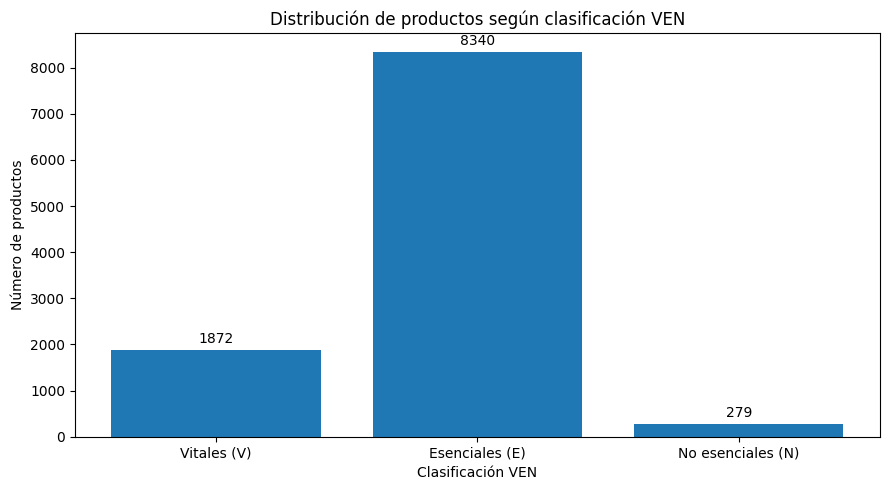

In [181]:
import matplotlib.pyplot as plt

# Datos de clasificación VEN
categorias = ["Vitales (V)", "Esenciales (E)", "No esenciales (N)"]
cantidades = [1872, 8340, 279]

plt.figure(figsize=(9, 5))

barras = plt.bar(categorias, cantidades)

plt.title("Distribución de productos según clasificación VEN")
plt.xlabel("Clasificación VEN")
plt.ylabel("Número de productos")

plt.bar_label(barras, padding=3, fmt="%d")

plt.tight_layout()

plt.savefig(
    "Figura_8_Distribucion_VEN.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

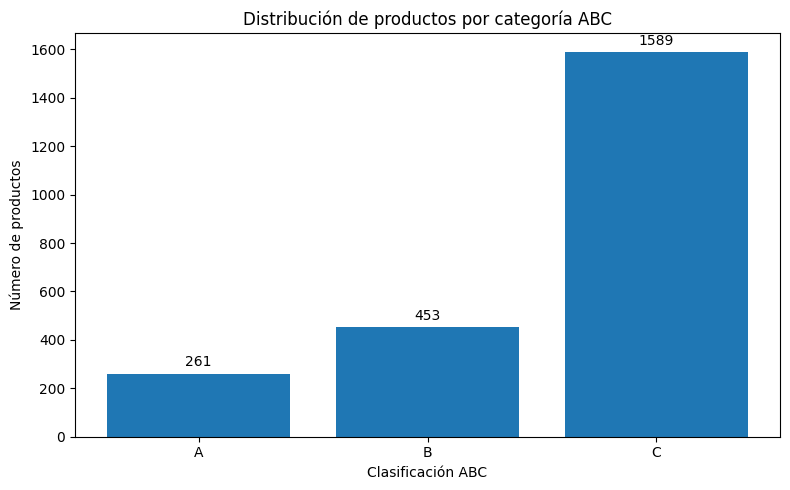

In [182]:
import matplotlib.pyplot as plt

# Datos de clasificación ABC
categorias = ["A", "B", "C"]
productos = [261, 453, 1589]

plt.figure(figsize=(8, 5))

barras = plt.bar(categorias, productos)

plt.title("Distribución de productos por categoría ABC")
plt.xlabel("Clasificación ABC")
plt.ylabel("Número de productos")

plt.bar_label(barras, padding=3, fmt="%d")

plt.tight_layout()

plt.savefig(
    "Figura_9_Distribucion_ABC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

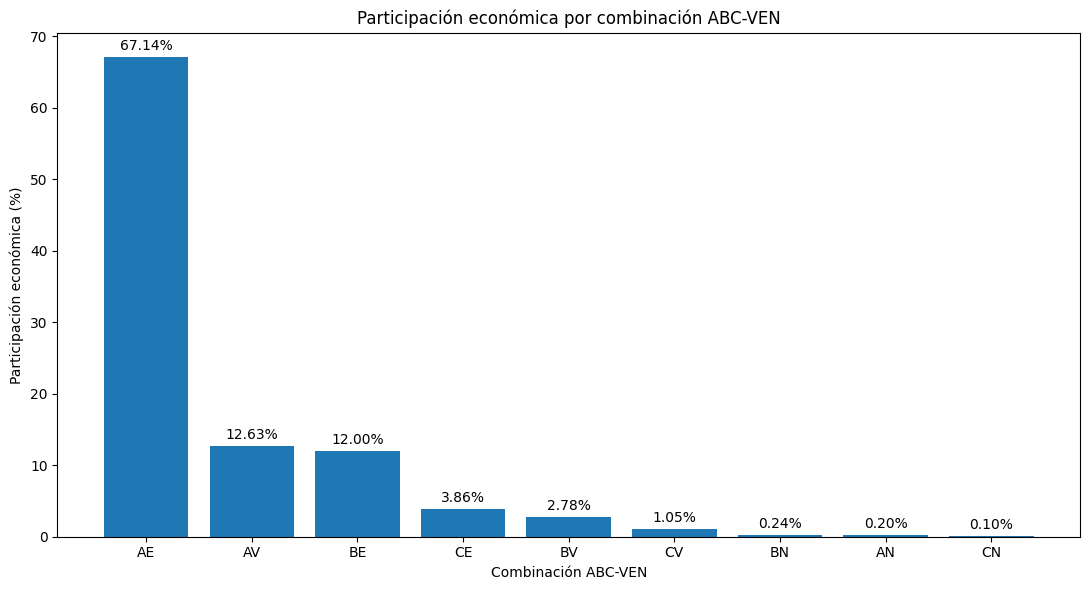

In [183]:
import matplotlib.pyplot as plt

# Participación económica por combinación
combinaciones = [
    "AE", "AV", "BE", "CE", "BV",
    "CV", "BN", "AN", "CN"
]

participacion = [
    67.14, 12.63, 12.00, 3.86, 2.78,
    1.05, 0.24, 0.20, 0.10
]

plt.figure(figsize=(11, 6))

barras = plt.bar(combinaciones, participacion)

plt.title("Participación económica por combinación ABC-VEN")
plt.xlabel("Combinación ABC-VEN")
plt.ylabel("Participación económica (%)")

plt.bar_label(
    barras,
    labels=[f"{valor:.2f}%" for valor in participacion],
    padding=3
)

plt.tight_layout()

plt.savefig(
    "Figura_13_Participacion_economica_ABC_VEN.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [184]:
# Verificar la estructura de la tabla de consumo mensual

print("DIMENSIONES DE LA TABLA:")
print(consumo_mensual_producto.shape)

print("\nCOLUMNAS:")
print(consumo_mensual_producto.columns.tolist())

print("\nPRIMEROS REGISTROS:")
display(consumo_mensual_producto.head())

print("\nÚLTIMOS REGISTROS:")
display(consumo_mensual_producto.tail())

DIMENSIONES DE LA TABLA:
(68888, 4)

COLUMNAS:
['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'PERIODO', 'CANTIDAD']

PRIMEROS REGISTROS:


,CODIGO_PROPIO,DES_MEDICAMENTO,PERIODO,CANTIDAD
0,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2025-12-01,34.0
1,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-01-01,3.0
2,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-02-01,17.0
3,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-03-01,5.0
4,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-04-01,6.0



ÚLTIMOS REGISTROS:


,CODIGO_PROPIO,DES_MEDICAMENTO,PERIODO,CANTIDAD
68883,992505,ESOMEPRAZOL 40 MG TABLETA O TABLETA RECUBIERTA,2025-04-01,141.0
68884,99477,TOGGLELOC CON ZIPLOOP EXT TOGGLELOC REF 131269...,2025-04-01,1.0
68885,9979,CABERGOLINA 0.5 MG TABLETA,2025-04-01,12.0
68886,9983,METOTREXATO SODICO 2.5 MG DE BASE TABLETA,2025-04-01,4.0
68887,9993,DOXICICLINA 100MG TABLETA,2025-04-01,63.0


In [185]:
# Consolidar el consumo histórico total por producto

print("PERIODO ANALIZADO:")
print("Desde:", consumo_mensual_producto["PERIODO"].min())
print("Hasta:", consumo_mensual_producto["PERIODO"].max())
print("Número de periodos:", consumo_mensual_producto["PERIODO"].nunique())

# Sumar las cantidades de todos los meses para cada producto
consumo_historico_producto = (
    consumo_mensual_producto
    .groupby(["CODIGO_PROPIO", "DES_MEDICAMENTO"], as_index=False)
    ["CANTIDAD"]
    .sum()
    .rename(columns={"CANTIDAD": "CONSUMO_HISTORICO"})
)

print("\nRESULTADO DE LA CONSOLIDACIÓN:")
print("Productos con consumo histórico:", len(consumo_historico_producto))
print("Total de unidades consumidas:", consumo_historico_producto["CONSUMO_HISTORICO"].sum())

display(consumo_historico_producto.head())

PERIODO ANALIZADO:
Desde: 2024-01-01 00:00:00
Hasta: 2026-05-01 00:00:00
Número de periodos: 29

RESULTADO DE LA CONSOLIDACIÓN:
Productos con consumo histórico: 11887
Total de unidades consumidas: 47991694.0


,CODIGO_PROPIO,DES_MEDICAMENTO,CONSUMO_HISTORICO
0,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,67.0
1,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),784.0
2,55,ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 6...,1808.0
3,55,ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML,627.0
4,64,ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA,62925.0


In [186]:
# Identificar las tablas de productos y la Biblia institucional

for nombre, objeto in globals().copy().items():
    if isinstance(objeto, pd.DataFrame):
        if "COSTO FINAL" in objeto.columns or "Clasificacion VEN" in objeto.columns:
            print(f"\nTabla: {nombre}")
            print("Dimensiones:", objeto.shape)
            print("Columnas:", objeto.columns.tolist())
            display(objeto.head(3))


Tabla: encabezados
Dimensiones: (0, 11)
Columnas: ['CUM', 'ATC', 'BODEGA', 'CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CONCEPTO', 'EsActivo', 'Motivo Inactivación', 'COSTO FINAL', 'RegistroSanitario', 'Clasificacion VEN']


,CUM,ATC,BODEGA,CODIGO_PROPIO,DES_MEDICAMENTO,CONCEPTO,EsActivo,Motivo Inactivación,COSTO FINAL,RegistroSanitario,Clasificacion VEN



Tabla: biblia
Dimensiones: (50010, 4)
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'COSTO FINAL', 'Clasificacion VEN']


,CODIGO_PROPIO,DES_MEDICAMENTO,COSTO FINAL,Clasificacion VEN
0,63516580,COMPRESA OCULAR REF 2841 KENDALL,420.0,E
1,63516580,COMPRESA OCULAR REF 2841 KENDALL,420.0,E
2,87365,COLISTINA 150 MG AMPOLLA,249823.0,V



Tabla: muestra_costos
Dimensiones: (103, 4)
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'COSTO FINAL', 'Clasificacion VEN']


,CODIGO_PROPIO,DES_MEDICAMENTO,COSTO FINAL,Clasificacion VEN
168,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,24907.0,E
169,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,24907.0,E
170,10,ACEITE MINERAL-PICOSULFATO SODICO X 240ML,17762.0,E


... (40 outputs left out)


Tabla: base_clasificada
Dimensiones: (2303, 7)
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'COSTO FINAL', 'Clasificacion VEN', 'CONSUMO_2025', 'VALOR_CONSUMO_2025', 'CLASIFICACION_ABC']


,CODIGO_PROPIO,DES_MEDICAMENTO,COSTO FINAL,Clasificacion VEN,CONSUMO_2025,VALOR_CONSUMO_2025,CLASIFICACION_ABC
26,1000015,MEDIAS ANTIEMBOLICAS HASTA EL MUSLO TALLA (XL)...,27805.0,E,4.0,111220.0,C
27,100001503,PLACA ELECTROBISTURI SIN CABLE,10150.0,E,2294.0,23284100.0,B
33,1000016,MEDIAS ANTIEMBOLICAS HASTA EL MUSLO TALLA (S) ...,31000.0,E,39.0,1209000.0,C



Tabla: resumen_abc_ven
Dimensiones: (9, 6)
Columnas: ['CLASIFICACION_ABC', 'Clasificacion VEN', 'NUMERO_PRODUCTOS', 'CONSUMO_TOTAL', 'VALOR_ECONOMICO', 'PARTICIPACION_ECONOMICA_%']


,CLASIFICACION_ABC,Clasificacion VEN,NUMERO_PRODUCTOS,CONSUMO_TOTAL,VALOR_ECONOMICO,PARTICIPACION_ECONOMICA_%
0,A,E,204,5070748.0,2.629746e+10,67.141226
2,A,V,56,99679.0,4.945098e+09,12.625552
3,B,E,356,771361.0,4.699091e+09,11.997462


In [187]:
# Validación de la Biblia institucional para el análisis ABC-VEN

print("DIMENSIONES:", biblia_abc.shape)

print("\nCÓDIGOS ÚNICOS:")
print(biblia_abc["CODIGO_PROPIO"].nunique())

print("\nCÓDIGOS DUPLICADOS:")
print(biblia_abc["CODIGO_PROPIO"].duplicated().sum())

print("\nCOSTOS FALTANTES:")
print(biblia_abc["COSTO FINAL"].isna().sum())

print("\nCLASIFICACIONES VEN FALTANTES:")
print(biblia_abc["Clasificacion VEN"].isna().sum())

print("\nDISTRIBUCIÓN VEN:")
print(biblia_abc["Clasificacion VEN"].value_counts(dropna=False))

print("\nTIPOS DE DATOS:")
print(biblia_abc.dtypes)

DIMENSIONES: (10491, 4)

CÓDIGOS ÚNICOS:
10491

CÓDIGOS DUPLICADOS:
0

COSTOS FALTANTES:
405

CLASIFICACIONES VEN FALTANTES:
0

DISTRIBUCIÓN VEN:
Clasificacion VEN
E    8340
V    1872
N     279
Name: count, dtype: int64

TIPOS DE DATOS:
CODIGO_PROPIO         object
DES_MEDICAMENTO       object
COSTO FINAL          float64
Clasificacion VEN     object
dtype: object


In [188]:
# Preparar códigos para el cruce
consumo_cruce = consumo_historico_producto.copy()
biblia_cruce = biblia_abc.copy()

consumo_cruce["CODIGO_PROPIO"] = (
    consumo_cruce["CODIGO_PROPIO"].astype(str).str.strip()
)

biblia_cruce["CODIGO_PROPIO"] = (
    biblia_cruce["CODIGO_PROPIO"].astype(str).str.strip()
)

# Cruzar consumo histórico con la Biblia institucional
diagnostico_cruce = consumo_cruce.merge(
    biblia_cruce[
        ["CODIGO_PROPIO", "COSTO FINAL", "Clasificacion VEN"]
    ],
    on="CODIGO_PROPIO",
    how="left",
    indicator=True,
    validate="one_to_one"
)

# Identificar situaciones
sin_biblia = diagnostico_cruce[
    diagnostico_cruce["_merge"] == "left_only"
]

sin_costo_con_consumo = diagnostico_cruce[
    (diagnostico_cruce["_merge"] == "both") &
    (diagnostico_cruce["COSTO FINAL"].isna())
]

con_costo = diagnostico_cruce[
    (diagnostico_cruce["_merge"] == "both") &
    (diagnostico_cruce["COSTO FINAL"].notna())
]

print("RESULTADOS DEL CRUCE")
print("Productos con consumo histórico:", len(consumo_cruce))
print("Productos encontrados en Biblia:", len(diagnostico_cruce) - len(sin_biblia))
print("Productos sin correspondencia en Biblia:", len(sin_biblia))
print("Productos con consumo y sin costo:", len(sin_costo_con_consumo))
print("Productos con consumo y costo disponible:", len(con_costo))

print("\nCONSUMO DE PRODUCTOS SIN COSTO:")
print(sin_costo_con_consumo["CONSUMO_HISTORICO"].sum())

print("\nDETALLE DE PRODUCTOS CON CONSUMO Y SIN COSTO:")
display(
    sin_costo_con_consumo[
        ["CODIGO_PROPIO", "DES_MEDICAMENTO",
         "CONSUMO_HISTORICO", "Clasificacion VEN"]
    ].sort_values("CONSUMO_HISTORICO", ascending=False)
)

print("\nPRODUCTOS SIN CORRESPONDENCIA EN BIBLIA:")
display(
    sin_biblia[
        ["CODIGO_PROPIO", "DES_MEDICAMENTO", "CONSUMO_HISTORICO"]
    ].head(20)
)

MergeError: Merge keys are not unique in left dataset; not a one-to-one merge

In [189]:
# Identificar códigos repetidos en el consumo histórico

duplicados_consumo = consumo_cruce[
    consumo_cruce.duplicated(
        subset=["CODIGO_PROPIO"],
        keep=False
    )
].sort_values("CODIGO_PROPIO")

print("PRODUCTOS EN LA TABLA:", len(consumo_cruce))
print("CÓDIGOS ÚNICOS:", consumo_cruce["CODIGO_PROPIO"].nunique())
print("REGISTROS CON CÓDIGOS REPETIDOS:", len(duplicados_consumo))
print("CÓDIGOS AFECTADOS:", duplicados_consumo["CODIGO_PROPIO"].nunique())

print("\nEJEMPLOS DE CÓDIGOS REPETIDOS:")
display(duplicados_consumo.head(20))

PRODUCTOS EN LA TABLA: 11887
CÓDIGOS ÚNICOS: 9722
REGISTROS CON CÓDIGOS REPETIDOS: 3964
CÓDIGOS AFECTADOS: 1799

EJEMPLOS DE CÓDIGOS REPETIDOS:


,CODIGO_PROPIO,DES_MEDICAMENTO,CONSUMO_HISTORICO
4567,100001503,PLACA ELECTROBISTURI SIN CABLE,14478.0
10343,100001503,PLACA ELECTROBISTURI SIN CABLE,40.0
4062,1000016,MEDIAS ANTIEMBOLICAS HASTA EL MUSLO TALLA (S) ...,286.0
10344,1000016,MEDIAS ANTIEMBOLICAS HASTA EL MUSLO TALLA (S) ...,2.0
10345,1000017,MEDIAS ANTIEMBOLICAS HASTA EL MUSLO TALLA (L) ...,12.0
4063,1000017,MEDIAS ANTIEMBOLICAS HASTA EL MUSLO TALLA (L) ...,588.0
4064,1000019,FUNDA DE COMPRESION VASCULAR HASTA EL MUSLO TA...,169.0
10346,1000019,FUNDA DE COMPRESION VASCULAR HASTA EL MUSLO TA...,4.0
4066,1000022,FUNDA DE COMPRESION VASCULAR HASTA LA RODILLA ...,1078.0
10347,1000022,FUNDA DE COMPRESION VASCULAR HASTA LA RODILLA ...,6.0


In [190]:
# Consolidar el consumo histórico utilizando únicamente el código propio

consumo_por_codigo = (
    consumo_historico_producto
    .groupby("CODIGO_PROPIO", as_index=False)
    .agg(
        CONSUMO_HISTORICO=("CONSUMO_HISTORICO", "sum"),
        NUM_DESCRIPCIONES=("DES_MEDICAMENTO", "nunique")
    )
)

print("RESULTADO DE LA CONSOLIDACIÓN")
print("Productos por código:", len(consumo_por_codigo))
print("Códigos únicos:", consumo_por_codigo["CODIGO_PROPIO"].nunique())
print("Total unidades consumidas:", consumo_por_codigo["CONSUMO_HISTORICO"].sum())

print("\nCÓDIGOS CON MÁS DE UNA DESCRIPCIÓN:")
print(
    (consumo_por_codigo["NUM_DESCRIPCIONES"] > 1).sum()
)

print("\nVERIFICACIÓN DEL CONSUMO:")
print(
    "Consumo anterior:",
    consumo_historico_producto["CONSUMO_HISTORICO"].sum()
)
print(
    "Consumo consolidado:",
    consumo_por_codigo["CONSUMO_HISTORICO"].sum()
)

display(consumo_por_codigo.head())

RESULTADO DE LA CONSOLIDACIÓN
Productos por código: 11224
Códigos únicos: 11224
Total unidades consumidas: 47991694.0

CÓDIGOS CON MÁS DE UNA DESCRIPCIÓN:
591

VERIFICACIÓN DEL CONSUMO:
Consumo anterior: 47991694.0
Consumo consolidado: 47991694.0


,CODIGO_PROPIO,CONSUMO_HISTORICO,NUM_DESCRIPCIONES
0,11,851.0,2
1,55,2435.0,2
2,64,62925.0,1
3,87,53181.0,1
4,101,5261.0,1


In [191]:
# Cruce del consumo histórico consolidado con la Biblia institucional

consumo_cruce = consumo_por_codigo.copy()
biblia_cruce = biblia_abc.copy()

consumo_cruce["CODIGO_PROPIO"] = (
    consumo_cruce["CODIGO_PROPIO"].astype(str).str.strip()
)

biblia_cruce["CODIGO_PROPIO"] = (
    biblia_cruce["CODIGO_PROPIO"].astype(str).str.strip()
)

diagnostico_cruce = consumo_cruce.merge(
    biblia_cruce[
        ["CODIGO_PROPIO", "DES_MEDICAMENTO",
         "COSTO FINAL", "Clasificacion VEN"]
    ],
    on="CODIGO_PROPIO",
    how="left",
    indicator=True,
    validate="one_to_one",
    suffixes=("_CONSUMO", "_BIBLIA")
)

# Separar los resultados
sin_biblia = diagnostico_cruce[
    diagnostico_cruce["_merge"] == "left_only"
]

sin_costo_con_consumo = diagnostico_cruce[
    (diagnostico_cruce["_merge"] == "both") &
    (diagnostico_cruce["COSTO FINAL"].isna())
]

con_costo = diagnostico_cruce[
    (diagnostico_cruce["_merge"] == "both") &
    (diagnostico_cruce["COSTO FINAL"].notna())
]

print("RESULTADOS DEL CRUCE HISTÓRICO")
print("Códigos con consumo:", len(consumo_cruce))
print("Códigos encontrados en Biblia:", (diagnostico_cruce["_merge"] == "both").sum())
print("Códigos sin correspondencia:", len(sin_biblia))
print("Productos con consumo y sin costo:", len(sin_costo_con_consumo))
print("Productos con consumo y costo:", len(con_costo))

print("\nUNIDADES CONSUMIDAS SIN COSTO:")
print(sin_costo_con_consumo["CONSUMO_HISTORICO"].sum())

print("\nUNIDADES CONSUMIDAS SIN CORRESPONDENCIA:")
print(sin_biblia["CONSUMO_HISTORICO"].sum())

print("\nDETALLE DE PRODUCTOS CON CONSUMO Y SIN COSTO:")
display(
    sin_costo_con_consumo[
        ["CODIGO_PROPIO", "DES_MEDICAMENTO_BIBLIA",
         "CONSUMO_HISTORICO", "Clasificacion VEN"]
    ].head(20)
)

print("\nDETALLE DE CÓDIGOS SIN CORRESPONDENCIA:")
display(
    sin_biblia[
        ["CODIGO_PROPIO", "DES_MEDICAMENTO_CONSUMO",
         "CONSUMO_HISTORICO"]
    ].head(20)
)

MergeError: Merge keys are not unique in left dataset; not a one-to-one merge

In [192]:
# Revisar unicidad de los códigos después de estandarizarlos

consumo_revision = consumo_por_codigo.copy()
biblia_revision = biblia_abc.copy()

consumo_revision["CODIGO_PROPIO"] = (
    consumo_revision["CODIGO_PROPIO"].astype(str).str.strip()
)

biblia_revision["CODIGO_PROPIO"] = (
    biblia_revision["CODIGO_PROPIO"].astype(str).str.strip()
)

print("CONSUMO HISTÓRICO")
print("Registros:", len(consumo_revision))
print("Códigos únicos:", consumo_revision["CODIGO_PROPIO"].nunique())
print("Códigos duplicados:", consumo_revision["CODIGO_PROPIO"].duplicated().sum())

print("\nBIBLIA INSTITUCIONAL")
print("Registros:", len(biblia_revision))
print("Códigos únicos:", biblia_revision["CODIGO_PROPIO"].nunique())
print("Códigos duplicados:", biblia_revision["CODIGO_PROPIO"].duplicated().sum())

print("\nDUPLICADOS EN CONSUMO:")
display(
    consumo_revision[
        consumo_revision["CODIGO_PROPIO"].duplicated(keep=False)
    ].sort_values("CODIGO_PROPIO").head(20)
)

print("\nDUPLICADOS EN BIBLIA:")
display(
    biblia_revision[
        biblia_revision["CODIGO_PROPIO"].duplicated(keep=False)
    ].sort_values("CODIGO_PROPIO").head(20)
)

CONSUMO HISTÓRICO
Registros: 11224
Códigos únicos: 9722
Códigos duplicados: 1502

BIBLIA INSTITUCIONAL
Registros: 10491
Códigos únicos: 10491
Códigos duplicados: 0

DUPLICADOS EN CONSUMO:


,CODIGO_PROPIO,CONSUMO_HISTORICO,NUM_DESCRIPCIONES
9681,100001503,40.0,1
4122,100001503,14478.0,1
3656,1000016,286.0,1
9682,1000016,2.0,1
3657,1000017,588.0,1
9683,1000017,12.0,1
3658,1000019,169.0,1
9684,1000019,4.0,1
3660,1000022,1078.0,1
9685,1000022,6.0,1



DUPLICADOS EN BIBLIA:


,CODIGO_PROPIO,DES_MEDICAMENTO,COSTO FINAL,Clasificacion VEN


In [193]:
# Consolidar consumo por código después de estandarizar la llave

consumo_por_codigo = (
    consumo_revision
    .groupby("CODIGO_PROPIO", as_index=False)
    .agg(
        CONSUMO_HISTORICO=("CONSUMO_HISTORICO", "sum")
    )
)

print("RESULTADO FINAL")
print("Registros:", len(consumo_por_codigo))
print("Códigos únicos:", consumo_por_codigo["CODIGO_PROPIO"].nunique())
print("Total unidades consumidas:", consumo_por_codigo["CONSUMO_HISTORICO"].sum())

print("\nVERIFICACIÓN:")
print(
    "Códigos duplicados:",
    consumo_por_codigo["CODIGO_PROPIO"].duplicated().sum()
)

display(consumo_por_codigo.head())

RESULTADO FINAL
Registros: 9722
Códigos únicos: 9722
Total unidades consumidas: 47991694.0

VERIFICACIÓN:
Códigos duplicados: 0


,CODIGO_PROPIO,CONSUMO_HISTORICO
0,100001357,3.0
1,1000015,15.0
2,100001503,14518.0
3,1000016,288.0
4,1000017,600.0


In [194]:
# Cruce del consumo histórico con la Biblia institucional

diagnostico_cruce = consumo_por_codigo.merge(
    biblia_cruce[
        ["CODIGO_PROPIO", "DES_MEDICAMENTO",
         "COSTO FINAL", "Clasificacion VEN"]
    ],
    on="CODIGO_PROPIO",
    how="left",
    indicator=True,
    validate="one_to_one"
)

# Identificar los resultados del cruce
sin_biblia = diagnostico_cruce[
    diagnostico_cruce["_merge"] == "left_only"
]

sin_costo_con_consumo = diagnostico_cruce[
    (diagnostico_cruce["_merge"] == "both") &
    (diagnostico_cruce["COSTO FINAL"].isna())
]

con_costo = diagnostico_cruce[
    (diagnostico_cruce["_merge"] == "both") &
    (diagnostico_cruce["COSTO FINAL"].notna())
]

print("RESULTADOS DEL CRUCE HISTÓRICO")
print("Productos con consumo:", len(consumo_por_codigo))
print("Productos encontrados en Biblia:", (diagnostico_cruce["_merge"] == "both").sum())
print("Productos sin correspondencia:", len(sin_biblia))
print("Productos con consumo y sin costo:", len(sin_costo_con_consumo))
print("Productos con consumo y costo:", len(con_costo))

print("\nUNIDADES CONSUMIDAS SIN COSTO:")
print(sin_costo_con_consumo["CONSUMO_HISTORICO"].sum())

print("\nUNIDADES CONSUMIDAS SIN CORRESPONDENCIA:")
print(sin_biblia["CONSUMO_HISTORICO"].sum())

print("\nDETALLE DE PRODUCTOS CON CONSUMO Y SIN COSTO:")
display(
    sin_costo_con_consumo[
        ["CODIGO_PROPIO", "DES_MEDICAMENTO",
         "CONSUMO_HISTORICO", "Clasificacion VEN"]
    ].head(20)
)

print("\nDETALLE DE PRODUCTOS SIN CORRESPONDENCIA:")
display(
    sin_biblia[
        ["CODIGO_PROPIO", "CONSUMO_HISTORICO"]
    ].head(20)
)

RESULTADOS DEL CRUCE HISTÓRICO
Productos con consumo: 9722
Productos encontrados en Biblia: 3442
Productos sin correspondencia: 6280
Productos con consumo y sin costo: 0
Productos con consumo y costo: 3442

UNIDADES CONSUMIDAS SIN COSTO:
0.0

UNIDADES CONSUMIDAS SIN CORRESPONDENCIA:
49205.0

DETALLE DE PRODUCTOS CON CONSUMO Y SIN COSTO:


,CODIGO_PROPIO,DES_MEDICAMENTO,CONSUMO_HISTORICO,Clasificacion VEN



DETALLE DE PRODUCTOS SIN CORRESPONDENCIA:


,CODIGO_PROPIO,CONSUMO_HISTORICO
95,100004957,8.0
96,100004958,6.0
97,100004961,3.0
98,100004963,1.0
99,100004964,1.0
100,100004973,1.0
111,100005126,7.0
112,100005127,2.0
117,100005220,80.0
118,100005254,3.0


In [195]:
# Revisar los formatos de los códigos en ambas tablas

print("TIPO DE DATO:")
print("Consumo:", consumo_por_codigo["CODIGO_PROPIO"].dtype)
print("Biblia:", biblia_abc["CODIGO_PROPIO"].dtype)

print("\nEJEMPLOS DE CÓDIGOS EN CONSUMO:")
display(consumo_por_codigo["CODIGO_PROPIO"].head(15))

print("\nEJEMPLOS DE CÓDIGOS EN BIBLIA:")
display(biblia_abc["CODIGO_PROPIO"].head(15))

print("\nEJEMPLOS DE CÓDIGOS SIN CORRESPONDENCIA:")
display(sin_biblia[["CODIGO_PROPIO", "CONSUMO_HISTORICO"]].head(30))

print("\nREVISIÓN DE CÓDIGOS CON DECIMALES EN BIBLIA:")
print(
    biblia_abc[
        biblia_abc["CODIGO_PROPIO"].astype(str).str.contains(r"\.0$", na=False)
    ]["CODIGO_PROPIO"].head(20).tolist()
)

TIPO DE DATO:
Consumo: object
Biblia: object

EJEMPLOS DE CÓDIGOS EN CONSUMO:


,CODIGO_PROPIO
0,100001357
1,1000015
2,100001503
3,1000016
4,1000017
5,1000019
6,1000020
7,1000022
8,100002250
9,100002261



EJEMPLOS DE CÓDIGOS EN BIBLIA:


,CODIGO_PROPIO
0,1
1,10
2,10000047
3,10000048
4,10000049
5,10000050
6,10000051
7,10000052
8,10000135
9,100001356



EJEMPLOS DE CÓDIGOS SIN CORRESPONDENCIA:


,CODIGO_PROPIO,CONSUMO_HISTORICO
95,100004957,8.0
96,100004958,6.0
97,100004961,3.0
98,100004963,1.0
99,100004964,1.0
100,100004973,1.0
111,100005126,7.0
112,100005127,2.0
117,100005220,80.0
118,100005254,3.0



REVISIÓN DE CÓDIGOS CON DECIMALES EN BIBLIA:
[]


In [196]:
# Comprobar coincidencias directas entre las dos tablas

codigos_prueba = ["100001357", "1000015", "100001503", "1000016"]

print("VERIFICACIÓN DE CÓDIGOS INDIVIDUALES")

for codigo in codigos_prueba:
    existe_consumo = (
        consumo_por_codigo["CODIGO_PROPIO"] == codigo
    ).any()

    existe_biblia = (
        biblia_abc["CODIGO_PROPIO"].astype(str).str.strip() == codigo
    ).any()

    print(
        f"Código: {codigo} | "
        f"Consumo: {existe_consumo} | "
        f"Biblia: {existe_biblia}"
    )

print("\nCOMPARACIÓN GENERAL")

codigos_consumo = set(
    consumo_por_codigo["CODIGO_PROPIO"].astype(str).str.strip()
)

codigos_biblia = set(
    biblia_abc["CODIGO_PROPIO"].astype(str).str.strip()
)

print("Códigos en consumo:", len(codigos_consumo))
print("Códigos en Biblia:", len(codigos_biblia))
print("Códigos coincidentes:", len(codigos_consumo.intersection(codigos_biblia)))
print("Códigos exclusivos del consumo:", len(codigos_consumo - codigos_biblia))

VERIFICACIÓN DE CÓDIGOS INDIVIDUALES
Código: 100001357 | Consumo: True | Biblia: True
Código: 1000015 | Consumo: True | Biblia: True
Código: 100001503 | Consumo: True | Biblia: True
Código: 1000016 | Consumo: True | Biblia: True

COMPARACIÓN GENERAL
Códigos en consumo: 9722
Códigos en Biblia: 10491
Códigos coincidentes: 3442
Códigos exclusivos del consumo: 6280


In [197]:
# Recuperar las descripciones de los códigos que no aparecen en la Biblia

detalle_sin_biblia = (
    consumo_historico_producto[
        consumo_historico_producto["CODIGO_PROPIO"].astype(str).str.strip().isin(
            codigos_consumo - codigos_biblia
        )
    ]
    .sort_values("CONSUMO_HISTORICO", ascending=False)
)

print("PRODUCTOS SIN CORRESPONDENCIA EN LA BIBLIA")
print("Registros:", len(detalle_sin_biblia))
print(
    "Unidades consumidas:",
    detalle_sin_biblia["CONSUMO_HISTORICO"].sum()
)

print("\n30 PRODUCTOS CON MAYOR CONSUMO:")
display(detalle_sin_biblia.head(30))

print("\nRESUMEN DEL CONSUMO:")
print(detalle_sin_biblia["CONSUMO_HISTORICO"].describe())

PRODUCTOS SIN CORRESPONDENCIA EN LA BIBLIA
Registros: 6633
Unidades consumidas: 49205.0

30 PRODUCTOS CON MAYOR CONSUMO:


,CODIGO_PROPIO,DES_MEDICAMENTO,CONSUMO_HISTORICO
3553,117679,TORNILLO HEXADRIVE 1.5 X 05MM SPEEDTIP REF 251...,1080.0
3378,112265,TORNILLO MAXDRIVE DFS-SCH 1.5MM X 5 MM REF 25-...,1069.0
2705,87746,ROTULA PORTA SCHANZ DE 11 MM TI REF 5040010007,672.0
6947,100017315,TORNILLO DORADO 1.3 X 4MM REF 241.011304,511.0
3552,117678,TORNILLO HEXADRIVE 1.5 X 04MM SPEEDTIP REF 251...,471.0
5622,100014074,SPEEDYFLAP DIAMETRO 16MM REF 12126SF-16F.,407.0
3554,117680,TORNILLO HEXADRIVE 1.5 X 06MM SPEEDTIP REF 251...,397.0
5945,100015118,TORNILLO 2.4 X 10 + MM (A-P) RIBFIX BLU REF 76...,373.0
6048,100015368,TUERCA M6 S REF 64161610,364.0
7016,100017448,TUERCA DE BLOQUEO ANYPLUS REF 0954-0002,355.0



RESUMEN DEL CONSUMO:
count    6633.000000
mean        7.418212
std        30.299599
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max      1080.000000
Name: CONSUMO_HISTORICO, dtype: float64


In [198]:
# Construir la base histórica definitiva para ABC-VEN
# Se excluyen los códigos MOS que no están en la Biblia institucional

base_abc_historica = diagnostico_cruce[
    (diagnostico_cruce["_merge"] == "both") &
    (diagnostico_cruce["COSTO FINAL"].notna())
].copy()

# Retirar columna auxiliar del cruce
base_abc_historica.drop(columns=["_merge"], inplace=True)

# Calcular valor económico histórico
base_abc_historica["VALOR_CONSUMO_HISTORICO"] = (
    base_abc_historica["CONSUMO_HISTORICO"] *
    base_abc_historica["COSTO FINAL"]
)

print("BASE HISTÓRICA DEPURADA PARA ABC-VEN")
print("Productos:", len(base_abc_historica))
print("Códigos únicos:", base_abc_historica["CODIGO_PROPIO"].nunique())
print("Productos sin costo:", base_abc_historica["COSTO FINAL"].isna().sum())
print("Productos sin clasificación VEN:", base_abc_historica["Clasificacion VEN"].isna().sum())

print("\nCONSUMO:")
print("Unidades conservadas:", base_abc_historica["CONSUMO_HISTORICO"].sum())

print("\nVALOR ECONÓMICO HISTÓRICO:")
print(
    f"${base_abc_historica['VALOR_CONSUMO_HISTORICO'].sum():,.0f} COP"
)

print("\nPRIMEROS REGISTROS:")
display(base_abc_historica.head())

BASE HISTÓRICA DEPURADA PARA ABC-VEN
Productos: 3442
Códigos únicos: 3442
Productos sin costo: 0
Productos sin clasificación VEN: 0

CONSUMO:
Unidades conservadas: 47942489.0

VALOR ECONÓMICO HISTÓRICO:
$214,512,421,451 COP

PRIMEROS REGISTROS:


,CODIGO_PROPIO,CONSUMO_HISTORICO,DES_MEDICAMENTO,COSTO FINAL,Clasificacion VEN,VALOR_CONSUMO_HISTORICO
0,100001357,3.0,DISPOSITIVO INTRAUTERINO T DE COBRE,6163.0,E,18489.0
1,1000015,15.0,MEDIAS ANTIEMBOLICAS HASTA EL MUSLO TALLA (XL)...,27805.0,E,417075.0
2,100001503,14518.0,PLACA ELECTROBISTURI SIN CABLE,10150.0,E,147357700.0
3,1000016,288.0,MEDIAS ANTIEMBOLICAS HASTA EL MUSLO TALLA (S) ...,31000.0,E,8928000.0
4,1000017,600.0,MEDIAS ANTIEMBOLICAS HASTA EL MUSLO TALLA (L) ...,31000.0,E,18600000.0


In [199]:
# PASO 12. Clasificación ABC del consumo histórico (enero 2024 - mayo 2026)

# Ordenar productos por valor económico de mayor a menor
abc_historica = base_abc_historica.sort_values(
    "VALOR_CONSUMO_HISTORICO",
    ascending=False
).copy()

# Calcular participación individual
valor_total_historico = abc_historica["VALOR_CONSUMO_HISTORICO"].sum()

abc_historica["PARTICIPACION_%"] = (
    abc_historica["VALOR_CONSUMO_HISTORICO"] /
    valor_total_historico
) * 100

# Calcular participación acumulada
abc_historica["PARTICIPACION_ACUMULADA_%"] = (
    abc_historica["PARTICIPACION_%"].cumsum()
)

# Clasificación ABC
abc_historica["CLASIFICACION_ABC"] = "C"

abc_historica.loc[
    abc_historica["PARTICIPACION_ACUMULADA_%"] <= 80,
    "CLASIFICACION_ABC"
] = "A"

abc_historica.loc[
    (abc_historica["PARTICIPACION_ACUMULADA_%"] > 80) &
    (abc_historica["PARTICIPACION_ACUMULADA_%"] <= 95),
    "CLASIFICACION_ABC"
] = "B"

# Resumen de clasificación
resumen_abc_historica = (
    abc_historica.groupby("CLASIFICACION_ABC")
    .agg(
        PRODUCTOS=("CODIGO_PROPIO", "count"),
        VALOR_ECONOMICO=("VALOR_CONSUMO_HISTORICO", "sum"),
        CONSUMO_UNIDADES=("CONSUMO_HISTORICO", "sum")
    )
    .reset_index()
)

resumen_abc_historica["PARTICIPACION_PRODUCTOS_%"] = (
    resumen_abc_historica["PRODUCTOS"] /
    len(abc_historica) * 100
)

resumen_abc_historica["PARTICIPACION_ECONOMICA_%"] = (
    resumen_abc_historica["VALOR_ECONOMICO"] /
    valor_total_historico * 100
)

print("CLASIFICACIÓN ABC HISTÓRICA")
print("Periodo: enero 2024 - mayo 2026")
print("Total productos:", len(abc_historica))
print(f"Valor económico: ${valor_total_historico:,.0f} COP")

display(resumen_abc_historica.round(2))

print("\nPRIMEROS 15 PRODUCTOS CLASIFICADOS:")
display(
    abc_historica[
        [
            "CODIGO_PROPIO",
            "DES_MEDICAMENTO",
            "CONSUMO_HISTORICO",
            "COSTO FINAL",
            "VALOR_CONSUMO_HISTORICO",
            "PARTICIPACION_%",
            "PARTICIPACION_ACUMULADA_%",
            "CLASIFICACION_ABC"
        ]
    ].head(15)
)

CLASIFICACIÓN ABC HISTÓRICA
Periodo: enero 2024 - mayo 2026
Total productos: 3442
Valor económico: $214,512,421,451 COP


,CLASIFICACION_ABC,PRODUCTOS,VALOR_ECONOMICO,CONSUMO_UNIDADES,PARTICIPACION_PRODUCTOS_%,PARTICIPACION_ECONOMICA_%
0,A,309,1.715467e+11,37208354.0,8.98,79.97
1,B,574,3.222459e+10,6659516.0,16.68,15.02
2,C,2559,1.074110e+10,4074619.0,74.35,5.01



PRIMEROS 15 PRODUCTOS CLASIFICADOS:


,CODIGO_PROPIO,DES_MEDICAMENTO,CONSUMO_HISTORICO,COSTO FINAL,VALOR_CONSUMO_HISTORICO,PARTICIPACION_%,PARTICIPACION_ACUMULADA_%,CLASIFICACION_ABC
629,100009884,PEMBROLIZUMAB 100 MG/4 ML SOLUCION INYECTABLE,468.0,12731111.0,5.958160e+09,2.777536,2.777536,A
2293,100017418,DARATUMUMAB SC 120 MG/ML SOLUCION INYECTABLE ...,299.0,14950000.0,4.470050e+09,2.083819,4.861355,A
898,100013754,CEFTAZIDIMA - AVIBACTAM 2 G + 0.5 G POLVO PAR...,9923.0,402000.0,3.989046e+09,1.859587,6.720942,A
1778,100016354,INMUNOGLOBULINA HUMANA IGG X 5G (5%) X 100ML S...,4340.0,860000.0,3.732400e+09,1.739946,8.460888,A
1598,100015961,DURVALUMAB 50 MG/ML SOLUCION CONCENTRADA PARA ...,322.0,10581633.0,3.407286e+09,1.588386,10.049274,A
234,100005945,NIVOLUMAB (EQ. A 10MG/ML) SOLUCION INYECTABLE ...,556.0,5973983.0,3.321535e+09,1.548411,11.597686,A
7354,30384,EQUIPO BOMBA DE INFUSION 5000XL REF 1642-48 (R...,112757.0,29400.0,3.315056e+09,1.545391,13.143077,A
6688,2126160,BRENTUXIMAB VEDOTINA 50 MG POLVO PARA RECONSTI...,239.0,13623533.0,3.256024e+09,1.517872,14.660949,A
5857,10586,INSULINA CRISTALINA (HUMANA) 100 UI/ML 10 ML S...,181872.0,17875.0,3.250962e+09,1.515512,16.176461,A
8040,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,1093129.0,2904.0,3.174447e+09,1.479843,17.656304,A


In [200]:
# PASO 13. Integración de las clasificaciones ABC y VEN

# Verificar que cada producto tenga ambas clasificaciones
print("CLASIFICACIONES DISPONIBLES:")
print("ABC:", abc_historica["CLASIFICACION_ABC"].value_counts().to_dict())
print("VEN:", abc_historica["Clasificacion VEN"].value_counts().to_dict())

# Construir matriz ABC-VEN
matriz_abc_ven = pd.crosstab(
    abc_historica["CLASIFICACION_ABC"],
    abc_historica["Clasificacion VEN"],
    margins=True,
    margins_name="TOTAL"
)

print("\nMATRIZ ABC-VEN - CANTIDAD DE PRODUCTOS")
display(matriz_abc_ven)

# Calcular porcentajes sobre el total de productos
matriz_porcentajes = (
    pd.crosstab(
        abc_historica["CLASIFICACION_ABC"],
        abc_historica["Clasificacion VEN"]
    ) / len(abc_historica) * 100
)

print("\nMATRIZ ABC-VEN - PARTICIPACIÓN SOBRE EL TOTAL (%)")
display(matriz_porcentajes.round(2))

CLASIFICACIONES DISPONIBLES:
ABC: {'C': 2559, 'B': 574, 'A': 309}
VEN: {'E': 2650, 'V': 741, 'N': 51}

MATRIZ ABC-VEN - CANTIDAD DE PRODUCTOS


Clasificacion VEN,E,N,V,TOTAL
CLASIFICACION_ABC,,,,
A,243,2,64,309
B,459,7,108,574
C,1948,42,569,2559
TOTAL,2650,51,741,3442



MATRIZ ABC-VEN - PARTICIPACIÓN SOBRE EL TOTAL (%)


Clasificacion VEN,E,N,V
CLASIFICACION_ABC,,,
A,7.06,0.06,1.86
B,13.34,0.20,3.14
C,56.60,1.22,16.53


In [201]:
# Resumen económico de la matriz ABC-VEN

resumen_economico_abc_ven = (
    abc_historica
    .groupby(
        ["CLASIFICACION_ABC", "Clasificacion VEN"],
        as_index=False
    )
    .agg(
        PRODUCTOS=("CODIGO_PROPIO", "count"),
        CONSUMO_UNIDADES=("CONSUMO_HISTORICO", "sum"),
        VALOR_ECONOMICO=("VALOR_CONSUMO_HISTORICO", "sum")
    )
)

# Participación económica sobre el valor histórico total
resumen_economico_abc_ven["PARTICIPACION_ECONOMICA_%"] = (
    resumen_economico_abc_ven["VALOR_ECONOMICO"] /
    abc_historica["VALOR_CONSUMO_HISTORICO"].sum()
) * 100

# Ordenar las combinaciones
resumen_economico_abc_ven["COMBINACION"] = (
    resumen_economico_abc_ven["CLASIFICACION_ABC"] +
    resumen_economico_abc_ven["Clasificacion VEN"]
)

resumen_economico_abc_ven = (
    resumen_economico_abc_ven
    .sort_values("VALOR_ECONOMICO", ascending=False)
)

print("RESUMEN ECONÓMICO ABC-VEN")
display(
    resumen_economico_abc_ven[
        [
            "COMBINACION",
            "PRODUCTOS",
            "CONSUMO_UNIDADES",
            "VALOR_ECONOMICO",
            "PARTICIPACION_ECONOMICA_%"
        ]
    ].round(2)
)

print("\nVALOR ECONÓMICO TOTAL:")
print(
    f"${resumen_economico_abc_ven['VALOR_ECONOMICO'].sum():,.0f} COP"
)

RESUMEN ECONÓMICO ABC-VEN


,COMBINACION,PRODUCTOS,CONSUMO_UNIDADES,VALOR_ECONOMICO,PARTICIPACION_ECONOMICA_%
0,AE,243,30665449.0,1.442728e+11,67.26
2,AV,64,726365.0,2.669322e+10,12.44
3,BE,459,6165971.0,2.601253e+10,12.13
6,CE,1948,3858989.0,8.156527e+09,3.80
5,BV,108,222693.0,5.863764e+09,2.73
8,CV,569,123019.0,2.330860e+09,1.09
1,AN,2,5816540.0,5.807487e+08,0.27
4,BN,7,270852.0,3.482915e+08,0.16
7,CN,42,92611.0,2.537119e+08,0.12



VALOR ECONÓMICO TOTAL:
$214,512,421,451 COP


In [202]:
# Validación de la matriz económica ABC-VEN

print("VALIDACIÓN DE RESULTADOS ABC-VEN")

print("\n1. CANTIDAD DE PRODUCTOS")
print("Base histórica:", len(abc_historica))
print("Matriz ABC-VEN:", resumen_economico_abc_ven["PRODUCTOS"].sum())

print("\n2. UNIDADES CONSUMIDAS")
print("Base histórica:", abc_historica["CONSUMO_HISTORICO"].sum())
print("Matriz ABC-VEN:", resumen_economico_abc_ven["CONSUMO_UNIDADES"].sum())

print("\n3. VALOR ECONÓMICO")
print(
    "Base histórica:",
    abc_historica["VALOR_CONSUMO_HISTORICO"].sum()
)
print(
    "Matriz ABC-VEN:",
    resumen_economico_abc_ven["VALOR_ECONOMICO"].sum()
)

print("\n4. PARTICIPACIÓN ECONÓMICA")
print(
    "Total:",
    resumen_economico_abc_ven["PARTICIPACION_ECONOMICA_%"].sum()
)

print("\n5. DIFERENCIAS")

print(
    "Diferencia en productos:",
    len(abc_historica) - resumen_economico_abc_ven["PRODUCTOS"].sum()
)

print(
    "Diferencia en unidades:",
    abc_historica["CONSUMO_HISTORICO"].sum()
    - resumen_economico_abc_ven["CONSUMO_UNIDADES"].sum()
)

print(
    "Diferencia económica:",
    abc_historica["VALOR_CONSUMO_HISTORICO"].sum()
    - resumen_economico_abc_ven["VALOR_ECONOMICO"].sum()
)

VALIDACIÓN DE RESULTADOS ABC-VEN

1. CANTIDAD DE PRODUCTOS
Base histórica: 3442
Matriz ABC-VEN: 3442

2. UNIDADES CONSUMIDAS
Base histórica: 47942489.0
Matriz ABC-VEN: 47942489.0

3. VALOR ECONÓMICO
Base histórica: 214512421451.0
Matriz ABC-VEN: 214512421451.0

4. PARTICIPACIÓN ECONÓMICA
Total: 100.00000000000001

5. DIFERENCIAS
Diferencia en productos: 0
Diferencia en unidades: 0.0
Diferencia económica: 0.0


In [203]:
# Tabla económica ABC-VEN para el documento académico

tabla_economica_final = resumen_economico_abc_ven[
    [
        "COMBINACION",
        "PRODUCTOS",
        "CONSUMO_UNIDADES",
        "VALOR_ECONOMICO",
        "PARTICIPACION_ECONOMICA_%"
    ]
].copy()

tabla_economica_final = tabla_economica_final.sort_values(
    "VALOR_ECONOMICO",
    ascending=False
)

# Formatear valores para presentación
tabla_economica_final["VALOR_ECONOMICO_COP"] = (
    tabla_economica_final["VALOR_ECONOMICO"]
    .map(lambda x: f"$ {x:,.0f}")
)

tabla_economica_final["PARTICIPACION_ECONOMICA_%"] = (
    tabla_economica_final["PARTICIPACION_ECONOMICA_%"]
    .map(lambda x: f"{x:.2f}%")
)

tabla_economica_final["CONSUMO_UNIDADES"] = (
    tabla_economica_final["CONSUMO_UNIDADES"]
    .map(lambda x: f"{x:,.0f}")
)

print("TABLA ECONÓMICA ABC-VEN PARA EL DOCUMENTO")
display(
    tabla_economica_final[
        [
            "COMBINACION",
            "PRODUCTOS",
            "CONSUMO_UNIDADES",
            "VALOR_ECONOMICO_COP",
            "PARTICIPACION_ECONOMICA_%"
        ]
    ]
)

TABLA ECONÓMICA ABC-VEN PARA EL DOCUMENTO


,COMBINACION,PRODUCTOS,CONSUMO_UNIDADES,VALOR_ECONOMICO_COP,PARTICIPACION_ECONOMICA_%
0,AE,243,"30,665,449","$ 144,272,767,758",67.26%
2,AV,64,"726,365","$ 26,693,220,819",12.44%
3,BE,459,"6,165,971","$ 26,012,530,249",12.13%
6,CE,1948,"3,858,989","$ 8,156,527,177",3.80%
5,BV,108,"222,693","$ 5,863,763,559",2.73%
8,CV,569,"123,019","$ 2,330,859,750",1.09%
1,AN,2,"5,816,540","$ 580,748,745",0.27%
4,BN,7,"270,852","$ 348,291,500",0.16%
7,CN,42,"92,611","$ 253,711,894",0.12%


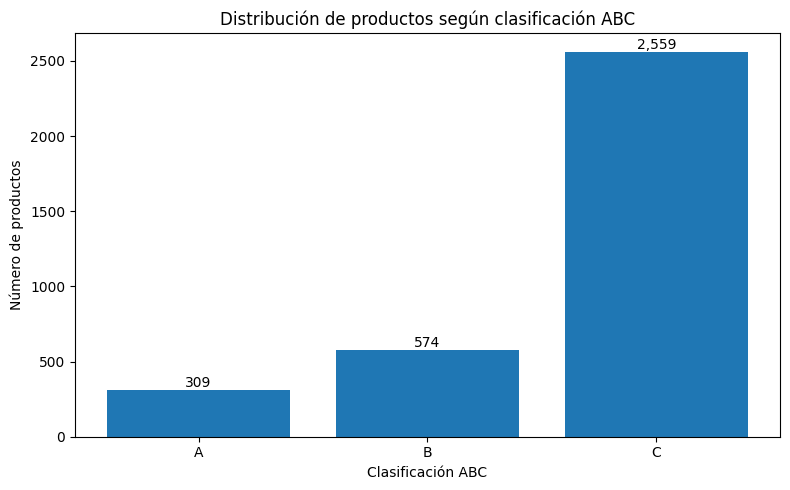

In [204]:
import matplotlib.pyplot as plt

categorias = ['A', 'B', 'C']
productos = [309, 574, 2559]

plt.figure(figsize=(8, 5))
plt.bar(categorias, productos)

plt.title('Distribución de productos según clasificación ABC')
plt.xlabel('Clasificación ABC')
plt.ylabel('Número de productos')

for i, valor in enumerate(productos):
    plt.text(i, valor, f'{valor:,}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

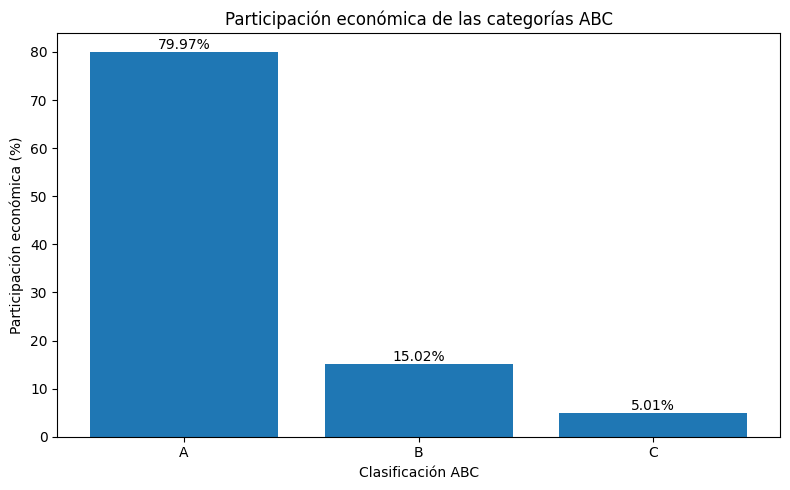

In [205]:
categorias = ['A', 'B', 'C']
participacion = [79.97, 15.02, 5.01]

plt.figure(figsize=(8, 5))
plt.bar(categorias, participacion)

plt.title('Participación económica de las categorías ABC')
plt.xlabel('Clasificación ABC')
plt.ylabel('Participación económica (%)')

for i, valor in enumerate(participacion):
    plt.text(i, valor, f'{valor:.2f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

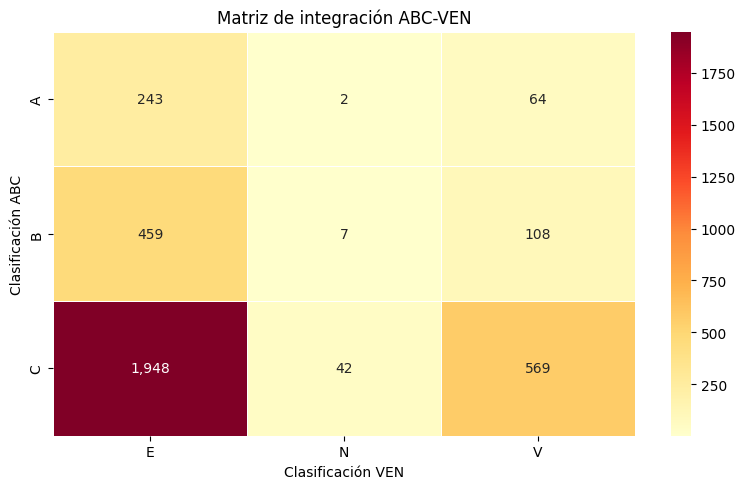

In [206]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

matriz = pd.DataFrame(
    [[243, 2, 64],
     [459, 7, 108],
     [1948, 42, 569]],
    index=['A', 'B', 'C'],
    columns=['E', 'N', 'V']
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt=',',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Matriz de integración ABC-VEN')
plt.xlabel('Clasificación VEN')
plt.ylabel('Clasificación ABC')

plt.tight_layout()
plt.show()

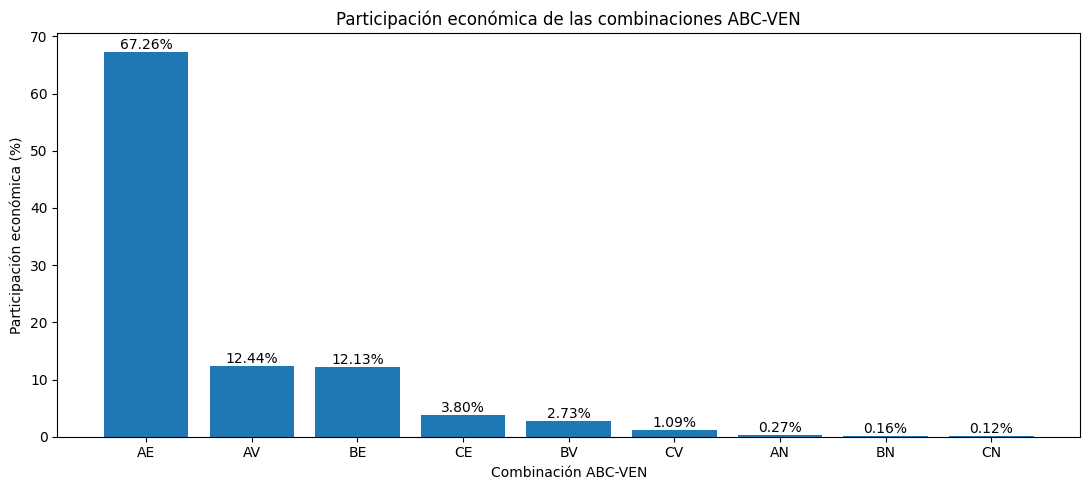

In [207]:
combinaciones = ['AE', 'AV', 'BE', 'CE', 'BV', 'CV', 'AN', 'BN', 'CN']

participacion = [
    67.26, 12.44, 12.13, 3.80,
    2.73, 1.09, 0.27, 0.16, 0.12
]

plt.figure(figsize=(11, 5))

plt.bar(combinaciones, participacion)

plt.title('Participación económica de las combinaciones ABC-VEN')
plt.xlabel('Combinación ABC-VEN')
plt.ylabel('Participación económica (%)')

for i, valor in enumerate(participacion):
    plt.text(i, valor, f'{valor:.2f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [208]:
# REVISIÓN DE TABLAS DISPONIBLES PARA EL OBJETIVO 3

print("TABLA DE CONSUMO MENSUAL")
print("Dimensiones:", consumo_mensual_producto.shape)
print("Columnas:", consumo_mensual_producto.columns.tolist())
display(consumo_mensual_producto.head())

print("\nTABLA DE VARIABILIDAD")
print("Dimensiones:", variabilidad_productos.shape)
print("Columnas:", variabilidad_productos.columns.tolist())
display(variabilidad_productos.head())

TABLA DE CONSUMO MENSUAL
Dimensiones: (68888, 4)
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'PERIODO', 'CANTIDAD']


,CODIGO_PROPIO,DES_MEDICAMENTO,PERIODO,CANTIDAD
0,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2025-12-01,34.0
1,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-01-01,3.0
2,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-02-01,17.0
3,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-03-01,5.0
4,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-04-01,6.0



TABLA DE VARIABILIDAD
Dimensiones: (11887, 36)
Columnas: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', Timestamp('2024-01-01 00:00:00'), Timestamp('2024-02-01 00:00:00'), Timestamp('2024-03-01 00:00:00'), Timestamp('2024-04-01 00:00:00'), Timestamp('2024-05-01 00:00:00'), Timestamp('2024-06-01 00:00:00'), Timestamp('2024-07-01 00:00:00'), Timestamp('2024-08-01 00:00:00'), Timestamp('2024-09-01 00:00:00'), Timestamp('2024-10-01 00:00:00'), Timestamp('2024-11-01 00:00:00'), Timestamp('2024-12-01 00:00:00'), Timestamp('2025-01-01 00:00:00'), Timestamp('2025-02-01 00:00:00'), Timestamp('2025-03-01 00:00:00'), Timestamp('2025-04-01 00:00:00'), Timestamp('2025-05-01 00:00:00'), Timestamp('2025-06-01 00:00:00'), Timestamp('2025-07-01 00:00:00'), Timestamp('2025-08-01 00:00:00'), Timestamp('2025-09-01 00:00:00'), Timestamp('2025-10-01 00:00:00'), Timestamp('2025-11-01 00:00:00'), Timestamp('2025-12-01 00:00:00'), Timestamp('2026-01-01 00:00:00'), Timestamp('2026-02-01 00:00:00'), Timestamp('2026-03-01

,CODIGO_PROPIO,DES_MEDICAMENTO,2024-01-01 00:00:00,2024-02-01 00:00:00,2024-03-01 00:00:00,2024-04-01 00:00:00,2024-05-01 00:00:00,2024-06-01 00:00:00,2024-07-01 00:00:00,2024-08-01 00:00:00,...,2026-01-01 00:00:00,2026-02-01 00:00:00,2026-03-01 00:00:00,2026-04-01 00:00:00,2026-05-01 00:00:00,Promedio_mensual,Desviacion_estandar,CV_%,Rango_CV,Patron_frecuencia
0,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,3.0,17.0,5.0,6.0,2.0,2.310345,6.980091,302.123356,300-400%,Consumo intermitente
1,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),8.0,35.0,43.0,34.0,29.0,48.0,32.0,43.0,...,0.0,0.0,0.0,0.0,0.0,27.034483,18.399307,68.058660,50-100%,Consumo frecuente
2,55,ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 6...,107.0,140.0,143.0,135.0,139.0,150.0,143.0,137.0,...,0.0,0.0,0.0,0.0,0.0,62.344828,60.326064,96.761939,50-100%,Consumo frecuente
3,55,ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,52.0,54.0,121.0,61.0,40.0,21.620690,33.744220,156.073747,100-200%,Consumo intermitente
4,64,ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA,3827.0,3028.0,3499.0,3944.0,2855.0,4077.0,4278.0,4453.0,...,171.0,196.0,414.0,2751.0,1868.0,2169.827586,1423.493792,65.604005,50-100%,Consumo sostenido


In [209]:
# IDENTIFICAR BASES DE DATOS DISPONIBLES

for nombre, objeto in globals().copy().items():
    if isinstance(objeto, pd.DataFrame):
        if any(palabra in nombre.lower() for palabra in [
            "abc", "ven", "historica", "clasificada",
            "consumo", "variabilidad"
        ]):
            print(f"\nVARIABLE: {nombre}")
            print("DIMENSIONES:", objeto.shape)
            print("COLUMNAS:", objeto.columns.tolist())


VARIABLE: base_historica
DIMENSIONES: (11341686, 11)
COLUMNAS: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'CANTIDAD', 'BODEGA', 'DES_UF', 'MES', 'AÑO', 'MES_NUMERO', 'PERIODO', 'BODEGA_KEY', 'SERVICIO_FARMACEUTICO']

VARIABLE: consumo_mensual
DIMENSIONES: (29, 2)
COLUMNAS: ['PERIODO', 'CANTIDAD']

VARIABLE: consumo_anual
DIMENSIONES: (4355, 2)
COLUMNAS: ['CODIGO_PROPIO', 'CONSUMO_2025']

VARIABLE: consumo_ene_may
DIMENSIONES: (3, 3)
COLUMNAS: ['AÑO', 'Consumo_total', 'Promedio_mensual']

VARIABLE: consumo_por_sf
DIMENSIONES: (8, 4)
COLUMNAS: ['SERVICIO_FARMACEUTICO', 'Registros', 'Consumo_total', 'Participacion_%']

VARIABLE: consumo_por_patron
DIMENSIONES: (4, 4)
COLUMNAS: ['Patron_frecuencia', 'Numero_productos', 'Consumo_total', 'Participacion_consumo_%']

VARIABLE: consumo_mensual_producto
DIMENSIONES: (68888, 4)
COLUMNAS: ['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'PERIODO', 'CANTIDAD']

VARIABLE: matriz_consumo
DIMENSIONES: (11887, 29)
COLUMNAS: [Timestamp('2024-01-01 00:00:00'), Timestamp(